<a href="https://colab.research.google.com/github/SamDerden/SpeechSense/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22ru_sentiment_pipeline_adapted_gzip_robust_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Классификация тональности: объединённый русский датасет

**Датасет:** `merged_sentiment_dataset.csv.gz` (поддерживается и `.csv`)  
**Задача:** трёхклассовая классификация тональности: `0` — нейтральный, `1` — позитивный, `2` — негативный.

Ноутбук адаптирован под структуру предоставленного CSV (224 тыс. строк, поля `text`, `sentiment`, `split` и метаданные источника). В отличие от исходного варианта, данные не загружаются с Hugging Face: используется локальный CSV.

| Блок | Что делаем |
|---|---|
| 1 | Загружаем CSV, проверяем столбцы и распределения, исследуем тексты |
| 2 | Очищаем текст и удаляем дубликаты только внутри каждого split |
| 3 | Используем готовые `train` и `validation` из файла |
| 4 | Сравниваем BoW, бинарный BoW, TF-IDF и word+char n-граммы с классическими классификаторами |
| 5 | Сравниваем macro-F1 и accuracy, смотрим отчёт и матрицу ошибок лучшей модели |

**Основная метрика — macro-F1**, чтобы учитывать каждый класс. Accuracy выводится дополнительно.

**Важное замечание о данных:** в `label_source` указано происхождение разметки. Часть обучающих примеров (`filtered`) получила метку по рейтингу 1–2 / 3 / 4–5, а validation содержит исходную разметку. Поэтому итоговые метрики стоит интерпретировать с учётом возможного сдвига между источниками.

N-грамма — это последовательность из N соседних элементов текста. Этими элементами могут быть слова, буквы, слоги или звуки — в зависимости от задачи и контекста.

---
## EDA: обзор датасета

Сначала смотрим на данные (распределение классов, длины, примеры), затем — очистка.


## 0. Окружение

In [ ]:
!pip install -q scikit-learn pandas matplotlib seaborn

import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 150)
sns.set_style("whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CLASS_MAP = {0: "Нейтральный", 1: "Позитивный", 2: "Негативный"}
CLASS_ORDER = [0, 1, 2]
CLASS_NAMES = [CLASS_MAP[i] for i in CLASS_ORDER]

# Сюда складываем результаты всех моделей
LEADERBOARD = []

def report(name, y_true, y_pred, train_time, group="классика"):
    """Считает метрики на отложенной validation-выборке."""
    f1 = f1_score(y_true, y_pred, average="macro")
    acc = accuracy_score(y_true, y_pred)
    LEADERBOARD.append({
        "группа": group,
        "модель": name,
        "macro-F1": round(f1, 4),
        "accuracy": round(acc, 4),
        "обучение, с": round(train_time, 1)
    })
    print(f"{name:50s}  macro-F1={f1:.4f}  acc={acc:.4f}  ({train_time:.1f} с)")
    return f1


---
## 1. Данные: `merged_sentiment_dataset.csv.gz`

Ноутбук читает как обычный CSV, так и настоящий gzip-архив. Перед чтением он проверяет сигнатуру файла, чтобы не пытаться распаковать обычный CSV только потому, что в имени есть `.gz`. Если архив повреждён, выводится понятная ошибка; при наличии рядом исходного CSV предусмотрен автоматический переход на него.

В датасете уже есть поле `split`: обучающая часть (`train`) и отложенная проверочная часть (`validation`). Это разбиение сохраняется.


In [ ]:
# Ищем архив или обычный CSV в типичных местах (Colab или рядом с ноутбуком).
from pathlib import Path
import zlib

CANDIDATE_PATHS = [
    Path('/content/merged_sentiment_dataset.csv.gz'),
    Path('merged_sentiment_dataset.csv.gz'),
    Path('/mnt/data/merged_sentiment_dataset.csv.gz'),
    Path('/content/merged_sentiment_dataset.csv'),
    Path('merged_sentiment_dataset.csv'),
    Path('/mnt/data/merged_sentiment_dataset.csv'),
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)

if DATA_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_data = next((name for name in uploaded if name.lower().endswith('.csv.gz') or name.lower().endswith('.csv')), None)
        if uploaded_data is None:
            raise FileNotFoundError('Загрузите файл .csv.gz или .csv.')
        DATA_PATH = Path(uploaded_data)
    except ImportError as exc:
        raise FileNotFoundError('Не найден merged_sentiment_dataset.csv.gz или merged_sentiment_dataset.csv. Положите файл рядом с ноутбуком или задайте путь в DATA_PATH.') from exc

print(f'Загружаю файл: {DATA_PATH}')

# Определяем формат по сигнатуре файла, а не только по расширению.
with DATA_PATH.open('rb') as f:
    file_magic = f.read(2)
is_gzip = file_magic == b'\x1f\x8b'
if DATA_PATH.name.lower().endswith('.gz') and not is_gzip:
    print('Предупреждение: расширение .gz есть, но сигнатура gzip не найдена. Пробую читать файл как обычный CSV.')

def _read_csv_file(path, gzip_file):
    return pd.read_csv(
        path,
        compression='gzip' if gzip_file else None,
        low_memory=False,
        encoding='utf-8',
        encoding_errors='replace',
    )

try:
    df = _read_csv_file(DATA_PATH, is_gzip)
except (OSError, EOFError, zlib.error) as exc:
    if is_gzip:
        # Если исходный CSV тоже доступен, пробуем прочитать его вместо испорченного архива.
        plain_candidates = [Path('/content/merged_sentiment_dataset.csv'), Path('merged_sentiment_dataset.csv'), Path('/mnt/data/merged_sentiment_dataset.csv')]
        plain_path = next((p for p in plain_candidates if p.exists() and p.resolve() != DATA_PATH.resolve()), None)
        if plain_path is not None:
            print(f'Архив не читается ({exc}). Перехожу на исходный CSV: {plain_path}')
            DATA_PATH = plain_path
            df = _read_csv_file(DATA_PATH, False)
        else:
            raise RuntimeError(
                f'Не удалось распаковать {DATA_PATH}. Ошибка: {exc}.\n'
                'Вероятнее всего, gzip-архив повреждён или загружен не полностью. '
                'Загрузите корректный merged_sentiment_dataset.csv.gz заново. '
                'Если есть исходный CSV, положите его рядом с ноутбуком: код попробует прочитать его автоматически.'
            ) from exc
    else:
        raise

replacement_count = int(df['text'].astype(str).str.count('\ufffd').sum()) if 'text' in df.columns else 0
if replacement_count:
    print(f'Предупреждение: в столбце text найдено символов замены �: {replacement_count:,}. Остальной текст сохранён.')

required_columns = {'text', 'sentiment', 'split'}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f'В CSV отсутствуют обязательные столбцы: {sorted(missing_columns)}')

df['sentiment'] = pd.to_numeric(df['sentiment'], errors='coerce')
df = df.dropna(subset=['sentiment', 'text', 'split']).copy()
df['sentiment'] = df['sentiment'].astype(int)
unknown_labels = sorted(set(df['sentiment'].unique()) - set(CLASS_MAP))
if unknown_labels:
    raise ValueError(f'Обнаружены неизвестные значения sentiment: {unknown_labels}')
df['sentiment_name'] = df['sentiment'].map(CLASS_MAP)

print(f'Размер датасета: {df.shape[0]:,} строк × {df.shape[1]} столбцов')
print('\nРаспределение меток:')
print(df['sentiment_name'].value_counts())
print('\nРазбиение:')
print(df['split'].value_counts(dropna=False))
display(df.head(3))


Загружаю файл: /content/merged_sentiment_dataset.csv.gz
Предупреждение: в столбце text найдено символов замены �: 20. Остальной текст сохранён.
Размер датасета: 224,264 строк × 15 столбцов

Распределение меток:
sentiment_name
Позитивный     114005
Негативный      58603
Нейтральный     51656
Name: count, dtype: int64

Разбиение:
split
train         203374
validation     20890
Name: count, dtype: int64


,text,sentiment,sentiment_name,split,source_dataset,source_row_id,label_source,original_sentiment,rating,product_id,category,category_label,date,pros,cons
0,".с.,и спросил его: о Посланник Аллаха!Ты порицаешь что-то из слушания? Он ответил: я не порицаю ничего из него,но передай им,чтобы они открывали...",1,Позитивный,train,ru_sentiment_dataset_train,21098,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Роднее всех родных Попала я в ГКБ №8 еще в декабре 2002 г. Ехать в больницу очень боялась, но делать нечего, рожать надо. О ГКБ № 8 слышала много ...",1,Позитивный,train,ru_sentiment_dataset_train,21099,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Непорядочное отношение к своим работникам Работаю в сети Доктор Столетов Центр. В моем трудовом договоре прописано, что работад. оплачивает обучен...",2,Негативный,train,ru_sentiment_dataset_train,21100,original_sentiment_label,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Для последующего EDA используем названия классов на русском.
# Поле text — единый источник текста для train и validation.
df["full_text"] = df["text"].fillna("").astype(str).str.strip()
df["sentiment_name"] = df["sentiment"].map(CLASS_MAP)

print("Пример full_text:")
print(df.loc[df["full_text"].str.len().gt(0), "full_text"].iloc[0][:500])

if "source_dataset" in df.columns:
    print("\nИсточники данных:")
    display(pd.crosstab(df["source_dataset"], df["split"], margins=True))
if "label_source" in df.columns:
    print("\nИсточники разметки:")
    display(pd.crosstab(df["label_source"], df["split"], margins=True))


Пример full_text:
.с.,и спросил его:  о Посланник Аллаха!Ты порицаешь что-то из слушания?  Он ответил: я не порицаю ничего из него,но передай им,чтобы они открывали свои собрания Кораном и закрывали их Кораном ...........Это дошедшие до нас мнения и тот кто находится в поисках истины,по мере изучения этого вопроса будет сталкиваться с разногласиями и будет оставаться в растерянности или склонится к мнению одной из сторон по своему желанию.Но всего этого недостаточно,потому что он сам должен найти истину,подробно 

Источники данных:


split,train,validation,All
source_dataset,,,
filtered,27136,0,27136
ru_sentiment_dataset_train,176238,0,176238
ru_sentiment_dataset_validation,0,20890,20890
All,203374,20890,224264



Источники разметки:


split,train,validation,All
label_source,,,
original_sentiment_label,176238,20890,197128
"rating_heuristic: 1-2=negative, 3=neutral, 4-5=positive",27136,0,27136
All,203374,20890,224264


### Базовая информация


In [ ]:
import re

pd.set_option('display.max_colwidth', 150)
sns.set_style('whitegrid')

print('Размер датасета:', df.shape)
print('\n=== Первые строки ===')
display(df.head())

print('\n=== Информация о колонках ===')
print(df.info())

print('\n=== Пропуски по колонкам ===')
print(df.isnull().sum())

Размер датасета: (224264, 16)

=== Первые строки ===


,text,sentiment,sentiment_name,split,source_dataset,source_row_id,label_source,original_sentiment,rating,product_id,category,category_label,date,pros,cons,full_text
0,".с.,и спросил его: о Посланник Аллаха!Ты порицаешь что-то из слушания? Он ответил: я не порицаю ничего из него,но передай им,чтобы они открывали...",1,Позитивный,train,ru_sentiment_dataset_train,21098,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,".с.,и спросил его: о Посланник Аллаха!Ты порицаешь что-то из слушания? Он ответил: я не порицаю ничего из него,но передай им,чтобы они открывали..."
1,"Роднее всех родных Попала я в ГКБ №8 еще в декабре 2002 г. Ехать в больницу очень боялась, но делать нечего, рожать надо. О ГКБ № 8 слышала много ...",1,Позитивный,train,ru_sentiment_dataset_train,21099,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Роднее всех родных Попала я в ГКБ №8 еще в декабре 2002 г. Ехать в больницу очень боялась, но делать нечего, рожать надо. О ГКБ № 8 слышала много ..."
2,"Непорядочное отношение к своим работникам Работаю в сети Доктор Столетов Центр. В моем трудовом договоре прописано, что работад. оплачивает обучен...",2,Негативный,train,ru_sentiment_dataset_train,21100,original_sentiment_label,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Непорядочное отношение к своим работникам Работаю в сети Доктор Столетов Центр. В моем трудовом договоре прописано, что работад. оплачивает обучен..."
3,"). Отсутствуют нормативы, Госты и прочее, что позволило бы отличить хорошие правильные наркотики от плохих неправильных . У алкоголя и табака о...",1,Позитивный,train,ru_sentiment_dataset_train,21101,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"). Отсутствуют нормативы, Госты и прочее, что позволило бы отличить хорошие правильные наркотики от плохих неправильных . У алкоголя и табака о..."
4,"У меня машина в руках 5 лет и это первая моя машина и не могу с ней никак расстаться! Ни разу меня не подвела, заводилась после ночи на улице зимо...",1,Позитивный,train,ru_sentiment_dataset_train,21102,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"У меня машина в руках 5 лет и это первая моя машина и не могу с ней никак расстаться! Ни разу меня не подвела, заводилась после ночи на улице зимо..."



=== Информация о колонках ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 224264 entries, 0 to 224263
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   text                224264 non-null  object 
 1   sentiment           224264 non-null  int64  
 2   sentiment_name      224264 non-null  object 
 3   split               224264 non-null  object 
 4   source_dataset      224264 non-null  object 
 5   source_row_id       224264 non-null  int64  
 6   label_source        224264 non-null  object 
 7   original_sentiment  197128 non-null  float64
 8   rating              27136 non-null   float64
 9   product_id          27136 non-null   float64
 10  category            27136 non-null   object 
 11  category_label      27136 non-null   object 
 12  date                27136 non-null   object 
 13  pros                13467 non-null   object 
 14  cons                8334 non-null    object 
 15  ful

In [ ]:
print("=== Краткая статистика ===")
print(f"Количество строк: {len(df):,}")
print(f"Пустых текстов: {df['full_text'].str.strip().eq('').sum():,}")
print("\nПропуски в основных полях:")
display(df[[c for c in ["text", "sentiment", "split", "source_dataset", "label_source", "rating", "pros", "cons"] if c in df.columns]].isna().sum().to_frame("пропуски"))

df["text_length"] = df["full_text"].str.len()
print("\nДлина текста (символы):")
display(df["text_length"].describe(percentiles=[.5, .9, .95, .99]).to_frame().T)


=== Краткая статистика ===
Количество строк: 224,264
Пустых текстов: 0

Пропуски в основных полях:


,пропуски
text,0
sentiment,0
split,0
source_dataset,0
label_source,0
rating,197128
pros,210797
cons,215930



Длина текста (символы):


,count,mean,std,min,50%,90%,95%,99%,max
text_length,224264.0,707.190347,1912.317657,1.0,412.0,1400.0,2027.0,4533.0,381496.0


=== Распределение классов ===
sentiment
0     51656
1    114005
2     58603
Name: count, dtype: int64

Доли (%):
sentiment
0    23.03
1    50.84
2    26.13
Name: proportion, dtype: float64


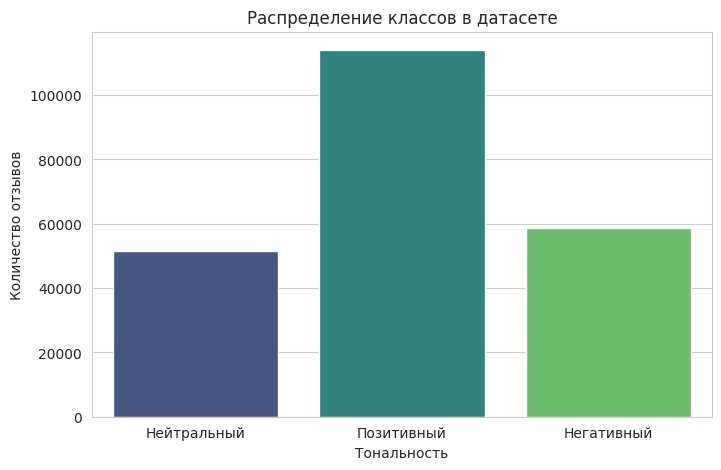


Всего: 224264


In [ ]:
print('=== Распределение классов ===')
print(df['sentiment'].value_counts().sort_index())
print('\nДоли (%):')
print((df['sentiment'].value_counts(normalize=True).sort_index() * 100).round(2))

# Если sentiment_name уже есть — используем его
order = ['Нейтральный', 'Позитивный', 'Негативный']
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sentiment_name', order=order, palette='viridis')
plt.title('Распределение классов в датасете')
plt.xlabel('Тональность')
plt.ylabel('Количество отзывов')
plt.show()

print(f'\nВсего: {len(df)}')

=== Статистика длины ===
count    224264.000000
mean        707.190347
std        1912.317657
min           1.000000
25%         229.000000
50%         412.000000
75%         788.000000
max      381496.000000
Name: text_length, dtype: float64


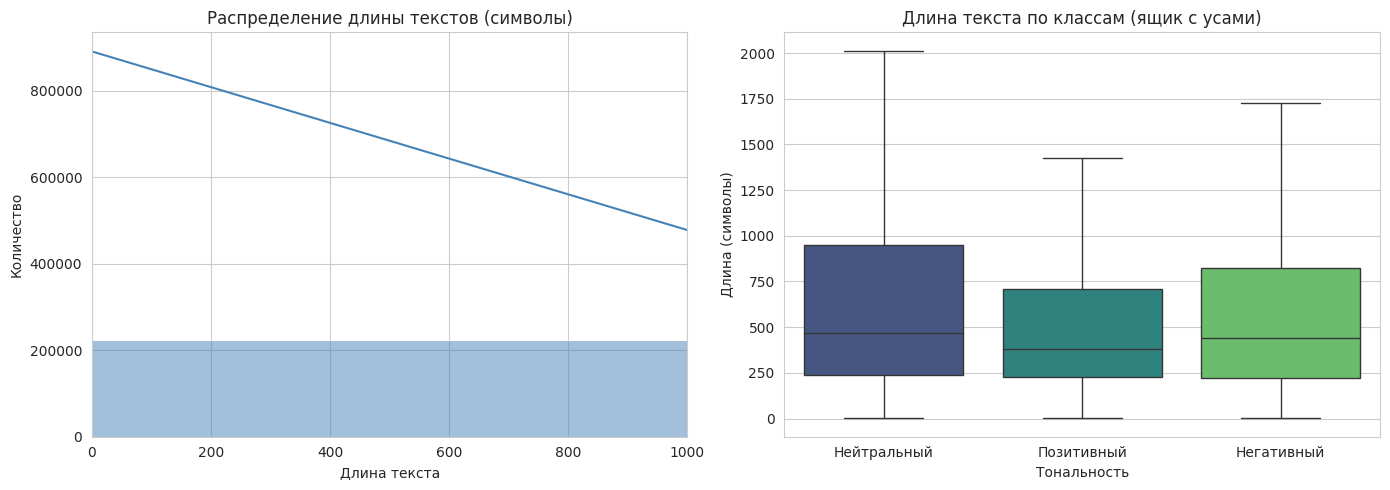

In [ ]:
# full_text уже есть; если нет — берём text
if 'full_text' not in df.columns:
    df['full_text'] = df['text'].astype(str)

df['text_length'] = df['full_text'].astype(str).str.len()

print('=== Статистика длины ===')
print(df['text_length'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='text_length', bins=50, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Распределение длины текстов (символы)')
axes[0].set_xlabel('Длина текста')
axes[0].set_ylabel('Количество')
axes[0].set_xlim(0, 1000)

order = ['Нейтральный', 'Позитивный', 'Негативный']
sns.boxplot(data=df, x='sentiment_name', y='text_length',
            order=order, palette='viridis', ax=axes[1], showfliers=False)
axes[1].set_title('Длина текста по классам (ящик с усами)')
axes[1].set_xlabel('Тональность')
axes[1].set_ylabel('Длина (символы)')

plt.tight_layout()
plt.show()


In [ ]:
for label, name in [(0, 'НЕЙТРАЛЬНЫЙ'), (1, 'ПОЗИТИВНЫЙ'), (2, 'НЕГАТИВНЫЙ')]:
    subset = df[df['sentiment'] == label]
    if len(subset) == 0:
        continue
    sample = subset['full_text'].sample(1, random_state=42).values[0]
    print(f'--- Пример {name} ---')
    print(sample[:500])
    print('-' * 50)
    print()

--- Пример НЕЙТРАЛЬНЫЙ ---
Пишу отзыв не про проживание в отеле, а про достаточно знаменитое здание, в котором расположен отель. Оно действительно стоит того, чтобы прогуляться по Пасеч де Грасия чуть дальше и осмотреть эту часть улицы - по соседству находятся еще несколько необычайно красивых зданий в стиле модерн, при этом здесь немноголюдно и можно с удовольствием рассматривать архитектурные шедевры.После завершения строительства в 1908 году это здание считалось самым дорогим зданием в Барселоне, т.к. при его строитель
--------------------------------------------------

--- Пример ПОЗИТИВНЫЙ ---
Как по мне самый вкусный из линейки. Не особо приторный,вкусно как с молоком, так и с водой. Меня насыщает часа на 2-3 -
--------------------------------------------------

--- Пример НЕГАТИВНЫЙ ---
Запись пациентов Очень плохо организована запись пациентов. с 24.06 по 26.06 пыталась дозвониться в течении дня не менее 4-х раз в день. Трубку взяли только 26.06 после 16 часов. Минуты 3 выслуши

### 1.1 Предобработка

- приводим текст к нижнему регистру;
- удаляем HTML-теги, ссылки, email и упоминания;
- сохраняем русские и латинские буквы, цифры и базовую пунктуацию;
- исключаем пустые и слишком короткие строки;
- удаляем дубликаты **внутри одного split**, не перенося одинаковые тексты между train и validation;
- обрезаем экстремально длинные тексты до 10 000 символов, чтобы ограничить расход памяти на векторизации. Более 99% текстов исходного файла короче этого порога.

In [ ]:
def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    # В исходном CSV есть отдельные экстремально длинные тексты.
    text = text[:10_000]
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[@#]\w+", " ", text)
    text = re.sub(r"[\n\r\t]+", " ", text)
    text = re.sub(r"[^а-яёa-z0-9\s.!?,\-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("Размер ДО очистки:", f"{df.shape[0]:,}")
df_clean = df.copy()
df_clean = df_clean.dropna(subset=["sentiment", "split"])
df_clean["full_text"] = df_clean["full_text"].fillna("").astype(str)
df_clean["text_clean"] = df_clean["full_text"].apply(clean_text)

MIN_LEN = 10
df_clean = df_clean[df_clean["text_clean"].str.len() >= MIN_LEN].copy()
# Дедупликация внутри каждой части, чтобы не менять официальное разбиение.
df_clean = df_clean.drop_duplicates(subset=["split", "text_clean"]).reset_index(drop=True)
df_clean["sentiment_name"] = df_clean["sentiment"].map(CLASS_MAP)

print("Размер ПОСЛЕ очистки:", f"{df_clean.shape[0]:,}")
print(f"Удалено: {df.shape[0] - df_clean.shape[0]:,}")
print("\nРазбиение после очистки:")
print(df_clean["split"].value_counts())
display(df_clean[["full_text", "text_clean", "sentiment_name", "split"]].sample(min(5, len(df_clean)), random_state=RANDOM_STATE))


Размер ДО очистки: 224,264
Размер ПОСЛЕ очистки: 224,171
Удалено: 93

Разбиение после очистки:
split
train         203284
validation     20887
Name: count, dtype: int64


,full_text,text_clean,sentiment_name,split
134264,Хорошее место для студентов и не толькоДОСТОИНСТВА : Недорого ; Порции весьма хорошие ; Акции ; Расположен недалеко от несколькимх ВУЗов,хорошее место для студентов и не толькодостоинства недорого порции весьма хорошие акции расположен недалеко от несколькимх вузов,Негативный,train
86898,"Конечно, без особого шика и неособого тоже - об этом писали другие отзовики. В стандарте только гель-шампунь в одном флаконе и все на этом. Аскети...","конечно, без особого шика и неособого тоже - об этом писали другие отзовики. в стандарте только гель-шампунь в одном флаконе и все на этом. аскети...",Нейтральный,train
59770,"Сеть отелей Скандик (Scandiс) я первоначально нашла через Booking.com. Но, в итоге, забронировала номер через сайт самой сети. Кроме того, я зарег...","сеть отелей скандик scandiс я первоначально нашла через booking.com. но, в итоге, забронировала номер через сайт самой сети. кроме того, я зарегис...",Нейтральный,train
101896,"Хочу поблагодарить заведующего Хочу поблагодарить заведующего 1-го неврологического отд. Епифанова Валерия Павловича, лечащего врача Свидовскую Ол...","хочу поблагодарить заведующего хочу поблагодарить заведующего 1-го неврологического отд. епифанова валерия павловича, лечащего врача свидовскую ол...",Позитивный,train
114566,"Нет, просто там французский сыр.","нет, просто там французский сыр.",Нейтральный,train


In [ ]:
df_final = df_clean[["text_clean", "sentiment", "sentiment_name", "split"]].rename(
    columns={"text_clean": "text"}
)
CLEANED_PATH = Path("ru_sentiment_cleaned.csv")
df_final.to_csv(CLEANED_PATH, index=False, encoding="utf-8-sig")
print(f"Сохранено: {CLEANED_PATH.resolve()}, размер: {df_final.shape}")
display(df_final.head())


Сохранено: /content/ru_sentiment_cleaned.csv, размер: (224171, 4)


,text,sentiment,sentiment_name,split
0,".с.,и спросил его о посланник аллаха!ты порицаешь что-то из слушания? он ответил я не порицаю ничего из него,но передай им,чтобы они открывали сво...",1,Позитивный,train
1,"роднее всех родных попала я в гкб 8 еще в декабре 2002 г. ехать в больницу очень боялась, но делать нечего, рожать надо. о гкб 8 слышала много хор...",1,Позитивный,train
2,"непорядочное отношение к своим работникам работаю в сети доктор столетов центр. в моем трудовом договоре прописано, что работад. оплачивает обучен...",2,Негативный,train
3,". отсутствуют нормативы, госты и прочее, что позволило бы отличить хорошие правильные наркотики от плохих неправильных . у алкоголя и табака они в...",1,Позитивный,train
4,"у меня машина в руках 5 лет и это первая моя машина и не могу с ней никак расстаться! ни разу меня не подвела, заводилась после ночи на улице зимо...",1,Позитивный,train


=== Распределение классов в очищенном датасете ===
sentiment
0     51639
1    113939
2     58593
Name: count, dtype: int64

Доли (%):
sentiment
0    23.04
1    50.83
2    26.14
Name: proportion, dtype: float64


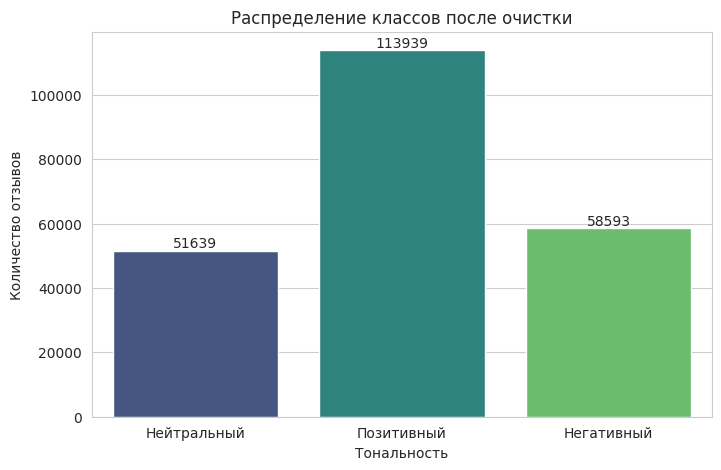


Всего после очистки: 224171


In [ ]:
print('=== Распределение классов в очищенном датасете ===')
print(df_clean['sentiment'].value_counts().sort_index())
print('\nДоли (%):')
print((df_clean['sentiment'].value_counts(normalize=True).sort_index() * 100).round(2))

order = ['Нейтральный', 'Позитивный', 'Негативный']
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df_clean,
    x='sentiment_name',
    order=order,
    palette='viridis'
)
plt.title('Распределение классов после очистки')
plt.xlabel('Тональность')
plt.ylabel('Количество отзывов')

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=10
    )

plt.show()

print(f'\nВсего после очистки: {len(df_clean)}')

---
## Train / Validation split

Используем готовое разбиение из CSV: `train` для обучения, `validation` для оценки. Validation не участвует ни в выборе обучающих примеров, ни в обучении векторизаторов.

In [ ]:
# Для полного эксперимента используем всю train-часть.
# Для более быстрого пробного запуска можно установить USE_FULL_TRAIN = False.
USE_FULL_TRAIN = True
MAX_TRAIN_SAMPLES = 60_000

available_splits = set(df_clean["split"].astype(str).str.lower().unique())
if {"train", "validation"}.issubset(available_splits):
    train_df = df_clean[df_clean["split"].astype(str).str.lower().eq("train")].copy()
    test_df = df_clean[df_clean["split"].astype(str).str.lower().eq("validation")].copy()
    print("Используется исходное разбиение из CSV: train / validation.")
else:
    # Резервный вариант на случай, если в файле нет готового validation.
    print("Внимание: train/validation не найдены. Создаю stratified train/test split 80/20.")
    train_df, test_df = train_test_split(
        df_clean, test_size=0.2, random_state=RANDOM_STATE,
        stratify=df_clean["sentiment"]
    )

if not USE_FULL_TRAIN and len(train_df) > MAX_TRAIN_SAMPLES:
    n_classes = train_df["sentiment"].nunique()
    samples_per_class = max(1, MAX_TRAIN_SAMPLES // n_classes)
    train_df = (
        train_df.groupby("sentiment", group_keys=False)
        .apply(lambda group: group.sample(
            n=min(len(group), samples_per_class), random_state=RANDOM_STATE
        ))
        .reset_index(drop=True)
    )
    print(f"Для ускорения взята стратифицированная подвыборка train: {len(train_df):,} строк.")
else:
    print(f"Используем train целиком: {len(train_df):,} строк.")

if train_df["sentiment"].nunique() < 2 or test_df["sentiment"].nunique() < 2:
    raise ValueError("В train или validation недостаточно классов для обучения и оценки.")

print("\nTrain labels:")
print(train_df["sentiment"].map(CLASS_MAP).value_counts())
print("\nValidation labels:")
print(test_df["sentiment"].map(CLASS_MAP).value_counts())


Используется исходное разбиение из CSV: train / validation.
Используем train целиком: 203,284 строк.

Train labels:
sentiment
Позитивный     104014
Негативный      53098
Нейтральный     46172
Name: count, dtype: int64

Validation labels:
sentiment
Позитивный     9925
Негативный     5495
Нейтральный    5467
Name: count, dtype: int64


In [ ]:
X_train = train_df["text_clean"]
y_train = train_df["sentiment"]
X_test = test_df["text_clean"]
y_test = test_df["sentiment"]

print(f"Train: {len(X_train):,} | Validation: {len(X_test):,}")
print("Распределение в train:")
print(y_train.value_counts().sort_index().rename(index=CLASS_MAP))
print("\nРаспределение в validation:")
print(y_test.value_counts().sort_index().rename(index=CLASS_MAP))


Train: 203,284 | Validation: 20,887
Распределение в train:
sentiment
Нейтральный     46172
Позитивный     104014
Негативный      53098
Name: count, dtype: int64

Распределение в validation:
sentiment
Нейтральный    5467
Позитивный     9925
Негативный     5495
Name: count, dtype: int64


---
## 2–3. Векторизации + классические модели

Обучаем несколько комбинаций «векторизатор + классификатор» на одном и том же train/test.


In [ ]:
# ---------- Модели ----------
models = {
    "MultinomialNB (BoW 1-2)": Pipeline([
        ("vect", CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000)),
        ("clf", MultinomialNB())
    ]),

    "BernoulliNB (бинарный BoW 1-2)": Pipeline([
        ("vect", CountVectorizer(ngram_range=(1, 2), binary=True, min_df=3, max_features=100_000)),
        ("clf", BernoulliNB())
    ]),

    "ComplementNB (TF-IDF 1-2)": Pipeline([
        ("vect", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000)),
        ("clf", ComplementNB())
    ]),

    "LogReg (TF-IDF 1-2)": Pipeline([
        ("vect", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000)),
        ("clf", LogisticRegression(max_iter=1000, C=1.0, n_jobs=-1, random_state=RANDOM_STATE))
    ]),

    "LinearSVC (TF-IDF 1-2)": Pipeline([
        ("vect", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000)),
        ("clf", LinearSVC(C=1.0, dual="auto", random_state=RANDOM_STATE, max_iter=2000))
    ]),

    "LinearSVC (word+char)": Pipeline([
        ("features", FeatureUnion([
            ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50_000)),
            ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=30_000))
        ])),
        ("clf", LinearSVC(C=0.5, dual="auto", random_state=RANDOM_STATE, max_iter=2000))
    ]),
}

print(f"Будет обучено {len(models)} моделей\n")


Будет обучено 6 моделей



In [ ]:
LEADERBOARD.clear()  # не дублируем строки, если обучение запускается повторно

# ---------- Обучение и оценка ----------
for name, model in models.items():
    print(f"Обучаю: {name} ...", end=" ", flush=True)
    t0 = time.time()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    elapsed = time.time() - t0
    report(name, y_test, y_pred, elapsed)
    print()


Обучаю: MultinomialNB (BoW 1-2) ... MultinomialNB (BoW 1-2)                             macro-F1=0.6477  acc=0.6494  (123.4 с)

Обучаю: BernoulliNB (бинарный BoW 1-2) ... BernoulliNB (бинарный BoW 1-2)                      macro-F1=0.5897  acc=0.5957  (129.2 с)

Обучаю: ComplementNB (TF-IDF 1-2) ... ComplementNB (TF-IDF 1-2)                           macro-F1=0.6646  acc=0.6650  (127.8 с)

Обучаю: LogReg (TF-IDF 1-2) ... LogReg (TF-IDF 1-2)                                 macro-F1=0.7482  acc=0.7599  (201.2 с)

Обучаю: LinearSVC (TF-IDF 1-2) ... LinearSVC (TF-IDF 1-2)                              macro-F1=0.7335  acc=0.7465  (199.7 с)

Обучаю: LinearSVC (word+char) ... LinearSVC (word+char)                               macro-F1=0.7467  acc=0.7588  (913.3 с)



---
## 4. Итоговое сравнение


In [ ]:
df_lb = pd.DataFrame(LEADERBOARD).sort_values("macro-F1", ascending=False).reset_index(drop=True)

styled = (
    df_lb.style
    .format({
        "macro-F1": "{:.4f}",
        "accuracy": "{:.4f}",
        "обучение, с": "{:.1f}"
    })
    .highlight_max(subset=["macro-F1", "accuracy"], color="#d4edda")
    .set_caption("Leaderboard: macro-F1 и Accuracy на тестовой выборке")
    .set_table_styles([
        {"selector": "caption", "props": [("caption-side", "top"), ("font-size", "15px"), ("font-weight", "bold")]},
        {"selector": "th", "props": [("text-align", "center"), ("background-color", "#f8f9fa")]},
        {"selector": "td", "props": [("text-align", "center")]}
    ])
    .hide(axis="index")
)

display(styled)


группа,модель,macro-F1,accuracy,"обучение, с"
классика,LogReg (TF-IDF 1-2),0.7482,0.7599,201.2
классика,LinearSVC (word+char),0.7467,0.7588,913.3
классика,LinearSVC (TF-IDF 1-2),0.7335,0.7465,199.7
классика,ComplementNB (TF-IDF 1-2),0.6646,0.6650,127.8
классика,MultinomialNB (BoW 1-2),0.6477,0.6494,123.4
классика,BernoulliNB (бинарный BoW 1-2),0.5897,0.5957,129.2


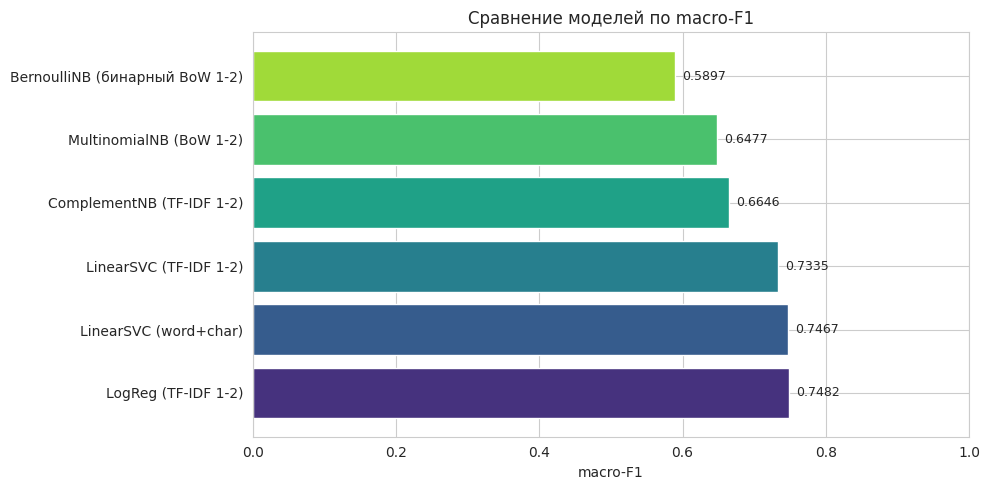

In [ ]:
# Барплот для наглядности
fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette("viridis", len(df_lb))
bars = ax.barh(df_lb["модель"], df_lb["macro-F1"], color=colors)
ax.set_xlabel("macro-F1")
ax.set_title("Сравнение моделей по macro-F1")
ax.set_xlim(0, 1)
for bar, val in zip(bars, df_lb["macro-F1"]):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2, f"{val:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()


### 4.1 Подробный отчёт лучшей модели


In [ ]:
# Берём лучшую модель по macro-F1 на validation
if not LEADERBOARD:
    raise RuntimeError("Сначала выполните ячейку обучения моделей (ячейка 23).")

df_lb = pd.DataFrame(LEADERBOARD).sort_values("macro-F1", ascending=False).reset_index(drop=True)
best_name = df_lb.iloc[0]["модель"]
best_model = models[best_name]

print(f"Лучшая модель: {best_name}")
print(f"macro-F1 = {df_lb.iloc[0]['macro-F1']:.4f}, accuracy = {df_lb.iloc[0]['accuracy']:.4f}\n")

y_pred_best = best_model.predict(X_test)
print(classification_report(
    y_test, y_pred_best,
    labels=CLASS_ORDER,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))


Лучшая модель: LogReg (TF-IDF 1-2)
macro-F1 = 0.7482, accuracy = 0.7599

              precision    recall  f1-score   support

 Нейтральный     0.6495    0.6475    0.6485      5467
  Позитивный     0.7946    0.8106    0.8025      9925
  Негативный     0.8072    0.7803    0.7936      5495

    accuracy                         0.7599     20887
   macro avg     0.7504    0.7461    0.7482     20887
weighted avg     0.7599    0.7599    0.7598     20887



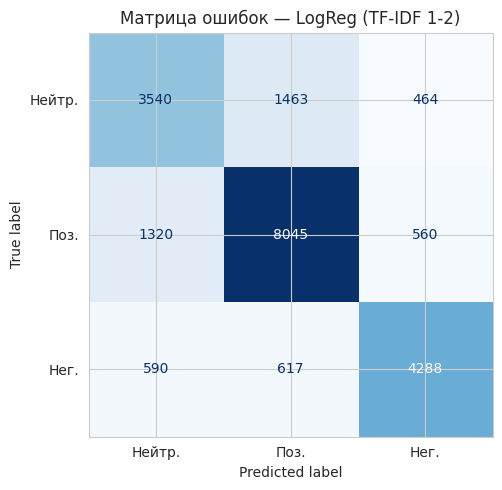

In [ ]:
# Матрица ошибок на validation
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_best, labels=CLASS_ORDER)
disp = ConfusionMatrixDisplay(cm, display_labels=["Нейтр.", "Поз.", "Нег."])
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"Матрица ошибок — {best_name}")
plt.tight_layout()
plt.show()


### Как интерпретировать матрицу ошибок

Строки матрицы соответствуют истинной тональности, столбцы — предсказанной. Значения на диагонали — правильно классифицированные примеры; значения вне диагонали показывают, какие классы модель путает между собой. Конкретные числа формируются при запуске ноутбука и зависят от обученных моделей.

---
## Краткие выводы по фактическому запуску

Таблица и вывод ниже формируются по результатам текущего запуска на validation из предоставленного CSV. Фиксированные метрики из исходного ноутбука удалены, потому что они относятся к другому разбиению данных.


In [ ]:
# Метрики формируются динамически после обучения моделей.
df_lb = pd.DataFrame(LEADERBOARD).sort_values("macro-F1", ascending=False).reset_index(drop=True)
if df_lb.empty:
    print("Результатов пока нет. Сначала выполните ячейку обучения моделей.")
else:
    display(df_lb)
    best = df_lb.iloc[0]
    print(f"Лучшая модель по macro-F1: {best['модель']}")
    print(f"macro-F1: {best['macro-F1']:.4f}; accuracy: {best['accuracy']:.4f}")
    if len(df_lb) > 1:
        print(f"Разница macro-F1 с моделью на втором месте: {best['macro-F1'] - df_lb.iloc[1]['macro-F1']:.4f}")

print("\nУчитывайте, что train содержит несколько источников, включая 27 136 примеров с эвристической разметкой по рейтингу, "
      "а validation сформирован из исходного ru_sentiment_dataset_validation.")


,группа,модель,macro-F1,accuracy,"обучение, с"
0,классика,LogReg (TF-IDF 1-2),0.7482,0.7599,201.2
1,классика,LinearSVC (word+char),0.7467,0.7588,913.3
2,классика,LinearSVC (TF-IDF 1-2),0.7335,0.7465,199.7
3,классика,ComplementNB (TF-IDF 1-2),0.6646,0.6650,127.8
4,классика,MultinomialNB (BoW 1-2),0.6477,0.6494,123.4
5,классика,BernoulliNB (бинарный BoW 1-2),0.5897,0.5957,129.2


Лучшая модель по macro-F1: LogReg (TF-IDF 1-2)
macro-F1: 0.7482; accuracy: 0.7599
Разница macro-F1 с моделью на втором месте: 0.0015

Учитывайте, что train содержит несколько источников, включая 27 136 примеров с эвристической разметкой по рейтингу, а validation сформирован из исходного ru_sentiment_dataset_validation.


In [ ]:
import pandas as pd

df = pd.read_csv("/content/merged_sentiment_dataset.csv.gz")

print("Размер датасета:", df.shape)
print("\nКолонки:", df.columns.tolist())
print("\nРаспределение классов:")
print(df["sentiment"].value_counts(dropna=False))

print("\nПервые 5 строк:")
display(df.head())

Размер датасета: (224264, 15)

Колонки: ['text', 'sentiment', 'sentiment_name', 'split', 'source_dataset', 'source_row_id', 'label_source', 'original_sentiment', 'rating', 'product_id', 'category', 'category_label', 'date', 'pros', 'cons']

Распределение классов:
sentiment
1    114005
2     58603
0     51656
Name: count, dtype: int64

Первые 5 строк:


/tmp/ipykernel_1297/3864277624.py:3: DtypeWarning: Columns (10,11,12,13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/merged_sentiment_dataset.csv.gz")


,text,sentiment,sentiment_name,split,source_dataset,source_row_id,label_source,original_sentiment,rating,product_id,category,category_label,date,pros,cons
0,".с.,и спросил его: о Посланник Аллаха!Ты пори...",1,positive,train,ru_sentiment_dataset_train,21098,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Роднее всех родных Попала я в ГКБ №8 еще в дек...,1,positive,train,ru_sentiment_dataset_train,21099,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Непорядочное отношение к своим работникам Рабо...,2,negative,train,ru_sentiment_dataset_train,21100,original_sentiment_label,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"). Отсутствуют нормативы, Госты и прочее, что ...",1,positive,train,ru_sentiment_dataset_train,21101,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,У меня машина в руках 5 лет и это первая моя м...,1,positive,train,ru_sentiment_dataset_train,21102,original_sentiment_label,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("Разделение данных:")
print(df["split"].value_counts(dropna=False))

print("\nКлассы по выборкам:")
display(pd.crosstab(df["split"], df["sentiment"]))

print("\nИсточники данных:")
print(df["source_dataset"].value_counts(dropna=False))

print("\nПропуски в текстах:")
print(df["text"].isna().sum())

print("\nПолные дубли текстов:")
print(df["text"].duplicated().sum())

Разделение данных:
split
train         203374
validation     20890
Name: count, dtype: int64

Классы по выборкам:


sentiment,0,1,2
split,,,
train,46187,104079,53108
validation,5469,9926,5495



Источники данных:
source_dataset
ru_sentiment_dataset_train         176238
filtered                            27136
ru_sentiment_dataset_validation     20890
Name: count, dtype: int64

Пропуски в текстах:
0

Полные дубли текстов:
0


In [ ]:
# Проверка пересечений и длины текстов

import pandas as pd

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()

# Нормализуем текст для проверки возможных дублей
def normalize_for_check(text):
    return " ".join(str(text).lower().split())

train_normalized = set(
    train_df["text"].map(normalize_for_check)
)

val_normalized = set(
    val_df["text"].map(normalize_for_check)
)

overlap = train_normalized & val_normalized

print("Пересечений Train / Validation:", len(overlap))

print("\nДлины текстов (в словах):")
for name, data in [
    ("Train", train_df),
    ("Validation", val_df)
]:
    lengths = data["text"].str.split().str.len()

    print(f"\n{name}:")
    print("Медиана:", lengths.median())
    print("95-й перцентиль:", lengths.quantile(0.95))
    print("Максимум:", lengths.max())

print("\nРаспределение источников по выборкам:")
display(
    pd.crosstab(
        df["source_dataset"],
        df["split"]
    )
)

Пересечений Train / Validation: 0

Длины текстов (в словах):

Train:
Медиана: 61.0
95-й перцентиль: 309.0
Максимум: 48146

Validation:
Медиана: 77.0
95-й перцентиль: 345.0
Максимум: 39734

Распределение источников по выборкам:


split,train,validation
source_dataset,,
filtered,27136,0
ru_sentiment_dataset_train,176238,0
ru_sentiment_dataset_validation,0,20890


In [ ]:
import re
import numpy as np

def tokenize_new(text):
    return re.findall(r"[а-яёa-z0-9]+", str(text).lower())

# Проверяем на обучающей выборке
train_lengths = train_df["text"].map(
    lambda text: len(tokenize_new(text))
)

print("Длины после токенизации:")
print(train_lengths.describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
))

print("\nДоля текстов, которые будут обрезаны:")

for max_len in [70, 128, 256, 384, 512]:
    truncated = (train_lengths > max_len).mean() * 100
    print(f"MAX_LEN={max_len}: {truncated:.2f}%")

Длины после токенизации:
count    203374.000000
mean        102.454085
std         239.968313
min           0.000000
50%          60.000000
75%         117.000000
90%         209.000000
95%         300.000000
99%         648.000000
max       48045.000000
Name: text, dtype: float64

Доля текстов, которые будут обрезаны:
MAX_LEN=70: 43.27%
MAX_LEN=128: 21.99%
MAX_LEN=256: 6.81%
MAX_LEN=384: 3.02%
MAX_LEN=512: 1.64%


In [ ]:
# Проверяем пустые после токенизации и экстремально длинные тексты

print("Пустых после токенизации:", (train_lengths == 0).sum())
print("Короче 3 токенов:", (train_lengths < 3).sum())
print("Длиннее 1000 токенов:", (train_lengths > 1000).sum())

print("\nПримеры самых длинных текстов:")

longest_indices = train_lengths.nlargest(3).index

for idx in longest_indices:
    text = train_df.loc[idx, "text"]

    print("\n" + "=" * 60)
    print("Длина:", train_lengths.loc[idx], "токенов")
    print("Источник:", train_df.loc[idx, "source_dataset"])
    print("Текст (первые 700 символов):")
    print(str(text)[:700])

Пустых после токенизации: 17
Короче 3 токенов: 295
Длиннее 1000 токенов: 775

Примеры самых длинных текстов:

Длина: 48045 токенов
Источник: ru_sentiment_dataset_train
Текст (первые 700 символов):
АСТАНА. КАЗИНФОРМ - Акорда опубликовала статью Главы государства Нурсултана Назарбаева «План нации - Путь к казахстанской мечте». «1 января 2016 года начался практический этап выполнения Плана нации «100 конкретных шагов по реализации 5 институциональных реформ». Вступили в силу 59 законов, которые создают принципиально новую правовую среду для развития государства, экономики и общества. Нам важно оценить этот беспрецедентный в нашей истории масштаб изменений национального законодательства. Тем более, что они открывают путь к достижению нашей казахстанской мечты - стать одной из тридцати наций - лидеров ХХI века. У каждого поколения есть свои мечты, и в них всегда отражается стремление не то

Длина: 31779 токенов
Источник: ru_sentiment_dataset_train
Текст (первые 700 символов):
АСТАНА. КАЗИНФ

In [ ]:
# Анализ экстремально длинных текстов

long_df = train_df.loc[train_lengths > 1000].copy()
long_df["tokens"] = train_lengths.loc[long_df.index]

print("Всего длинных текстов:", len(long_df))

print("\nРаспределение по классам:")
display(pd.crosstab(
    long_df["source_dataset"],
    long_df["sentiment"],
    margins=True
))

print("\nПримеры из разных классов:")

for sentiment_id, name in [
    (0, "Neutral"),
    (1, "Positive"),
    (2, "Negative")
]:
    examples = long_df[
        long_df["sentiment"] == sentiment_id
    ].head(2)

    print(f"\n{'=' * 60}")
    print(name)

    for _, row in examples.iterrows():
        print(
            f"\nДлина: {row['tokens']} токенов | "
            f"Источник: {row['source_dataset']}"
        )
        print(str(row["text"])[:400])

Всего длинных текстов: 775

Распределение по классам:


sentiment,0,1,2,All
source_dataset,,,,
ru_sentiment_dataset_train,414,200,161,775
All,414,200,161,775



Примеры из разных классов:

Neutral

Длина: 1087 токенов | Источник: ru_sentiment_dataset_train
Напишу-ка я отзыв, после шести лет эксплуатации. Покупал в конце 2007 года как замену ВАЗ 2109. Очень долго сомневался т.к. слышал много страшилок про китайский автопром. Но, тем не менее, цена сделала своё дело, отдал 306 тыс. за максимальную комплектацию. Целью покупки "иномарки" в первую очередь было наличие кондиционера и "чтобы не ломалась", все остальные опции были лишь приятным дополнением.

Длина: 2012 токенов | Источник: ru_sentiment_dataset_train
Специальное обращение президента Казахстана Нурсултана Назарбаева, прозвучавшее 26 января на всех телеканалах страны, вызвало оживленную дискуссию в экспертных кругах. Напомним, тогда глава Казахстана сообщил, что намерен передать часть своих полномочий и функций правительству и парламенту, закрепив при этом за собой роль верховного арбитра. Проект соответствующих поправок, в том числе и в Констит

Positive

Длина: 19201 токенов | Источни

In [ ]:
# ============================================================
# ШАГ 7. Подготовка данных для новых нейросетей
# ============================================================

import numpy as np
import pandas as pd

MAX_LEN_NEW = 256
SEED_NEW = 42

# Сохраняем оригинальные выборки
train_new = df[df["split"] == "train"].copy()
val_new = df[df["split"] == "validation"].copy()

# Количество токенов после нашей токенизации
train_new["n_tokens"] = train_new["text"].map(
    lambda x: len(tokenize_new(x))
)

val_new["n_tokens"] = val_new["text"].map(
    lambda x: len(tokenize_new(x))
)

# Удаляем только тексты без распознанных токенов
train_new = train_new[
    train_new["n_tokens"] > 0
].copy()

val_new = val_new[
    val_new["n_tokens"] > 0
].copy()

# Проверяем допустимые метки
assert set(train_new["sentiment"].unique()) == {0, 1, 2}
assert set(val_new["sentiment"].unique()) == {0, 1, 2}

# Тексты и метки
X_train_new = train_new["text"].astype(str).tolist()
y_train_new = train_new["sentiment"].astype(int).to_numpy()

X_val_new = val_new["text"].astype(str).tolist()
y_val_new = val_new["sentiment"].astype(int).to_numpy()

CLASS_NAMES_NEW = ["Neutral", "Positive", "Negative"]

print("Train:", len(X_train_new))
print("Validation:", len(X_val_new))
print("MAX_LEN:", MAX_LEN_NEW)

print("\nРаспределение Train:")
print(train_new["sentiment"].value_counts().sort_index())

print("\nРаспределение Validation:")
print(val_new["sentiment"].value_counts().sort_index())

print("\nУдалено пустых Train:",
      (df["split"] == "train").sum() - len(train_new))

print("Удалено пустых Validation:",
      (df["split"] == "validation").sum() - len(val_new))

Train: 203357
Validation: 20890
MAX_LEN: 256

Распределение Train:
sentiment
0     46184
1    104066
2     53107
Name: count, dtype: int64

Распределение Validation:
sentiment
0    5469
1    9926
2    5495
Name: count, dtype: int64

Удалено пустых Train: 17
Удалено пустых Validation: 0


### 2.2. Повторное обучение нейросетей на объединённом датасете

Подготовка словаря и DataLoader для TextCNN и BiLSTM. Используется MAX_LEN=256, словарь строится только по Train. Метки классов: 0 — Neutral, 1 — Positive, 2 — Negative.

In [ ]:
# ============================================================
# ШАГ 8. Словарь, Dataset и DataLoader
# ============================================================

import random
from collections import Counter

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

SEED_NEW = 42

random.seed(SEED_NEW)
np.random.seed(SEED_NEW)
torch.manual_seed(SEED_NEW)

DEVICE_NEW = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Устройство:", DEVICE_NEW)

# ------------------------------------------------------------
# 1. Строим словарь ТОЛЬКО на Train
# ------------------------------------------------------------

MIN_FREQ_NEW = 2
PAD_IDX_NEW = 0
UNK_IDX_NEW = 1

word_counts_new = Counter()

for text in X_train_new:
    word_counts_new.update(tokenize_new(text))

word2idx_new = {
    "<PAD>": PAD_IDX_NEW,
    "<UNK>": UNK_IDX_NEW
}

for word, count in word_counts_new.items():
    if count >= MIN_FREQ_NEW:
        word2idx_new[word] = len(word2idx_new)

VOCAB_SIZE_NEW = len(word2idx_new)

print("Размер словаря:", VOCAB_SIZE_NEW)


# ------------------------------------------------------------
# 2. Dataset
# ------------------------------------------------------------

class SentimentDatasetNew(Dataset):

    def __init__(self, texts, labels):
        self.labels = np.asarray(labels, dtype=np.int64)

        # Токенизируем заранее, чтобы ускорить обучение
        self.encoded = []

        for text in texts:
            tokens = tokenize_new(text)[:MAX_LEN_NEW]

            ids = [
                word2idx_new.get(token, UNK_IDX_NEW)
                for token in tokens
            ]

            self.encoded.append(ids)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.encoded[idx], int(self.labels[idx])


def collate_new(batch):
    texts, labels = zip(*batch)

    max_batch_len = min(
        max(len(text) for text in texts),
        MAX_LEN_NEW
    )

    padded = torch.full(
        (len(texts), max_batch_len),
        PAD_IDX_NEW,
        dtype=torch.long
    )

    for i, ids in enumerate(texts):
        padded[i, :len(ids)] = torch.tensor(
            ids, dtype=torch.long
        )

    return (
        padded,
        torch.tensor(labels, dtype=torch.long)
    )


# ------------------------------------------------------------
# 3. Создаём Dataset
# ------------------------------------------------------------

train_dataset_new = SentimentDatasetNew(
    X_train_new,
    y_train_new
)

val_dataset_new = SentimentDatasetNew(
    X_val_new,
    y_val_new
)


# ------------------------------------------------------------
# 4. DataLoader
# ------------------------------------------------------------

BATCH_SIZE_NEW = 64

train_loader_new = DataLoader(
    train_dataset_new,
    batch_size=BATCH_SIZE_NEW,
    shuffle=True,
    collate_fn=collate_new,
    num_workers=0,
    pin_memory=(DEVICE_NEW.type == "cuda")
)

val_loader_new = DataLoader(
    val_dataset_new,
    batch_size=BATCH_SIZE_NEW,
    shuffle=False,
    collate_fn=collate_new,
    num_workers=0,
    pin_memory=(DEVICE_NEW.type == "cuda")
)


# ------------------------------------------------------------
# 5. Проверка
# ------------------------------------------------------------

X_batch, y_batch = next(iter(train_loader_new))

print("Train batches:", len(train_loader_new))
print("Validation batches:", len(val_loader_new))

print("Форма текстов:", tuple(X_batch.shape))
print("Форма меток:", tuple(y_batch.shape))

print("Метки в батче:", torch.unique(y_batch).tolist())
print("MAX_LEN:", MAX_LEN_NEW)

Устройство: cuda
Размер словаря: 251795
Train batches: 3178
Validation batches: 327
Форма текстов: (64, 256)
Форма меток: (64,)
Метки в батче: [0, 1, 2]
MAX_LEN: 256


In [ ]:
import torch

print("GPU доступен:", torch.cuda.is_available())
print("Устройство:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

GPU доступен: True
Устройство: Tesla T4


### 2.3. TextCNN — базовая модель на объединённом датасете

In [ ]:
# ============================================================
# ШАГ 10. TEXTCNN BASELINE — ОБУЧЕНИЕ
# ============================================================

import copy
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, accuracy_score, classification_report

# Проверяем GPU и подготовленные данные
assert torch.cuda.is_available(), "GPU не подключён!"
assert "train_loader_new" in globals(), "Сначала запусти шаг 8"
assert "val_loader_new" in globals(), "Сначала запусти шаг 8"

DEVICE_NEW = torch.device("cuda")

# ------------------------------------------------------------
# 1. Архитектура TextCNN
# ------------------------------------------------------------

class TextCNNNew(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX_NEW
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(
                embedding_dim,
                num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

    def forward(self, x):
        x = self.embedding(x)
        x = x.transpose(1, 2)

        features = []

        for conv in self.convs:
            h = F.relu(conv(x))
            h = F.max_pool1d(h, h.size(2)).squeeze(2)
            features.append(h)

        x = torch.cat(features, dim=1)
        x = self.dropout(x)

        return self.fc(x)


# ------------------------------------------------------------
# 2. Создаём модель
# ------------------------------------------------------------

model_textcnn_new = TextCNNNew(
    vocab_size=VOCAB_SIZE_NEW
).to(DEVICE_NEW)

criterion_textcnn_new = nn.CrossEntropyLoss()

optimizer_textcnn_new = torch.optim.AdamW(
    model_textcnn_new.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

print("Устройство:", DEVICE_NEW)
print("Параметров модели:",
      sum(p.numel() for p in model_textcnn_new.parameters()))


# ------------------------------------------------------------
# 3. Функции обучения и валидации
# ------------------------------------------------------------

def train_one_epoch_new(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0.0
    total_examples = 0

    for inputs, labels in loader:
        inputs = inputs.to(DEVICE_NEW, non_blocking=True)
        labels = labels.to(DEVICE_NEW, non_blocking=True)

        optimizer.zero_grad()

        logits = model(inputs)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_examples += labels.size(0)

    return total_loss / total_examples


@torch.no_grad()
def evaluate_new(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_examples = 0

    all_preds = []
    all_labels = []

    for inputs, labels in loader:
        inputs = inputs.to(DEVICE_NEW, non_blocking=True)
        labels = labels.to(DEVICE_NEW, non_blocking=True)

        logits = model(inputs)
        loss = criterion(logits, labels)

        preds = logits.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        total_examples += labels.size(0)

        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    val_loss = total_loss / total_examples

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro",
        labels=[0, 1, 2],
        zero_division=0
    )

    accuracy = accuracy_score(all_labels, all_preds)

    return val_loss, macro_f1, accuracy, all_labels, all_preds


# ------------------------------------------------------------
# 4. Обучение с Early Stopping
# ------------------------------------------------------------

EPOCHS_NEW = 20
PATIENCE_NEW = 5

best_f1_new = -1.0
best_epoch_new = 0
bad_epochs_new = 0

history_textcnn_new = []
best_state_textcnn_new = None

start_time = time.time()

for epoch in range(1, EPOCHS_NEW + 1):

    train_loss = train_one_epoch_new(
        model_textcnn_new,
        train_loader_new,
        optimizer_textcnn_new,
        criterion_textcnn_new
    )

    val_loss, val_f1, val_acc, _, _ = evaluate_new(
        model_textcnn_new,
        val_loader_new,
        criterion_textcnn_new
    )

    history_textcnn_new.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {val_f1:.4f} | "
        f"Accuracy: {val_acc:.4f}",
        flush=True
    )

    if val_f1 > best_f1_new:
        best_f1_new = val_f1
        best_epoch_new = epoch
        bad_epochs_new = 0

        best_state_textcnn_new = copy.deepcopy(
            model_textcnn_new.state_dict()
        )

        torch.save(
            best_state_textcnn_new,
            "/content/textcnn_merged_best.pt"
        )

    else:
        bad_epochs_new += 1

        if bad_epochs_new >= PATIENCE_NEW:
            print("Early stopping")
            break


# ------------------------------------------------------------
# 5. Итоговая оценка лучшей модели
# ------------------------------------------------------------

model_textcnn_new.load_state_dict(best_state_textcnn_new)

_, final_f1, final_acc, y_true, y_pred = evaluate_new(
    model_textcnn_new,
    val_loader_new,
    criterion_textcnn_new
)

print("\n" + "=" * 55)
print("TEXTCNN — ИТОГИ")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_new)
print(f"Macro-F1: {final_f1:.4f}")
print(f"Accuracy: {final_acc:.4f}")
print(f"Время обучения: {(time.time() - start_time) / 60:.1f} мин")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=["Neutral", "Positive", "Negative"],
        digits=4,
        zero_division=0
    )
)

print("\nМодель сохранена:")
print("/content/textcnn_merged_best.pt")

Устройство: cuda
Параметров модели: 32427907
Epoch 01 | Train Loss: 0.8025 | Val Loss: 0.6676 | Macro-F1: 0.6701 | Accuracy: 0.6886
Epoch 02 | Train Loss: 0.6358 | Val Loss: 0.6286 | Macro-F1: 0.6643 | Accuracy: 0.7068
Epoch 03 | Train Loss: 0.5560 | Val Loss: 0.5874 | Macro-F1: 0.7279 | Accuracy: 0.7362
Epoch 04 | Train Loss: 0.4952 | Val Loss: 0.5827 | Macro-F1: 0.7258 | Accuracy: 0.7410
Epoch 05 | Train Loss: 0.4411 | Val Loss: 0.6028 | Macro-F1: 0.7165 | Accuracy: 0.7392
Epoch 06 | Train Loss: 0.3909 | Val Loss: 0.6335 | Macro-F1: 0.7335 | Accuracy: 0.7384
Epoch 07 | Train Loss: 0.3434 | Val Loss: 0.6697 | Macro-F1: 0.7168 | Accuracy: 0.7371
Epoch 08 | Train Loss: 0.2998 | Val Loss: 0.7250 | Macro-F1: 0.7250 | Accuracy: 0.7389
Epoch 09 | Train Loss: 0.2596 | Val Loss: 0.8151 | Macro-F1: 0.7253 | Accuracy: 0.7349
Epoch 10 | Train Loss: 0.2255 | Val Loss: 0.9295 | Macro-F1: 0.7177 | Accuracy: 0.7317
Epoch 11 | Train Loss: 0.1957 | Val Loss: 1.0522 | Macro-F1: 0.7085 | Accuracy: 0.725

In [ ]:
# ============================================================
# ШАГ 11. Установка и загрузка Navec
# ============================================================

!pip -q install navec

import os
import urllib.request
from navec import Navec

NAVEC_PATH_NEW = "/content/navec_hudlit_v1_12B_500K_300d_100q.tar"

NAVEC_URL_NEW = (
    "https://storage.yandexcloud.net/natasha-navec/packs/"
    "navec_hudlit_v1_12B_500K_300d_100q.tar"
)

if not os.path.exists(NAVEC_PATH_NEW):
    print("Скачиваем Navec...")
    urllib.request.urlretrieve(NAVEC_URL_NEW, NAVEC_PATH_NEW)

print("Загружаем эмбеддинги...")
navec_new = Navec.load(NAVEC_PATH_NEW)

print("Navec успешно загружен!")

# Проверяем покрытие словаря
covered_new = sum(
    1 for word in word2idx_new
    if word in navec_new
)

coverage_new = covered_new / len(word2idx_new) * 100

print(f"Размер словаря: {len(word2idx_new):,}")
print(f"Слов найдено в Navec: {covered_new:,}")
print(f"Покрытие словаря: {coverage_new:.2f}%")
print(f"Размерность эмбеддингов: {navec_new['привет'].shape[0]}")

Скачиваем Navec...
Загружаем эмбеддинги...
Navec успешно загружен!
Размер словаря: 251,795
Слов найдено в Navec: 178,965
Покрытие словаря: 71.08%
Размерность эмбеддингов: 300


### 2.4. BiLSTM + Navec + Focal Loss на объединённом датасете

In [ ]:
# ============================================================
# ШАГ 12. BiLSTM + NAVEC + FOCAL LOSS
# ============================================================

import copy
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)

assert torch.cuda.is_available(), "Подключи GPU T4"
assert "navec_new" in globals(), "Сначала выполни шаг 11"

DEVICE_NEW = torch.device("cuda")

# ------------------------------------------------------------
# 1. Создаём матрицу предобученных эмбеддингов
# ------------------------------------------------------------

EMBED_DIM_NEW = 300

rng_new = np.random.default_rng(42)

embedding_matrix_new = rng_new.normal(
    loc=0.0,
    scale=0.05,
    size=(VOCAB_SIZE_NEW, EMBED_DIM_NEW)
).astype(np.float32)

embedding_matrix_new[PAD_IDX_NEW] = 0.0

found_embeddings_new = 0

for word, idx in word2idx_new.items():
    if word in navec_new:
        embedding_matrix_new[idx] = navec_new[word]
        found_embeddings_new += 1

print("Матрица эмбеддингов:", embedding_matrix_new.shape)
print("Предобученных векторов:", found_embeddings_new)


# ------------------------------------------------------------
# 2. Архитектура BiLSTM
# ------------------------------------------------------------

class BiLSTMNew(nn.Module):

    def __init__(
        self,
        embedding_matrix,
        hidden_dim=128,
        dropout=0.4,
        num_classes=3
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_matrix.shape

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX_NEW
        )

        self.embedding.weight.data.copy_(
            torch.from_numpy(embedding_matrix)
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):

        mask = (x != PAD_IDX_NEW)

        embedded = self.embedding(x)

        # Исключаем padding из вычислений LSTM
        lengths = mask.sum(dim=1).cpu()

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, _ = self.lstm(packed)

        output, _ = nn.utils.rnn.pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=x.size(1)
        )

        mask_float = mask.unsqueeze(-1).float()

        pooled = (
            (output * mask_float).sum(dim=1)
            / mask_float.sum(dim=1).clamp(min=1)
        )

        pooled = self.dropout(pooled)

        return self.fc(pooled)


# ------------------------------------------------------------
# 3. Focal Loss
# ------------------------------------------------------------

class FocalLossNew(nn.Module):

    def __init__(self, alpha, gamma=2.0):
        super().__init__()

        self.register_buffer(
            "alpha",
            torch.tensor(alpha, dtype=torch.float32)
        )

        self.gamma = gamma

    def forward(self, logits, targets):

        ce_loss = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        )

        pt = torch.exp(-ce_loss)

        alpha_t = self.alpha[targets]

        loss = (
            alpha_t
            * ((1 - pt) ** self.gamma)
            * ce_loss
        )

        return loss.mean()


# ------------------------------------------------------------
# 4. Создаём модель
# ------------------------------------------------------------

model_bilstm_new = BiLSTMNew(
    embedding_matrix=embedding_matrix_new,
    hidden_dim=128,
    dropout=0.4
).to(DEVICE_NEW)

# Новый порядок классов:
# 0 = Neutral, 1 = Positive, 2 = Negative

criterion_bilstm_new = FocalLossNew(
    alpha=[1.5, 0.75, 1.0],
    gamma=2.0
).to(DEVICE_NEW)

optimizer_bilstm_new = torch.optim.AdamW(
    model_bilstm_new.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

print(
    "Параметров модели:",
    sum(p.numel() for p in model_bilstm_new.parameters())
)


# ------------------------------------------------------------
# 5. Обучение с Early Stopping
# ------------------------------------------------------------

EPOCHS_BILSTM_NEW = 20
PATIENCE_BILSTM_NEW = 5

best_f1_bilstm_new = -1.0
best_epoch_bilstm_new = 0
bad_epochs_bilstm_new = 0

history_bilstm_new = []
best_state_bilstm_new = None

start_time_bilstm_new = time.time()

for epoch in range(1, EPOCHS_BILSTM_NEW + 1):

    train_loss = train_one_epoch_new(
        model_bilstm_new,
        train_loader_new,
        optimizer_bilstm_new,
        criterion_bilstm_new
    )

    val_loss, val_f1, val_acc, _, _ = evaluate_new(
        model_bilstm_new,
        val_loader_new,
        criterion_bilstm_new
    )

    history_bilstm_new.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {val_f1:.4f} | "
        f"Accuracy: {val_acc:.4f}",
        flush=True
    )

    if val_f1 > best_f1_bilstm_new:

        best_f1_bilstm_new = val_f1
        best_epoch_bilstm_new = epoch
        bad_epochs_bilstm_new = 0

        best_state_bilstm_new = copy.deepcopy(
            model_bilstm_new.state_dict()
        )

        torch.save(
            best_state_bilstm_new,
            "/content/bilstm_navec_focal_merged_best.pt"
        )

    else:
        bad_epochs_bilstm_new += 1

        if bad_epochs_bilstm_new >= PATIENCE_BILSTM_NEW:
            print("Early stopping")
            break


# ------------------------------------------------------------
# 6. Итоговая оценка лучшей модели
# ------------------------------------------------------------

model_bilstm_new.load_state_dict(best_state_bilstm_new)

_, final_f1, final_acc, y_true, y_pred = evaluate_new(
    model_bilstm_new,
    val_loader_new,
    criterion_bilstm_new
)

print("\n" + "=" * 55)
print("BiLSTM + NAVEC + FOCAL — ИТОГИ")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_bilstm_new)
print(f"Macro-F1: {final_f1:.4f}")
print(f"Accuracy: {final_acc:.4f}")
print(
    f"Время обучения: "
    f"{(time.time() - start_time_bilstm_new) / 60:.1f} мин"
)

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=[
            "Neutral",
            "Positive",
            "Negative"
        ],
        digits=4,
        zero_division=0
    )
)

print("\nМодель сохранена:")
print("/content/bilstm_navec_focal_merged_best.pt")

Матрица эмбеддингов: (251795, 300)
Предобученных векторов: 178965
Параметров модели: 75979591
Epoch 01 | Train Loss: 0.2084 | Val Loss: 0.1855 | Macro-F1: 0.7470 | Accuracy: 0.7427
Epoch 02 | Train Loss: 0.1265 | Val Loss: 0.1877 | Macro-F1: 0.7577 | Accuracy: 0.7570
Epoch 03 | Train Loss: 0.0741 | Val Loss: 0.2557 | Macro-F1: 0.7516 | Accuracy: 0.7598
Epoch 04 | Train Loss: 0.0424 | Val Loss: 0.3147 | Macro-F1: 0.7411 | Accuracy: 0.7436
Epoch 05 | Train Loss: 0.0252 | Val Loss: 0.4215 | Macro-F1: 0.7364 | Accuracy: 0.7417
Epoch 06 | Train Loss: 0.0155 | Val Loss: 0.5325 | Macro-F1: 0.7241 | Accuracy: 0.7341
Epoch 07 | Train Loss: 0.0100 | Val Loss: 0.5986 | Macro-F1: 0.7246 | Accuracy: 0.7307
Early stopping

BiLSTM + NAVEC + FOCAL — ИТОГИ
Лучшая эпоха: 2
Macro-F1: 0.7577
Accuracy: 0.7570
Время обучения: 25.9 мин

Classification Report:
              precision    recall  f1-score   support

     Neutral     0.5896    0.8076    0.6816      5469
    Positive     0.8608    0.7075    0.776

## Эксперимент 2. TextCNN + веса классов (Class Weights)


In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 2 — TEXTCNN + CLASS WEIGHTS
# Объединённый датасет | Полная самостоятельная ячейка
# ============================================================

import os
import time
import copy
import random

import numpy as np
import torch
import torch.nn as nn

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)

# ============================================================
# 1. ПРОВЕРКА ПОДГОТОВЛЕННЫХ ДАННЫХ
# ============================================================

required = [
    "TextCNNNew",
    "VOCAB_SIZE_NEW",
    "DEVICE_NEW",
    "y_train_new",
    "train_loader_new",
    "val_loader_new",
    "CLASS_NAMES_NEW"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Не найдены переменные: "
        + ", ".join(missing)
        + "\nСначала запусти ячейки подготовки данных."
    )

# ============================================================
# 2. ФИКСИРУЕМ RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(DEVICE_NEW)

print("Устройство:", device)

# ============================================================
# 3. РАССЧИТЫВАЕМ ВЕСА КЛАССОВ
# ============================================================

classes = np.array([0, 1, 2])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.asarray(y_train_new)
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("\n" + "=" * 55)
print("ВЕСА КЛАССОВ")
print("=" * 55)

for i, weight in enumerate(class_weights):
    print(f"{CLASS_NAMES_NEW[i]}: {weight:.4f}")

# ============================================================
# 4. СОЗДАЁМ TEXTCNN
# ============================================================

model_cw_new = TextCNNNew(
    vocab_size=VOCAB_SIZE_NEW,
    embedding_dim=128,
    num_filters=128,
    kernel_sizes=(3, 4, 5),
    dropout=0.5,
    num_classes=3
).to(device)

print("\nМодель успешно создана!")

print(
    "Количество параметров:",
    sum(p.numel() for p in model_cw_new.parameters())
)

# ============================================================
# 5. LOSS И OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = torch.optim.AdamW(
    model_cw_new.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

# ============================================================
# 6. ФУНКЦИЯ ОБУЧЕНИЯ
# ============================================================

def train_epoch_cw(model, loader, optimizer, criterion):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(inputs)

        loss = criterion(logits, labels)

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples

# ============================================================
# 7. ФУНКЦИЯ ВАЛИДАЦИИ
# ============================================================

@torch.no_grad()
def evaluate_epoch_cw(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        logits = model(inputs)

        loss = criterion(logits, labels)

        predictions = torch.argmax(logits, dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(labels.cpu().numpy())
        all_pred.extend(predictions.cpu().numpy())

    avg_loss = total_loss / total_samples

    return (
        avg_loss,
        np.asarray(all_true),
        np.asarray(all_pred)
    )

# ============================================================
# 8. НАСТРОЙКИ ОБУЧЕНИЯ
# ============================================================

EPOCHS = 20
PATIENCE = 5

best_f1 = -1.0
best_epoch = 0
best_state = None
patience_counter = 0

history_cw_new = []

start_time = time.time()

print("\n" + "=" * 55)
print("НАЧИНАЕМ ОБУЧЕНИЕ TEXTCNN + CLASS WEIGHTS")
print("=" * 55)

# ============================================================
# 9. ОБУЧЕНИЕ
# ============================================================

for epoch in range(1, EPOCHS + 1):

    train_loss = train_epoch_cw(
        model_cw_new,
        train_loader_new,
        optimizer,
        criterion
    )

    val_loss, y_true, y_pred = evaluate_epoch_cw(
        model_cw_new,
        val_loader_new,
        criterion
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(y_true, y_pred)

    history_cw_new.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1:

        best_f1 = macro_f1
        best_epoch = epoch

        # Храним лучший checkpoint на CPU
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model_cw_new.state_dict().items()
        }

        patience_counter = 0

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping")
        break

# ============================================================
# 10. ВОССТАНАВЛИВАЕМ ЛУЧШУЮ МОДЕЛЬ
# ============================================================

model_cw_new.load_state_dict(best_state)
model_cw_new.eval()

# ============================================================
# 11. ФИНАЛЬНАЯ ОЦЕНКА
# ============================================================

val_loss, y_true_cw_new, y_pred_cw_new = evaluate_epoch_cw(
    model_cw_new,
    val_loader_new,
    criterion
)

final_f1_cw_new = f1_score(
    y_true_cw_new,
    y_pred_cw_new,
    average="macro",
    zero_division=0
)

final_accuracy_cw_new = accuracy_score(
    y_true_cw_new,
    y_pred_cw_new
)

elapsed = (time.time() - start_time) / 60

print("\n" + "=" * 55)
print("TEXTCNN + CLASS WEIGHTS — ИТОГИ")
print("=" * 55)

print(f"Лучшая эпоха: {best_epoch}")
print(f"Macro-F1: {final_f1_cw_new:.4f}")
print(f"Accuracy: {final_accuracy_cw_new:.4f}")
print(f"Время обучения: {elapsed:.1f} мин")

print("\nClassification Report:")

print(
    classification_report(
        y_true_cw_new,
        y_pred_cw_new,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 12. СОХРАНЯЕМ МОДЕЛЬ И ИСТОРИЮ ОБУЧЕНИЯ
# ============================================================

import pandas as pd

save_path_cw_new = (
    "/content/textcnn_class_weights_merged_best.pt"
)

history_path_cw_new = (
    "/content/textcnn_class_weights_history.csv"
)

torch.save(
    model_cw_new.state_dict(),
    save_path_cw_new
)

pd.DataFrame(history_cw_new).to_csv(
    history_path_cw_new,
    index=False
)

print("\nМодель сохранена:", save_path_cw_new)
print("История обучения:", history_path_cw_new)

# ============================================================
# 13. СРАВНЕНИЕ С BASELINE
# ============================================================

baseline_f1 = 0.7335
difference = final_f1_cw_new - baseline_f1

print("\n" + "=" * 55)
print("СРАВНЕНИЕ С TEXTCNN BASELINE")
print("=" * 55)

print(f"TextCNN baseline:        {baseline_f1:.4f}")
print(f"TextCNN + Class Weights: {final_f1_cw_new:.4f}")
print(f"Разница Macro-F1:        {difference:+.4f}")

if difference > 0:
    print("\nРезультат: веса классов улучшили Macro-F1.")
elif difference < 0:
    print("\nРезультат: веса классов не улучшили Macro-F1.")
else:
    print("\nРезультат: Macro-F1 не изменился.")

Устройство: cuda

ВЕСА КЛАССОВ
Neutral: 1.4677
Positive: 0.6514
Negative: 1.2764

Модель успешно создана!
Количество параметров: 32427907

НАЧИНАЕМ ОБУЧЕНИЕ TEXTCNN + CLASS WEIGHTS
Epoch 01 | Train Loss: 0.8455 | Val Loss: 0.6771 | Macro-F1: 0.6751 | Accuracy: 0.6706
Epoch 02 | Train Loss: 0.6658 | Val Loss: 0.6357 | Macro-F1: 0.7071 | Accuracy: 0.7160
Epoch 03 | Train Loss: 0.5817 | Val Loss: 0.6005 | Macro-F1: 0.7068 | Accuracy: 0.7051
Epoch 04 | Train Loss: 0.5163 | Val Loss: 0.5862 | Macro-F1: 0.7276 | Accuracy: 0.7267
Epoch 05 | Train Loss: 0.4580 | Val Loss: 0.6002 | Macro-F1: 0.7302 | Accuracy: 0.7308
Epoch 06 | Train Loss: 0.4048 | Val Loss: 0.6227 | Macro-F1: 0.7314 | Accuracy: 0.7331
Epoch 07 | Train Loss: 0.3532 | Val Loss: 0.6686 | Macro-F1: 0.7239 | Accuracy: 0.7230
Epoch 08 | Train Loss: 0.3069 | Val Loss: 0.7397 | Macro-F1: 0.7271 | Accuracy: 0.7309
Epoch 09 | Train Loss: 0.2653 | Val Loss: 0.8238 | Macro-F1: 0.7254 | Accuracy: 0.7322
Epoch 10 | Train Loss: 0.2292 | Val 

## Эксперимент 3. TextCNN + аугментация Neutral и Negative

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 3. TEXTCNN + AUGMENTATION
# ============================================================

import random
import time
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score, classification_report

# 1. Проверка данных

required = [
    "train_new", "word2idx_new", "MAX_LEN_NEW",
    "VOCAB_SIZE_NEW", "DEVICE_NEW", "TextCNNNew",
    "val_loader_new", "CLASS_NAMES_NEW"
]

missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError("Не найдены переменные: " + ", ".join(missing))

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device(DEVICE_NEW)

# 2. Аугментация: удаление одного случайного слова

rng = random.Random(seed)

def augment_text_exp3(text):
    words = str(text).split()
    if len(words) < 8:
        return str(text)

    idx = rng.randrange(len(words))
    return " ".join(words[:idx] + words[idx + 1:])

original = train_new[["text", "sentiment"]].copy()
original = original.reset_index(drop=True)

print("Исходное распределение:")
print(original["sentiment"].value_counts().sort_index())

extra_rows = []

for label in [0, 2]:
    subset = original[original["sentiment"] == label]
    count = int(len(subset) * 0.20)

    sampled = subset.sample(
        n=count,
        random_state=seed,
        replace=False
    )

    for text in sampled["text"]:
        extra_rows.append({
            "text": augment_text_exp3(text),
            "sentiment": label
        })

augmented = pd.DataFrame(extra_rows)

train_aug_new = pd.concat(
    [original, augmented],
    ignore_index=True
)

train_aug_new = train_aug_new.sample(
    frac=1,
    random_state=seed
).reset_index(drop=True)

print("\nПосле аугментации:")
print(train_aug_new["sentiment"].value_counts().sort_index())
print("Всего:", len(train_aug_new))

# 3. Подготовка Dataset

pad_id = word2idx_new.get("<PAD>", 0)
unk_id = word2idx_new.get("<UNK>", 1)

class AugDatasetExp3(Dataset):
    def __init__(self, texts, labels):
        self.labels = [int(x) for x in labels]
        self.sequences = []

        for text in texts:
            tokens = re.findall(
                r"[а-яёa-z0-9]+",
                str(text).lower()
            )[:MAX_LEN_NEW]

            ids = [word2idx_new.get(t, unk_id) for t in tokens]
            self.sequences.append(ids if ids else [unk_id])

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]


def collate_exp3(batch):
    sequences, labels = zip(*batch)
    max_len = max(len(x) for x in sequences)

    inputs = torch.full(
        (len(sequences), max_len),
        pad_id,
        dtype=torch.long
    )

    for i, seq in enumerate(sequences):
        inputs[i, :len(seq)] = torch.tensor(seq)

    return inputs, torch.tensor(labels, dtype=torch.long)


train_dataset_aug_new = AugDatasetExp3(
    train_aug_new["text"].tolist(),
    train_aug_new["sentiment"].tolist()
)

train_loader_aug_new = DataLoader(
    train_dataset_aug_new,
    batch_size=64,
    shuffle=True,
    collate_fn=collate_exp3,
    num_workers=0
)

print("Батчей:", len(train_loader_aug_new))

# 4. Модель

model_aug_new = TextCNNNew(
    vocab_size=VOCAB_SIZE_NEW,
    embedding_dim=128,
    num_filters=128,
    kernel_sizes=(3, 4, 5),
    dropout=0.5,
    num_classes=3
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model_aug_new.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

# 5. Обучение и валидация

def train_exp3():
    model_aug_new.train()
    total_loss = 0.0
    total_count = 0

    for inputs, labels in train_loader_aug_new:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model_aug_new(inputs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        n = len(labels)
        total_loss += loss.item() * n
        total_count += n

    return total_loss / total_count


@torch.no_grad()
def validate_exp3():
    model_aug_new.eval()
    total_loss = 0.0
    total_count = 0
    all_true = []
    all_pred = []

    for inputs, labels in val_loader_new:
        inputs = inputs.to(device)
        labels = labels.to(device)

        logits = model_aug_new(inputs)
        loss = criterion(logits, labels)
        predictions = logits.argmax(dim=1)

        n = len(labels)
        total_loss += loss.item() * n
        total_count += n

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

    return (
        total_loss / total_count,
        np.asarray(all_true),
        np.asarray(all_pred)
    )

# 6. Запуск

best_f1_aug_new = -1.0
best_epoch_aug_new = 0
best_state_aug_new = None
patience_counter = 0

history_aug_new = []
start = time.time()

for epoch in range(1, 21):
    train_loss = train_exp3()
    val_loss, y_true, y_pred = validate_exp3()

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )
    accuracy = accuracy_score(y_true, y_pred)

    history_aug_new.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1_aug_new:
        best_f1_aug_new = macro_f1
        best_epoch_aug_new = epoch

        best_state_aug_new = {
            k: v.detach().cpu().clone()
            for k, v in model_aug_new.state_dict().items()
        }
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= 5:
        print("Early stopping")
        break

# 7. Итоги

model_aug_new.load_state_dict(best_state_aug_new)

_, y_true_aug_new, y_pred_aug_new = validate_exp3()

final_f1_aug_new = f1_score(
    y_true_aug_new,
    y_pred_aug_new,
    average="macro",
    zero_division=0
)

final_acc_aug_new = accuracy_score(
    y_true_aug_new,
    y_pred_aug_new
)

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 3 — ИТОГИ")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_aug_new)
print(f"Macro-F1: {final_f1_aug_new:.4f}")
print(f"Accuracy: {final_acc_aug_new:.4f}")
print(f"Время: {(time.time() - start) / 60:.1f} мин")

print("\nClassification Report:")
print(classification_report(
    y_true_aug_new,
    y_pred_aug_new,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES_NEW,
    digits=4,
    zero_division=0
))

# 8. Сохранение

model_path_aug_new = "/content/textcnn_augmentation_merged_best.pt"
history_path_aug_new = "/content/textcnn_augmentation_history.csv"

torch.save(model_aug_new.state_dict(), model_path_aug_new)
pd.DataFrame(history_aug_new).to_csv(
    history_path_aug_new,
    index=False
)

print("\nМодель сохранена:", model_path_aug_new)
print("История сохранена:", history_path_aug_new)

print("\nСРАВНЕНИЕ:")
print("TextCNN baseline:        0.7335")
print("TextCNN + Class Weights: 0.7314")
print(f"TextCNN + Augmentation:  {final_f1_aug_new:.4f}")

Исходное распределение:
sentiment
0     46184
1    104066
2     53107
Name: count, dtype: int64

После аугментации:
sentiment
0     55420
1    104066
2     63728
Name: count, dtype: int64
Всего: 223214
Батчей: 3488
Epoch 01 | Train Loss: 0.8083 | Val Loss: 0.6650 | Macro-F1: 0.6831 | Accuracy: 0.6893
Epoch 02 | Train Loss: 0.6275 | Val Loss: 0.6045 | Macro-F1: 0.7196 | Accuracy: 0.7247
Epoch 03 | Train Loss: 0.5397 | Val Loss: 0.5797 | Macro-F1: 0.7257 | Accuracy: 0.7392
Epoch 04 | Train Loss: 0.4701 | Val Loss: 0.5849 | Macro-F1: 0.7351 | Accuracy: 0.7437
Epoch 05 | Train Loss: 0.4104 | Val Loss: 0.6038 | Macro-F1: 0.7297 | Accuracy: 0.7438
Epoch 06 | Train Loss: 0.3538 | Val Loss: 0.6614 | Macro-F1: 0.7211 | Accuracy: 0.7393
Epoch 07 | Train Loss: 0.3042 | Val Loss: 0.7057 | Macro-F1: 0.7263 | Accuracy: 0.7372
Epoch 08 | Train Loss: 0.2612 | Val Loss: 0.7819 | Macro-F1: 0.7169 | Accuracy: 0.7334
Epoch 09 | Train Loss: 0.2243 | Val Loss: 0.8838 | Macro-F1: 0.7185 | Accuracy: 0.7319
Ea

В эксперименте с аугментацией обучающая выборка была дополнена примерами миноритарных классов. Количество объектов класса Neutral было увеличено с 46 184 до 55 420, класса Negative — с 53 107 до 63 728. Лучшее значение Macro-F1 составило 0.7351 на 4-й эпохе, что немного превышает baseline TextCNN (0.7335) и вариант с использованием class weights (0.7314). Наиболее сложным для классификации остаётся класс Neutral с F1-score 0.6373. После 4-й эпохи наблюдается переобучение, поэтому была выбрана модель с лучшим validation Macro-F1.

Confusion Matrix:
[[3281 1561  627]
 [1435 7698  793]
 [ 571  614 4310]]


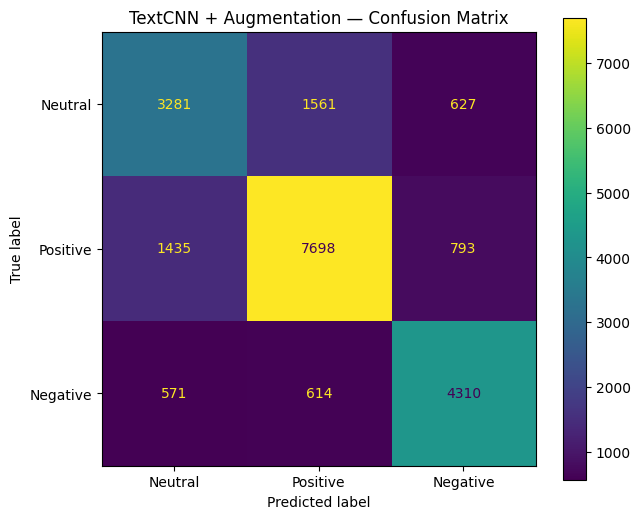

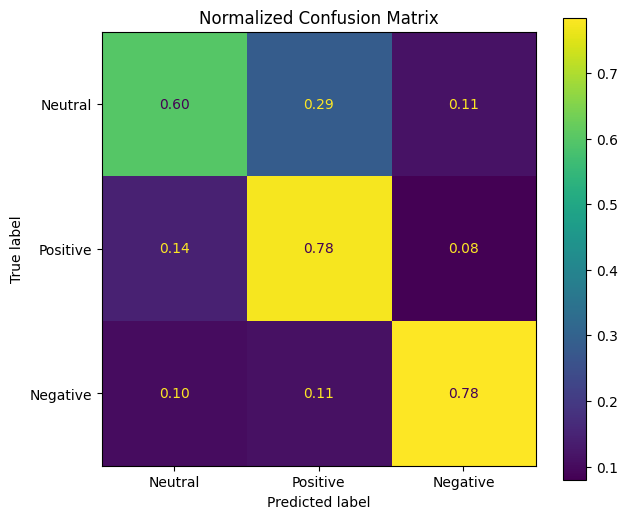


Количество ошибок по направлениям:
true_name  pred_name
Neutral    Positive     1561
Positive   Neutral      1435
           Negative      793
Neutral    Negative      627
Negative   Positive      614
           Neutral       571
dtype: int64

Ошибки Neutral:
pred_name
Positive    1561
Negative     627
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Названия классов
class_names = ["Neutral", "Positive", "Negative"]

# =========================
# 1. CONFUSION MATRIX
# =========================

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format="d")
plt.title("TextCNN + Augmentation — Confusion Matrix")
plt.show()


# =========================
# 2. НОРМАЛИЗОВАННАЯ MATRIX
# =========================

cm_norm = confusion_matrix(
    y_true,
    y_pred,
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_norm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format=".2f")
plt.title("Normalized Confusion Matrix")
plt.show()


# =========================
# 3. ТАБЛИЦА ОШИБОК
# =========================

errors_df = pd.DataFrame({
    "true": y_true,
    "pred": y_pred
})

errors_df["true_name"] = errors_df["true"].map({
    0: "Neutral",
    1: "Positive",
    2: "Negative"
})

errors_df["pred_name"] = errors_df["pred"].map({
    0: "Neutral",
    1: "Positive",
    2: "Negative"
})

errors_only = errors_df[
    errors_df["true"] != errors_df["pred"]
].copy()

print("\nКоличество ошибок по направлениям:")
print(
    errors_only
    .groupby(["true_name", "pred_name"])
    .size()
    .sort_values(ascending=False)
)


# =========================
# 4. КУДА УЛЕТАЕТ NEUTRAL
# =========================

neutral_errors = errors_only[
    errors_only["true"] == 0
]

print("\nОшибки Neutral:")
print(neutral_errors["pred_name"].value_counts())

# Эксперимент 4. TextCNN + Augmentation + Focal Loss

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 4. TEXTCNN + AUGMENTATION + FOCAL LOSS
# ============================================================

import random
import time
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score, classification_report


# ============================================================
# 1. ПРОВЕРКА ДАННЫХ
# ============================================================

required = [
    "train_new",
    "word2idx_new",
    "MAX_LEN_NEW",
    "VOCAB_SIZE_NEW",
    "DEVICE_NEW",
    "TextCNNNew",
    "val_loader_new",
    "CLASS_NAMES_NEW"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Не найдены переменные: " + ", ".join(missing)
    )


seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device(DEVICE_NEW)


# ============================================================
# 2. АУГМЕНТАЦИЯ
# Удаляем одно случайное слово
# ============================================================

rng = random.Random(seed)


def augment_text_exp4(text):

    words = str(text).split()

    if len(words) < 8:
        return str(text)

    idx = rng.randrange(len(words))

    return " ".join(
        words[:idx] + words[idx + 1:]
    )


original_exp4 = train_new[
    ["text", "sentiment"]
].copy()

original_exp4 = original_exp4.reset_index(
    drop=True
)


print("Исходное распределение:")

print(
    original_exp4[
        "sentiment"
    ].value_counts().sort_index()
)


extra_rows_exp4 = []


# Аугментируем классы 0 и 2 на 20%
for label in [0, 2]:

    subset = original_exp4[
        original_exp4["sentiment"] == label
    ]

    count = int(
        len(subset) * 0.20
    )

    sampled = subset.sample(
        n=count,
        random_state=seed,
        replace=False
    )

    for text in sampled["text"]:

        extra_rows_exp4.append({
            "text": augment_text_exp4(text),
            "sentiment": label
        })


augmented_exp4 = pd.DataFrame(
    extra_rows_exp4
)


train_aug_exp4 = pd.concat(
    [
        original_exp4,
        augmented_exp4
    ],
    ignore_index=True
)


train_aug_exp4 = train_aug_exp4.sample(
    frac=1,
    random_state=seed
).reset_index(
    drop=True
)


print("\nПосле аугментации:")

print(
    train_aug_exp4[
        "sentiment"
    ].value_counts().sort_index()
)

print(
    "Всего:",
    len(train_aug_exp4)
)


# ============================================================
# 3. DATASET
# ============================================================

pad_id = word2idx_new.get(
    "<PAD>",
    0
)

unk_id = word2idx_new.get(
    "<UNK>",
    1
)


class AugDatasetExp4(Dataset):

    def __init__(
        self,
        texts,
        labels
    ):

        self.labels = [
            int(x)
            for x in labels
        ]

        self.sequences = []

        for text in texts:

            tokens = re.findall(
                r"[а-яёa-z0-9]+",
                str(text).lower()
            )[:MAX_LEN_NEW]

            ids = [
                word2idx_new.get(
                    token,
                    unk_id
                )
                for token in tokens
            ]

            if len(ids) == 0:
                ids = [unk_id]

            self.sequences.append(
                ids
            )

    def __len__(self):

        return len(
            self.labels
        )

    def __getitem__(
        self,
        idx
    ):

        return (
            self.sequences[idx],
            self.labels[idx]
        )


# ============================================================
# 4. COLLATE
# ============================================================

def collate_exp4(batch):

    sequences, labels = zip(
        *batch
    )

    max_len = max(
        len(x)
        for x in sequences
    )

    inputs = torch.full(
        (
            len(sequences),
            max_len
        ),
        pad_id,
        dtype=torch.long
    )

    for i, seq in enumerate(
        sequences
    ):

        inputs[
            i,
            :len(seq)
        ] = torch.tensor(
            seq,
            dtype=torch.long
        )

    labels = torch.tensor(
        labels,
        dtype=torch.long
    )

    return (
        inputs,
        labels
    )


# ============================================================
# 5. DATALOADER
# ============================================================

train_dataset_exp4 = AugDatasetExp4(

    train_aug_exp4[
        "text"
    ].tolist(),

    train_aug_exp4[
        "sentiment"
    ].tolist()
)


train_loader_exp4 = DataLoader(

    train_dataset_exp4,

    batch_size=64,

    shuffle=True,

    collate_fn=collate_exp4,

    num_workers=0
)


print(
    "Батчей:",
    len(train_loader_exp4)
)


# ============================================================
# 6. FOCAL LOSS
# ============================================================

class FocalLoss(nn.Module):

    def __init__(
        self,
        alpha=None,
        gamma=2.0,
        reduction="mean"
    ):

        super().__init__()

        self.gamma = gamma

        self.reduction = reduction


        if alpha is not None:

            self.register_buffer(

                "alpha",

                torch.tensor(
                    alpha,
                    dtype=torch.float32
                )
            )

        else:

            self.alpha = None


    def forward(
        self,
        logits,
        targets
    ):

        ce_loss = F.cross_entropy(

            logits,

            targets,

            reduction="none"
        )


        pt = torch.exp(
            -ce_loss
        )


        focal_loss = (

            (1 - pt)
            ** self.gamma

        ) * ce_loss


        if self.alpha is not None:

            alpha_t = self.alpha[
                targets
            ]

            focal_loss = (

                alpha_t
                * focal_loss
            )


        if self.reduction == "mean":

            return focal_loss.mean()


        if self.reduction == "sum":

            return focal_loss.sum()


        return focal_loss


# ============================================================
# 7. НОВАЯ МОДЕЛЬ
# ============================================================

model_focal_new = TextCNNNew(

    vocab_size=VOCAB_SIZE_NEW,

    embedding_dim=128,

    num_filters=128,

    kernel_sizes=(
        3,
        4,
        5
    ),

    dropout=0.5,

    num_classes=3

).to(
    device
)


# ============================================================
# 8. LOSS
# ============================================================

criterion_focal = FocalLoss(

    alpha=[
        1.2,   # Neutral
        1.0,   # Positive
        1.1    # Negative
    ],

    gamma=2.0

).to(
    device
)


# ============================================================
# 9. OPTIMIZER
# ============================================================

optimizer_focal = torch.optim.AdamW(

    model_focal_new.parameters(),

    lr=5e-4,

    weight_decay=1e-4
)


# ============================================================
# 10. ОБУЧЕНИЕ
# ============================================================

def train_exp4():

    model_focal_new.train()

    total_loss = 0.0

    total_count = 0


    for inputs, labels in train_loader_exp4:

        inputs = inputs.to(
            device
        )

        labels = labels.to(
            device
        )


        optimizer_focal.zero_grad()


        logits = model_focal_new(
            inputs
        )


        loss = criterion_focal(

            logits,

            labels
        )


        loss.backward()


        optimizer_focal.step()


        n = len(
            labels
        )


        total_loss += (

            loss.item()
            * n
        )


        total_count += n


    return (

        total_loss
        / total_count
    )


# ============================================================
# 11. ВАЛИДАЦИЯ
# ============================================================

@torch.no_grad()
def validate_exp4():

    model_focal_new.eval()

    total_loss = 0.0

    total_count = 0

    all_true = []

    all_pred = []


    for inputs, labels in val_loader_new:

        inputs = inputs.to(
            device
        )

        labels = labels.to(
            device
        )


        logits = model_focal_new(
            inputs
        )


        loss = criterion_focal(

            logits,

            labels
        )


        predictions = logits.argmax(
            dim=1
        )


        n = len(
            labels
        )


        total_loss += (

            loss.item()
            * n
        )


        total_count += n


        all_true.extend(

            labels.cpu().tolist()
        )


        all_pred.extend(

            predictions.cpu().tolist()
        )


    return (

        total_loss / total_count,

        np.asarray(
            all_true
        ),

        np.asarray(
            all_pred
        )
    )


# ============================================================
# 12. ЗАПУСК ОБУЧЕНИЯ
# ============================================================

best_f1_focal_new = -1.0

best_epoch_focal_new = 0

best_state_focal_new = None

patience_counter = 0

history_focal_new = []

start = time.time()


for epoch in range(
    1,
    21
):

    train_loss = train_exp4()

    (
        val_loss,
        y_true,
        y_pred
    ) = validate_exp4()


    macro_f1 = f1_score(

        y_true,

        y_pred,

        average="macro",

        zero_division=0
    )


    accuracy = accuracy_score(

        y_true,

        y_pred
    )


    history_focal_new.append({

        "epoch": epoch,

        "train_loss": train_loss,

        "val_loss": val_loss,

        "macro_f1": macro_f1,

        "accuracy": accuracy
    })


    print(

        f"Epoch {epoch:02d} | "

        f"Train Loss: {train_loss:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Macro-F1: {macro_f1:.4f} | "

        f"Accuracy: {accuracy:.4f}",

        flush=True
    )


    if macro_f1 > best_f1_focal_new:

        best_f1_focal_new = macro_f1

        best_epoch_focal_new = epoch


        best_state_focal_new = {

            k: v.detach().cpu().clone()

            for k, v
            in model_focal_new.state_dict().items()
        }


        patience_counter = 0


    else:

        patience_counter += 1


    if patience_counter >= 5:

        print(
            "Early stopping"
        )

        break


# ============================================================
# 13. ВОЗВРАЩАЕМ ЛУЧШУЮ МОДЕЛЬ
# ============================================================

model_focal_new.load_state_dict(

    best_state_focal_new
)


# ============================================================
# 14. ФИНАЛЬНАЯ ОЦЕНКА
# ============================================================

(
    _,
    y_true_focal_new,
    y_pred_focal_new

) = validate_exp4()


final_f1_focal_new = f1_score(

    y_true_focal_new,

    y_pred_focal_new,

    average="macro",

    zero_division=0
)


final_acc_focal_new = accuracy_score(

    y_true_focal_new,

    y_pred_focal_new
)


# ============================================================
# 15. ИТОГИ
# ============================================================

print(
    "\n" + "=" * 55
)

print(
    "ЭКСПЕРИМЕНТ 4 — ИТОГИ"
)

print(
    "=" * 55
)


print(
    "Лучшая эпоха:",
    best_epoch_focal_new
)


print(
    f"Macro-F1: "
    f"{final_f1_focal_new:.4f}"
)


print(
    f"Accuracy: "
    f"{final_acc_focal_new:.4f}"
)


print(
    f"Время: "
    f"{(time.time() - start) / 60:.1f} мин"
)


print(
    "\nClassification Report:"
)


print(
    classification_report(

        y_true_focal_new,

        y_pred_focal_new,

        labels=[
            0,
            1,
            2
        ],

        target_names=CLASS_NAMES_NEW,

        digits=4,

        zero_division=0
    )
)


# ============================================================
# 16. СОХРАНЕНИЕ
# ============================================================

model_path_focal_new = (
    "/content/"
    "textcnn_augmentation_focal_best.pt"
)


history_path_focal_new = (
    "/content/"
    "textcnn_augmentation_focal_history.csv"
)


torch.save(

    model_focal_new.state_dict(),

    model_path_focal_new
)


pd.DataFrame(

    history_focal_new

).to_csv(

    history_path_focal_new,

    index=False
)


print(
    "\nМодель сохранена:",
    model_path_focal_new
)


print(
    "История сохранена:",
    history_path_focal_new
)


# ============================================================
# 17. СРАВНЕНИЕ
# ============================================================

print(
    "\nСРАВНЕНИЕ:"
)


print(
    "TextCNN baseline:                 0.7335"
)


print(
    "TextCNN + Class Weights:          0.7314"
)


print(
    "TextCNN + Augmentation:           0.7351"
)


print(
    f"TextCNN + Augmentation + Focal:   "
    f"{final_f1_focal_new:.4f}"
)

Исходное распределение:
sentiment
0     46184
1    104066
2     53107
Name: count, dtype: int64

После аугментации:
sentiment
0     55420
1    104066
2     63728
Name: count, dtype: int64
Всего: 223214
Батчей: 3488
Epoch 01 | Train Loss: 0.3897 | Val Loss: 0.2929 | Macro-F1: 0.6750 | Accuracy: 0.6742
Epoch 02 | Train Loss: 0.2826 | Val Loss: 0.2575 | Macro-F1: 0.7132 | Accuracy: 0.7191
Epoch 03 | Train Loss: 0.2357 | Val Loss: 0.2496 | Macro-F1: 0.7223 | Accuracy: 0.7235
Epoch 04 | Train Loss: 0.2010 | Val Loss: 0.2470 | Macro-F1: 0.7301 | Accuracy: 0.7357
Epoch 05 | Train Loss: 0.1723 | Val Loss: 0.2565 | Macro-F1: 0.7270 | Accuracy: 0.7362
Epoch 06 | Train Loss: 0.1467 | Val Loss: 0.2781 | Macro-F1: 0.7214 | Accuracy: 0.7360
Epoch 07 | Train Loss: 0.1259 | Val Loss: 0.3033 | Macro-F1: 0.7221 | Accuracy: 0.7267
Epoch 08 | Train Loss: 0.1078 | Val Loss: 0.3361 | Macro-F1: 0.7129 | Accuracy: 0.7281
Epoch 09 | Train Loss: 0.0927 | Val Loss: 0.3721 | Macro-F1: 0.7191 | Accuracy: 0.7250
Ea

## Эксперимент 5. TextCNN + Navec (без Focal Loss)

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 5. TEXTCNN + NAVEC
# Новый объединённый датасет
# Без аугментации, Class Weights и Focal Loss
# ============================================================

import os
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. ПРОВЕРКА ПОДГОТОВЛЕННЫХ ДАННЫХ
# ============================================================

required = [
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "DEVICE_NEW",
    "train_loader_new",
    "val_loader_new",
    "CLASS_NAMES_NEW",
    "navec_new"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Не найдены переменные: " + ", ".join(missing)
    )

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(DEVICE_NEW)

print("Устройство:", device)

# ============================================================
# 2. ПОДГОТОВКА ЭМБЕДДИНГОВ NAVEC
# ============================================================

EMBEDDING_DIM = 300
PAD_IDX = 0

assert len(word2idx_new) == VOCAB_SIZE_NEW, (
    "Размер словаря не совпадает с VOCAB_SIZE_NEW"
)

rng = np.random.default_rng(SEED)

embedding_matrix = rng.normal(
    loc=0.0,
    scale=0.05,
    size=(VOCAB_SIZE_NEW, EMBEDDING_DIM)
).astype(np.float32)

embedding_matrix[PAD_IDX] = 0.0

found_words = 0

print("\nПодготавливаем эмбеддинги Navec...")

for word, idx in word2idx_new.items():

    if idx == PAD_IDX:
        continue

    if word in navec_new:
        embedding_matrix[idx] = navec_new[word]
        found_words += 1

coverage = found_words / VOCAB_SIZE_NEW * 100

print("\n" + "=" * 55)
print("NAVEC — ПОКРЫТИЕ СЛОВАРЯ")
print("=" * 55)

print("Размер словаря:", VOCAB_SIZE_NEW)
print("Найдено в Navec:", found_words)
print(f"Покрытие: {coverage:.2f}%")
print("Размерность эмбеддингов:", EMBEDDING_DIM)

embedding_tensor = torch.from_numpy(embedding_matrix)

# ============================================================
# 3. МОДЕЛЬ TEXTCNN + NAVEC
# ============================================================

class TextCNNNavecExp5(nn.Module):

    def __init__(
        self,
        embedding_weights,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_weights.shape

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_IDX
        )

        with torch.no_grad():
            self.embedding.weight.copy_(embedding_weights)

        # Эмбеддинги обучаемые
        self.embedding.weight.requires_grad = True

        self.convs = nn.ModuleList([
            nn.Conv1d(
                in_channels=embedding_dim,
                out_channels=num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

        self.min_seq_len = max(kernel_sizes)

    def forward(self, x):

        # x: [batch, sequence_length]

        x = self.embedding(x)

        # [batch, sequence_length, embedding_dim]
        x = x.transpose(1, 2)

        # [batch, embedding_dim, sequence_length]

        # Защита от коротких последовательностей
        if x.size(2) < self.min_seq_len:
            x = F.pad(
                x,
                (0, self.min_seq_len - x.size(2))
            )

        pooled_outputs = []

        for conv in self.convs:

            h = F.relu(conv(x))

            pooled = F.max_pool1d(
                h,
                kernel_size=h.size(2)
            ).squeeze(2)

            pooled_outputs.append(pooled)

        x = torch.cat(pooled_outputs, dim=1)

        x = self.dropout(x)

        return self.fc(x)


model_navec_new = TextCNNNavecExp5(
    embedding_weights=embedding_tensor,
    num_filters=128,
    kernel_sizes=(3, 4, 5),
    dropout=0.5,
    num_classes=3
).to(device)

del embedding_matrix
del embedding_tensor

print("\nМодель создана.")

print(
    "Количество параметров:",
    sum(p.numel() for p in model_navec_new.parameters())
)

# ============================================================
# 4. LOSS И OPTIMIZER
# ============================================================

# Обычная CrossEntropyLoss
# Без Class Weights и Focal Loss

criterion_navec_new = nn.CrossEntropyLoss()

optimizer_navec_new = torch.optim.AdamW(
    model_navec_new.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

# ============================================================
# 5. ФУНКЦИЯ ОБУЧЕНИЯ
# ============================================================

def train_epoch_navec_exp5(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer_navec_new.zero_grad()

        logits = model(inputs)

        loss = criterion_navec_new(
            logits,
            labels
        )

        loss.backward()

        optimizer_navec_new.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


# ============================================================
# 6. ФУНКЦИЯ ВАЛИДАЦИИ
# ============================================================

@torch.no_grad()
def evaluate_navec_exp5(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        logits = model(inputs)

        loss = criterion_navec_new(
            logits,
            labels
        )

        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(
            labels.cpu().numpy()
        )

        all_pred.extend(
            predictions.cpu().numpy()
        )

    return (
        total_loss / total_samples,
        np.asarray(all_true),
        np.asarray(all_pred)
    )


# ============================================================
# 7. НАСТРОЙКИ ОБУЧЕНИЯ
# ============================================================

EPOCHS_NAVEC_NEW = 20
PATIENCE_NAVEC_NEW = 5

best_f1_navec_new = -1.0
best_epoch_navec_new = 0
best_state_navec_new = None

patience_counter = 0

history_navec_new = []

start_time = time.time()

print("\n" + "=" * 55)
print("НАЧИНАЕМ ОБУЧЕНИЕ TEXTCNN + NAVEC")
print("=" * 55)

# ============================================================
# 8. ОБУЧЕНИЕ
# ============================================================

for epoch in range(1, EPOCHS_NAVEC_NEW + 1):

    train_loss = train_epoch_navec_exp5(
        model_navec_new,
        train_loader_new
    )

    val_loss, y_true, y_pred = evaluate_navec_exp5(
        model_navec_new,
        val_loader_new
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    history_navec_new.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1_navec_new:

        best_f1_navec_new = macro_f1
        best_epoch_navec_new = epoch

        best_state_navec_new = {
            key: value.detach().cpu().clone()
            for key, value in model_navec_new.state_dict().items()
        }

        patience_counter = 0

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE_NAVEC_NEW:
        print("\nEarly stopping")
        break

# ============================================================
# 9. ВОССТАНАВЛИВАЕМ ЛУЧШУЮ МОДЕЛЬ
# ============================================================

model_navec_new.load_state_dict(
    best_state_navec_new
)

model_navec_new.eval()

# ============================================================
# 10. ФИНАЛЬНАЯ ОЦЕНКА
# ============================================================

_, y_true_navec_new, y_pred_navec_new = evaluate_navec_exp5(
    model_navec_new,
    val_loader_new
)

final_f1_navec_new = f1_score(
    y_true_navec_new,
    y_pred_navec_new,
    average="macro",
    zero_division=0
)

final_accuracy_navec_new = accuracy_score(
    y_true_navec_new,
    y_pred_navec_new
)

elapsed = (time.time() - start_time) / 60

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 5 — TEXTCNN + NAVEC")
print("=" * 55)

print(f"Лучшая эпоха: {best_epoch_navec_new}")
print(f"Macro-F1: {final_f1_navec_new:.4f}")
print(f"Accuracy: {final_accuracy_navec_new:.4f}")
print(f"Время обучения: {elapsed:.1f} мин")

print("\nClassification Report:")

print(
    classification_report(
        y_true_navec_new,
        y_pred_navec_new,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true_navec_new,
        y_pred_navec_new,
        labels=[0, 1, 2]
    )
)

# ============================================================
# 11. СОХРАНЕНИЕ
# ============================================================

model_path_navec_new = (
    "/content/textcnn_navec_merged_best.pt"
)

history_path_navec_new = (
    "/content/textcnn_navec_history.csv"
)

torch.save(
    model_navec_new.state_dict(),
    model_path_navec_new
)

pd.DataFrame(history_navec_new).to_csv(
    history_path_navec_new,
    index=False
)

print("\nМодель сохранена:", model_path_navec_new)
print("История сохранена:", history_path_navec_new)

# ============================================================
# 12. СРАВНЕНИЕ ЭКСПЕРИМЕНТОВ
# ============================================================

print("\n" + "=" * 55)
print("СРАВНЕНИЕ НА НОВОМ ДАТАСЕТЕ")
print("=" * 55)

print("TextCNN baseline:               0.7335")
print("TextCNN + Class Weights:        0.7314")
print("TextCNN + Augmentation:         0.7351")
print("TextCNN + Augmentation + Focal: 0.7301")
print(f"TextCNN + Navec:                {final_f1_navec_new:.4f}")
print("BiLSTM + Navec + Focal:         0.7577")

difference = final_f1_navec_new - 0.7335

print(
    f"\nРазница с TextCNN baseline: {difference:+.4f}"
)

Устройство: cuda

Подготавливаем эмбеддинги Navec...

NAVEC — ПОКРЫТИЕ СЛОВАРЯ
Размер словаря: 251795
Найдено в Navec: 178965
Покрытие: 71.08%
Размерность эмбеддингов: 300

Модель создана.
Количество параметров: 76000839

НАЧИНАЕМ ОБУЧЕНИЕ TEXTCNN + NAVEC
Epoch 01 | Train Loss: 0.5941 | Val Loss: 0.5394 | Macro-F1: 0.7470 | Accuracy: 0.7573
Epoch 02 | Train Loss: 0.4366 | Val Loss: 0.5468 | Macro-F1: 0.7516 | Accuracy: 0.7611
Epoch 03 | Train Loss: 0.3168 | Val Loss: 0.6270 | Macro-F1: 0.7428 | Accuracy: 0.7530
Epoch 04 | Train Loss: 0.2193 | Val Loss: 0.7740 | Macro-F1: 0.7311 | Accuracy: 0.7422
Epoch 05 | Train Loss: 0.1534 | Val Loss: 1.0025 | Macro-F1: 0.7199 | Accuracy: 0.7353
Epoch 06 | Train Loss: 0.1136 | Val Loss: 1.2180 | Macro-F1: 0.7147 | Accuracy: 0.7270
Epoch 07 | Train Loss: 0.0877 | Val Loss: 1.4556 | Macro-F1: 0.7097 | Accuracy: 0.7236

Early stopping

ЭКСПЕРИМЕНТ 5 — TEXTCNN + NAVEC
Лучшая эпоха: 2
Macro-F1: 0.7516
Accuracy: 0.7611
Время обучения: 20.3 мин

Classifica

## Эксперимент 6. TextCNN + Navec + Focal Loss

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 6. TEXTCNN + NAVEC + FOCAL LOSS
# Новый объединённый датасет
# ============================================================

import os
import time
import random

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. ПРОВЕРКА ДАННЫХ
# ============================================================

required = [
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "DEVICE_NEW",
    "train_loader_new",
    "val_loader_new",
    "CLASS_NAMES_NEW",
    "navec_new"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Не найдены переменные: " + ", ".join(missing)
    )

SEED_EXP6 = 42

random.seed(SEED_EXP6)
np.random.seed(SEED_EXP6)
torch.manual_seed(SEED_EXP6)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_EXP6)

device_exp6 = torch.device(DEVICE_NEW)

print("Устройство:", device_exp6)

# ============================================================
# 2. МАТРИЦА NAVEC
# ============================================================

EMBED_DIM_EXP6 = 300
PAD_IDX_EXP6 = 0

if len(word2idx_new) != VOCAB_SIZE_NEW:
    raise ValueError(
        "Размер word2idx_new не совпадает с VOCAB_SIZE_NEW"
    )

rng_exp6 = np.random.default_rng(SEED_EXP6)

embedding_matrix_exp6 = rng_exp6.normal(
    loc=0.0,
    scale=0.05,
    size=(VOCAB_SIZE_NEW, EMBED_DIM_EXP6)
).astype(np.float32)

embedding_matrix_exp6[PAD_IDX_EXP6] = 0.0

found_exp6 = 0

print("\nПодготавливаем Navec...")

for word, idx in word2idx_new.items():

    if idx == PAD_IDX_EXP6:
        continue

    if word in navec_new:
        embedding_matrix_exp6[idx] = navec_new[word]
        found_exp6 += 1

coverage_exp6 = found_exp6 / VOCAB_SIZE_NEW * 100

print("\n" + "=" * 55)
print("NAVEC")
print("=" * 55)

print("Размер словаря:", VOCAB_SIZE_NEW)
print("Найдено в Navec:", found_exp6)
print(f"Покрытие: {coverage_exp6:.2f}%")
print("Размерность:", EMBED_DIM_EXP6)

embedding_tensor_exp6 = torch.from_numpy(
    embedding_matrix_exp6
)

# ============================================================
# 3. TEXTCNN + NAVEC
# ============================================================

class TextCNNNavecExp6(nn.Module):

    def __init__(
        self,
        embedding_weights,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_weights.shape

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_IDX_EXP6
        )

        with torch.no_grad():
            self.embedding.weight.copy_(embedding_weights)

        self.embedding.weight.requires_grad = True

        self.convs = nn.ModuleList([
            nn.Conv1d(
                in_channels=embedding_dim,
                out_channels=num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

        self.min_seq_len = max(kernel_sizes)

    def forward(self, x):

        x = self.embedding(x)
        x = x.transpose(1, 2)

        if x.size(2) < self.min_seq_len:
            x = F.pad(
                x,
                (0, self.min_seq_len - x.size(2))
            )

        pooled_outputs = []

        for conv in self.convs:

            h = F.relu(conv(x))

            pooled = F.max_pool1d(
                h,
                kernel_size=h.size(2)
            ).squeeze(2)

            pooled_outputs.append(pooled)

        x = torch.cat(pooled_outputs, dim=1)

        x = self.dropout(x)

        return self.fc(x)


model_exp6 = TextCNNNavecExp6(
    embedding_weights=embedding_tensor_exp6,
    num_filters=128,
    kernel_sizes=(3, 4, 5),
    dropout=0.5,
    num_classes=3
).to(device_exp6)

del embedding_matrix_exp6
del embedding_tensor_exp6

print("\nМодель создана!")

print(
    "Количество параметров:",
    sum(p.numel() for p in model_exp6.parameters())
)

# ============================================================
# 4. FOCAL LOSS
# ============================================================

class FocalLossExp6(nn.Module):

    def __init__(self, gamma=2.0, alpha=None):
        super().__init__()

        self.gamma = gamma

        if alpha is not None:
            self.register_buffer(
                "alpha",
                torch.tensor(alpha, dtype=torch.float32)
            )
        else:
            self.alpha = None

    def forward(self, logits, targets):

        log_probs = F.log_softmax(logits, dim=1)
        probs = log_probs.exp()

        target_log_probs = log_probs.gather(
            1,
            targets.unsqueeze(1)
        ).squeeze(1)

        target_probs = probs.gather(
            1,
            targets.unsqueeze(1)
        ).squeeze(1)

        focal_factor = (
            1.0 - target_probs
        ).pow(self.gamma)

        loss = -focal_factor * target_log_probs

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            loss = alpha_t * loss

        return loss.mean()


ALPHA_EXP6 = [1.5, 0.75, 1.0]
GAMMA_EXP6 = 2.0

criterion_exp6 = FocalLossExp6(
    gamma=GAMMA_EXP6,
    alpha=ALPHA_EXP6
).to(device_exp6)

optimizer_exp6 = torch.optim.AdamW(
    model_exp6.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

print("\nFocal Loss:")
print("Gamma:", GAMMA_EXP6)
print("Alpha:", ALPHA_EXP6)

# ============================================================
# 5. ФУНКЦИЯ ОБУЧЕНИЯ
# ============================================================

def train_epoch_exp6(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(device_exp6)
        labels = labels.to(device_exp6)

        optimizer_exp6.zero_grad()

        logits = model(inputs)

        loss = criterion_exp6(logits, labels)

        loss.backward()
        optimizer_exp6.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


# ============================================================
# 6. ФУНКЦИЯ ВАЛИДАЦИИ
# ============================================================

@torch.no_grad()
def evaluate_exp6(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(device_exp6)
        labels = labels.to(device_exp6)

        logits = model(inputs)

        loss = criterion_exp6(logits, labels)

        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

    return (
        total_loss / total_samples,
        np.asarray(all_true),
        np.asarray(all_pred)
    )


# ============================================================
# 7. НАСТРОЙКИ ОБУЧЕНИЯ
# ============================================================

EPOCHS_EXP6 = 20
PATIENCE_EXP6 = 5

best_f1_exp6 = -1.0
best_epoch_exp6 = 0
best_state_exp6 = None

patience_counter_exp6 = 0

history_exp6 = []

start_time_exp6 = time.time()

print("\n" + "=" * 55)
print("НАЧИНАЕМ ОБУЧЕНИЕ TEXTCNN + NAVEC + FOCAL LOSS")
print("=" * 55)

# ============================================================
# 8. ОБУЧЕНИЕ
# ============================================================

for epoch in range(1, EPOCHS_EXP6 + 1):

    train_loss = train_epoch_exp6(
        model_exp6,
        train_loader_new
    )

    val_loss, y_true, y_pred = evaluate_exp6(
        model_exp6,
        val_loader_new
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    history_exp6.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1_exp6:

        best_f1_exp6 = macro_f1
        best_epoch_exp6 = epoch

        best_state_exp6 = {
            key: value.detach().cpu().clone()
            for key, value in model_exp6.state_dict().items()
        }

        patience_counter_exp6 = 0

    else:
        patience_counter_exp6 += 1

    if patience_counter_exp6 >= PATIENCE_EXP6:
        print("\nEarly stopping")
        break

# ============================================================
# 9. ВОССТАНАВЛИВАЕМ ЛУЧШУЮ МОДЕЛЬ
# ============================================================

if best_state_exp6 is None:
    raise RuntimeError("Не удалось сохранить лучшую модель.")

model_exp6.load_state_dict(best_state_exp6)
model_exp6.eval()

# ============================================================
# 10. ФИНАЛЬНАЯ ОЦЕНКА
# ============================================================

_, y_true_exp6, y_pred_exp6 = evaluate_exp6(
    model_exp6,
    val_loader_new
)

final_f1_exp6 = f1_score(
    y_true_exp6,
    y_pred_exp6,
    average="macro",
    zero_division=0
)

final_accuracy_exp6 = accuracy_score(
    y_true_exp6,
    y_pred_exp6
)

elapsed_exp6 = (
    time.time() - start_time_exp6
) / 60

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 6 — ИТОГИ")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_exp6)
print(f"Macro-F1: {final_f1_exp6:.4f}")
print(f"Accuracy: {final_accuracy_exp6:.4f}")
print(f"Время обучения: {elapsed_exp6:.1f} мин")

print("\nClassification Report:")

print(
    classification_report(
        y_true_exp6,
        y_pred_exp6,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true_exp6,
        y_pred_exp6,
        labels=[0, 1, 2]
    )
)

# ============================================================
# 11. СОХРАНЕНИЕ
# ============================================================

model_path_exp6 = (
    "/content/textcnn_navec_focal_merged_best.pt"
)

history_path_exp6 = (
    "/content/textcnn_navec_focal_history.csv"
)

torch.save(
    model_exp6.state_dict(),
    model_path_exp6
)

pd.DataFrame(history_exp6).to_csv(
    history_path_exp6,
    index=False
)

print("\nМодель сохранена:", model_path_exp6)
print("История сохранена:", history_path_exp6)

# ============================================================
# 12. СРАВНЕНИЕ
# ============================================================

baseline_navec_f1 = 0.7516

difference_exp6 = (
    final_f1_exp6 - baseline_navec_f1
)

print("\n" + "=" * 55)
print("СРАВНЕНИЕ ЭКСПЕРИМЕНТОВ 5 И 6")
print("=" * 55)

print("TextCNN + Navec:         0.7516")
print(
    f"TextCNN + Navec + Focal: {final_f1_exp6:.4f}"
)

print(
    f"Разница Macro-F1:        {difference_exp6:+.4f}"
)

if difference_exp6 > 0:
    print("\nFocal Loss улучшил Macro-F1.")
elif difference_exp6 < 0:
    print("\nFocal Loss не улучшил Macro-F1.")
else:
    print("\nMacro-F1 не изменился.")

Устройство: cuda

Подготавливаем Navec...

NAVEC
Размер словаря: 251795
Найдено в Navec: 178965
Покрытие: 71.08%
Размерность: 300

Модель создана!
Количество параметров: 76000839

Focal Loss:
Gamma: 2.0
Alpha: [1.5, 0.75, 1.0]

НАЧИНАЕМ ОБУЧЕНИЕ TEXTCNN + NAVEC + FOCAL LOSS
Epoch 01 | Train Loss: 0.2451 | Val Loss: 0.2112 | Macro-F1: 0.7447 | Accuracy: 0.7459
Epoch 02 | Train Loss: 0.1716 | Val Loss: 0.2142 | Macro-F1: 0.7476 | Accuracy: 0.7474
Epoch 03 | Train Loss: 0.1206 | Val Loss: 0.2470 | Macro-F1: 0.7426 | Accuracy: 0.7436
Epoch 04 | Train Loss: 0.0826 | Val Loss: 0.3074 | Macro-F1: 0.7295 | Accuracy: 0.7324
Epoch 05 | Train Loss: 0.0588 | Val Loss: 0.4093 | Macro-F1: 0.7230 | Accuracy: 0.7323
Epoch 06 | Train Loss: 0.0461 | Val Loss: 0.4813 | Macro-F1: 0.7170 | Accuracy: 0.7253
Epoch 07 | Train Loss: 0.0364 | Val Loss: 0.5758 | Macro-F1: 0.7126 | Accuracy: 0.7211

Early stopping

ЭКСПЕРИМЕНТ 6 — ИТОГИ
Лучшая эпоха: 2
Macro-F1: 0.7476
Accuracy: 0.7474
Время обучения: 20.4 мин

C

## Эксперимент 7. BiLSTM + Navec (без Focal Loss)

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 7. BILSTM + NAVEC
# БЕЗ FOCAL LOSS
# Новый объединённый датасет
# ============================================================

import os
import time
import random

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. ПРОВЕРКА ДАННЫХ
# ============================================================

required_exp7 = [
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "DEVICE_NEW",
    "train_loader_new",
    "val_loader_new",
    "CLASS_NAMES_NEW",
    "navec_new"
]

missing_exp7 = [
    name for name in required_exp7
    if name not in globals()
]

if missing_exp7:
    raise RuntimeError(
        "Не найдены переменные: "
        + ", ".join(missing_exp7)
    )

SEED_EXP7 = 42

random.seed(SEED_EXP7)
np.random.seed(SEED_EXP7)
torch.manual_seed(SEED_EXP7)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_EXP7)

device_exp7 = torch.device(DEVICE_NEW)

print("Устройство:", device_exp7)

# ============================================================
# 2. ПОДГОТОВКА NAVEC
# ============================================================

EMBED_DIM_EXP7 = 300
PAD_IDX_EXP7 = 0

if len(word2idx_new) != VOCAB_SIZE_NEW:
    raise ValueError(
        "Размер словаря не совпадает с VOCAB_SIZE_NEW"
    )

rng_exp7 = np.random.default_rng(SEED_EXP7)

embedding_matrix_exp7 = rng_exp7.normal(
    loc=0.0,
    scale=0.05,
    size=(VOCAB_SIZE_NEW, EMBED_DIM_EXP7)
).astype(np.float32)

embedding_matrix_exp7[PAD_IDX_EXP7] = 0.0

found_exp7 = 0

print("\nПодготавливаем Navec...")

for word, idx in word2idx_new.items():

    if idx == PAD_IDX_EXP7:
        continue

    if word in navec_new:
        embedding_matrix_exp7[idx] = navec_new[word]
        found_exp7 += 1

coverage_exp7 = found_exp7 / VOCAB_SIZE_NEW * 100

print("\n" + "=" * 55)
print("NAVEC")
print("=" * 55)

print("Размер словаря:", VOCAB_SIZE_NEW)
print("Найдено в Navec:", found_exp7)
print(f"Покрытие: {coverage_exp7:.2f}%")
print("Размерность:", EMBED_DIM_EXP7)

embedding_tensor_exp7 = torch.from_numpy(
    embedding_matrix_exp7
)

# ============================================================
# 3. АРХИТЕКТУРА BILSTM + NAVEC
# ============================================================

class BiLSTMNavecExp7(nn.Module):

    def __init__(
        self,
        embedding_weights,
        hidden_size=128,
        dropout=0.4,
        num_classes=3
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_weights.shape

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_IDX_EXP7
        )

        with torch.no_grad():
            self.embedding.weight.copy_(embedding_weights)

        # Navec дообучается вместе с моделью
        self.embedding.weight.requires_grad = True

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, input_ids):

        # [batch, seq_len]
        mask = (input_ids != PAD_IDX_EXP7)

        # [batch, seq_len, 300]
        embedded = self.embedding(input_ids)

        # [batch, seq_len, hidden_size * 2]
        lstm_output, _ = self.lstm(embedded)

        # Masked mean pooling
        mask_float = mask.unsqueeze(-1).to(
            dtype=lstm_output.dtype
        )

        masked_output = lstm_output * mask_float

        summed = masked_output.sum(dim=1)

        lengths = mask_float.sum(dim=1).clamp(min=1.0)

        pooled = summed / lengths

        pooled = self.dropout(pooled)

        return self.fc(pooled)


model_exp7 = BiLSTMNavecExp7(
    embedding_weights=embedding_tensor_exp7,
    hidden_size=128,
    dropout=0.4,
    num_classes=3
).to(device_exp7)

del embedding_matrix_exp7
del embedding_tensor_exp7

print("\nМодель BiLSTM + Navec создана!")

print(
    "Количество параметров:",
    sum(p.numel() for p in model_exp7.parameters())
)

# ============================================================
# 4. LOSS И OPTIMIZER
# ============================================================

# ВАЖНО:
# В этом эксперименте используем обычную CrossEntropyLoss.
# Без Focal Loss и без Class Weights.

criterion_exp7 = nn.CrossEntropyLoss()

optimizer_exp7 = torch.optim.AdamW(
    model_exp7.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

print("\nФункция потерь: CrossEntropyLoss")
print("Оптимизатор: AdamW")
print("Learning rate: 0.0005")

# ============================================================
# 5. ФУНКЦИЯ ОБУЧЕНИЯ
# ============================================================

def train_epoch_exp7(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(device_exp7)
        labels = labels.to(device_exp7)

        optimizer_exp7.zero_grad()

        logits = model(inputs)

        loss = criterion_exp7(logits, labels)

        loss.backward()

        optimizer_exp7.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


# ============================================================
# 6. ФУНКЦИЯ ВАЛИДАЦИИ
# ============================================================

@torch.no_grad()
def evaluate_exp7(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(device_exp7)
        labels = labels.to(device_exp7)

        logits = model(inputs)

        loss = criterion_exp7(logits, labels)

        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

    return (
        total_loss / total_samples,
        np.asarray(all_true),
        np.asarray(all_pred)
    )


# ============================================================
# 7. НАСТРОЙКИ ОБУЧЕНИЯ
# ============================================================

EPOCHS_EXP7 = 20
PATIENCE_EXP7 = 5

best_f1_exp7 = -1.0
best_epoch_exp7 = 0
best_state_exp7 = None

patience_counter_exp7 = 0

history_exp7 = []

start_time_exp7 = time.time()

print("\n" + "=" * 55)
print("НАЧИНАЕМ ОБУЧЕНИЕ BILSTM + NAVEC")
print("LOSS: CROSS ENTROPY")
print("=" * 55)

# ============================================================
# 8. ОБУЧЕНИЕ
# ============================================================

for epoch in range(1, EPOCHS_EXP7 + 1):

    train_loss = train_epoch_exp7(
        model_exp7,
        train_loader_new
    )

    val_loss, y_true, y_pred = evaluate_exp7(
        model_exp7,
        val_loader_new
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    history_exp7.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1_exp7:

        best_f1_exp7 = macro_f1
        best_epoch_exp7 = epoch

        best_state_exp7 = {
            key: value.detach().cpu().clone()
            for key, value in model_exp7.state_dict().items()
        }

        patience_counter_exp7 = 0

    else:
        patience_counter_exp7 += 1

    if patience_counter_exp7 >= PATIENCE_EXP7:
        print("\nEarly stopping")
        break

# ============================================================
# 9. ВОССТАНОВЛЕНИЕ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

if best_state_exp7 is None:
    raise RuntimeError(
        "Не удалось сохранить лучшую модель."
    )

model_exp7.load_state_dict(best_state_exp7)

model_exp7.eval()

# ============================================================
# 10. ФИНАЛЬНАЯ ОЦЕНКА
# ============================================================

_, y_true_exp7, y_pred_exp7 = evaluate_exp7(
    model_exp7,
    val_loader_new
)

final_f1_exp7 = f1_score(
    y_true_exp7,
    y_pred_exp7,
    average="macro",
    zero_division=0
)

final_accuracy_exp7 = accuracy_score(
    y_true_exp7,
    y_pred_exp7
)

elapsed_exp7 = (
    time.time() - start_time_exp7
) / 60

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 7 — ИТОГИ")
print("=" * 55)

print(f"Лучшая эпоха: {best_epoch_exp7}")
print(f"Macro-F1: {final_f1_exp7:.4f}")
print(f"Accuracy: {final_accuracy_exp7:.4f}")
print(f"Время обучения: {elapsed_exp7:.1f} мин")

print("\nClassification Report:")

print(
    classification_report(
        y_true_exp7,
        y_pred_exp7,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true_exp7,
        y_pred_exp7,
        labels=[0, 1, 2]
    )
)

# ============================================================
# 11. СОХРАНЕНИЕ
# ============================================================

model_path_exp7 = (
    "/content/bilstm_navec_crossentropy_merged_best.pt"
)

history_path_exp7 = (
    "/content/bilstm_navec_crossentropy_history.csv"
)

torch.save(
    model_exp7.state_dict(),
    model_path_exp7
)

pd.DataFrame(history_exp7).to_csv(
    history_path_exp7,
    index=False
)

print("\nМодель сохранена:", model_path_exp7)
print("История сохранена:", history_path_exp7)

# ============================================================
# 12. СРАВНЕНИЕ С FOCAL LOSS
# ============================================================

focal_f1_exp7 = 0.7577

difference_exp7 = final_f1_exp7 - focal_f1_exp7

print("\n" + "=" * 55)
print("СРАВНЕНИЕ BILSTM")
print("=" * 55)

print(
    f"BiLSTM + Navec (CrossEntropy): {final_f1_exp7:.4f}"
)
print(
    f"BiLSTM + Navec + Focal:        {focal_f1_exp7:.4f}"
)
print(
    f"Разница Macro-F1:              {difference_exp7:+.4f}"
)

if difference_exp7 > 0:
    print("\nCrossEntropy показала лучший Macro-F1.")
elif difference_exp7 < 0:
    print("\nFocal Loss показала лучший Macro-F1.")
else:
    print("\nРезультаты по Macro-F1 совпали.")

Устройство: cuda

Подготавливаем Navec...

NAVEC
Размер словаря: 251795
Найдено в Navec: 178965
Покрытие: 71.08%
Размерность: 300

Модель BiLSTM + Navec создана!
Количество параметров: 75979591

Функция потерь: CrossEntropyLoss
Оптимизатор: AdamW
Learning rate: 0.0005

НАЧИНАЕМ ОБУЧЕНИЕ BILSTM + NAVEC
LOSS: CROSS ENTROPY
Epoch 01 | Train Loss: 0.5399 | Val Loss: 0.5068 | Macro-F1: 0.7585 | Accuracy: 0.7693
Epoch 02 | Train Loss: 0.3582 | Val Loss: 0.5145 | Macro-F1: 0.7650 | Accuracy: 0.7789
Epoch 03 | Train Loss: 0.2217 | Val Loss: 0.6202 | Macro-F1: 0.7484 | Accuracy: 0.7643
Epoch 04 | Train Loss: 0.1294 | Val Loss: 0.8051 | Macro-F1: 0.7428 | Accuracy: 0.7534
Epoch 05 | Train Loss: 0.0852 | Val Loss: 1.0769 | Macro-F1: 0.7356 | Accuracy: 0.7453
Epoch 06 | Train Loss: 0.0554 | Val Loss: 1.2172 | Macro-F1: 0.7295 | Accuracy: 0.7408
Epoch 07 | Train Loss: 0.0328 | Val Loss: 1.4721 | Macro-F1: 0.7269 | Accuracy: 0.7388

Early stopping

ЭКСПЕРИМЕНТ 7 — ИТОГИ
Лучшая эпоха: 2
Macro-F1: 0.7

## Эксперимент 9. TextCNN + Lemmatization + Augmentation

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 9. TEXTCNN + LEMMATIZATION + AUGMENTATION
# НОВЫЙ ОБЪЕДИНЁННЫЙ ДАТАСЕТ
# ============================================================

import sys
import subprocess
import importlib.util

if importlib.util.find_spec("pymorphy3") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "-q",
        "install", "pymorphy3"
    ])

import os
import re
import time
import random
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import pymorphy3

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. ПРОВЕРКА ИСХОДНЫХ ДАННЫХ
# ============================================================

required_exp9 = [
    "train_new",
    "X_val_new",
    "y_val_new",
    "CLASS_NAMES_NEW",
    "DEVICE_NEW"
]

missing_exp9 = [
    name for name in required_exp9
    if name not in globals()
]

if missing_exp9:
    raise RuntimeError(
        "Не найдены переменные: "
        + ", ".join(missing_exp9)
    )

if not {"text", "sentiment"}.issubset(train_new.columns):
    raise ValueError(
        "В train_new должны быть колонки text и sentiment"
    )

SEED_EXP9 = 42

random.seed(SEED_EXP9)
np.random.seed(SEED_EXP9)
torch.manual_seed(SEED_EXP9)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_EXP9)

DEVICE_EXP9 = torch.device(DEVICE_NEW)

print("Устройство:", DEVICE_EXP9)

# ============================================================
# 2. НАСТРОЙКИ
# ============================================================

MAX_LEN_EXP9 = 256
EMBED_DIM_EXP9 = 128
NUM_FILTERS_EXP9 = 128
KERNEL_SIZES_EXP9 = (3, 4, 5)
DROPOUT_EXP9 = 0.5

BATCH_SIZE_EXP9 = 64
EPOCHS_EXP9 = 20
PATIENCE_EXP9 = 5

LR_EXP9 = 5e-4
WEIGHT_DECAY_EXP9 = 1e-4

AUGMENT_FRACTION_EXP9 = 0.20
AUGMENT_CLASSES_EXP9 = [0, 2]

PAD_IDX_EXP9 = 0
UNK_IDX_EXP9 = 1

CACHE_PATH_EXP9 = (
    "/content/experiment9_lemmatized_cache.pkl"
)

MODEL_PATH_EXP9 = (
    "/content/textcnn_lemma_augmentation_best.pt"
)

HISTORY_PATH_EXP9 = (
    "/content/textcnn_lemma_augmentation_history.csv"
)

# ============================================================
# 3. ПОДГОТОВКА ТЕКСТОВ
# ============================================================

train_texts_exp9 = (
    train_new["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

train_labels_exp9 = (
    train_new["sentiment"]
    .astype(int)
    .to_numpy()
)

val_texts_exp9 = [
    "" if pd.isna(text) else str(text)
    for text in X_val_new
]

val_labels_exp9 = np.asarray(
    y_val_new,
    dtype=np.int64
)

print("\nИсходные данные:")
print("Train:", len(train_texts_exp9))
print("Validation:", len(val_texts_exp9))

# ============================================================
# 4. ЛЕММАТИЗАЦИЯ
# ============================================================

morph_exp9 = pymorphy3.MorphAnalyzer()

TOKEN_PATTERN_EXP9 = re.compile(
    r"[а-яёa-z0-9]+",
    flags=re.IGNORECASE
)

RUSSIAN_WORD_EXP9 = re.compile(
    r"^[а-яё]+$"
)

@lru_cache(maxsize=300000)
def lemmatize_word_exp9(word):

    if RUSSIAN_WORD_EXP9.fullmatch(word):
        return morph_exp9.parse(word)[0].normal_form

    return word


def lemmatize_text_exp9(text):

    tokens = TOKEN_PATTERN_EXP9.findall(
        str(text).lower()
    )

    return [
        lemmatize_word_exp9(word)
        for word in tokens
    ]


print("\n" + "=" * 55)
print("ЛЕММАТИЗАЦИЯ")
print("=" * 55)

if os.path.exists(CACHE_PATH_EXP9):

    print("Найден кеш. Загружаем...")

    cache_exp9 = pd.read_pickle(
        CACHE_PATH_EXP9
    )

    if (
        cache_exp9.get("train_count") == len(train_texts_exp9)
        and cache_exp9.get("val_count") == len(val_texts_exp9)
    ):

        train_tokens_exp9 = cache_exp9["train_tokens"]
        val_tokens_exp9 = cache_exp9["val_tokens"]

        print("Лемматизированные тексты загружены.")

    else:
        raise RuntimeError(
            "Кеш не соответствует размеру датасета. "
            "Удалите CACHE_PATH_EXP9 и запустите ячейку заново."
        )

else:

    print("Лемматизируем обучающую выборку...")

    train_tokens_exp9 = []

    for i, text in enumerate(train_texts_exp9, 1):

        train_tokens_exp9.append(
            lemmatize_text_exp9(text)
        )

        if i % 20000 == 0:
            print(
                f"Train: {i}/{len(train_texts_exp9)}",
                flush=True
            )

    print("\nЛемматизируем валидационную выборку...")

    val_tokens_exp9 = []

    for i, text in enumerate(val_texts_exp9, 1):

        val_tokens_exp9.append(
            lemmatize_text_exp9(text)
        )

        if i % 5000 == 0:
            print(
                f"Validation: {i}/{len(val_texts_exp9)}",
                flush=True
            )

    pd.to_pickle(
        {
            "train_count": len(train_texts_exp9),
            "val_count": len(val_texts_exp9),
            "train_tokens": train_tokens_exp9,
            "val_tokens": val_tokens_exp9
        },
        CACHE_PATH_EXP9
    )

    print("\nКеш сохранён:", CACHE_PATH_EXP9)

print("\nПример лемматизации:")

if train_texts_exp9:
    print("Оригинал:", train_texts_exp9[0][:250])
    print("Леммы:", " ".join(train_tokens_exp9[0])[:250])

# ============================================================
# 5. АУГМЕНТАЦИЯ
# ============================================================

print("\n" + "=" * 55)
print("АУГМЕНТАЦИЯ NEUTRAL И NEGATIVE")
print("=" * 55)

rng_aug_exp9 = random.Random(SEED_EXP9)

augmented_tokens_exp9 = list(train_tokens_exp9)
augmented_labels_exp9 = train_labels_exp9.tolist()


def augment_delete_word_exp9(tokens):

    result = list(tokens)

    if len(result) <= 1:
        return result

    delete_position = rng_aug_exp9.randrange(
        len(result)
    )

    del result[delete_position]

    return result


for class_id in AUGMENT_CLASSES_EXP9:

    class_indices = [
        i
        for i, label in enumerate(train_labels_exp9)
        if label == class_id and len(train_tokens_exp9[i]) > 1
    ]

    original_count = int(
        np.sum(train_labels_exp9 == class_id)
    )

    target_extra = round(
        original_count * AUGMENT_FRACTION_EXP9
    )

    if not class_indices:
        print(
            f"Класс {class_id}: нет подходящих текстов"
        )
        continue

    selected_indices = rng_aug_exp9.choices(
        class_indices,
        k=target_extra
    )

    for idx in selected_indices:

        new_tokens = augment_delete_word_exp9(
            train_tokens_exp9[idx]
        )

        augmented_tokens_exp9.append(
            new_tokens
        )

        augmented_labels_exp9.append(
            class_id
        )

    print(
        f"Класс {class_id}: "
        f"было {original_count}, "
        f"добавлено {target_extra}"
    )

print("\nВсего после аугментации:")
print(len(augmented_tokens_exp9))

print("\nРаспределение классов:")

print(
    pd.Series(augmented_labels_exp9)
    .value_counts()
    .sort_index()
)

# ============================================================
# 6. СОЗДАНИЕ СЛОВАРЯ
# ============================================================

print("\n" + "=" * 55)
print("СОЗДАНИЕ СЛОВАРЯ")
print("=" * 55)

word_counts_exp9 = Counter()

# Словарь строится только по исходному train.
# Validation не участвует в построении словаря.

for tokens in train_tokens_exp9:
    word_counts_exp9.update(tokens)

word2idx_exp9 = {
    "<PAD>": PAD_IDX_EXP9,
    "<UNK>": UNK_IDX_EXP9
}

for word, count in word_counts_exp9.items():

    if word not in word2idx_exp9:
        word2idx_exp9[word] = len(word2idx_exp9)

VOCAB_SIZE_EXP9 = len(word2idx_exp9)

print("Размер словаря:", VOCAB_SIZE_EXP9)

# ============================================================
# 7. DATASET И DATALOADER
# ============================================================

class LemmaDatasetExp9(Dataset):

    def __init__(self, token_lists, labels):

        self.token_lists = token_lists
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        tokens = self.token_lists[idx][:MAX_LEN_EXP9]

        ids = [
            word2idx_exp9.get(
                word,
                UNK_IDX_EXP9
            )
            for word in tokens
        ]

        if len(ids) < MAX_LEN_EXP9:

            ids += [
                PAD_IDX_EXP9
            ] * (MAX_LEN_EXP9 - len(ids))

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                int(self.labels[idx]),
                dtype=torch.long
            )
        )


train_dataset_exp9 = LemmaDatasetExp9(
    augmented_tokens_exp9,
    augmented_labels_exp9
)

val_dataset_exp9 = LemmaDatasetExp9(
    val_tokens_exp9,
    val_labels_exp9
)

generator_exp9 = torch.Generator()
generator_exp9.manual_seed(SEED_EXP9)

train_loader_exp9 = DataLoader(
    train_dataset_exp9,
    batch_size=BATCH_SIZE_EXP9,
    shuffle=True,
    generator=generator_exp9,
    num_workers=0,
    pin_memory=(DEVICE_EXP9.type == "cuda")
)

val_loader_exp9 = DataLoader(
    val_dataset_exp9,
    batch_size=BATCH_SIZE_EXP9,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE_EXP9.type == "cuda")
)

print("\nDataLoader созданы.")
print("Train batches:", len(train_loader_exp9))
print("Validation batches:", len(val_loader_exp9))

# ============================================================
# 8. АРХИТЕКТУРА TEXTCNN
# ============================================================

class TextCNNLemmaExp9(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX_EXP9
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(
                embedding_dim,
                num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

        self.min_seq_len = max(kernel_sizes)

    def forward(self, x):

        x = self.embedding(x)

        x = x.transpose(1, 2)

        if x.size(2) < self.min_seq_len:
            x = F.pad(
                x,
                (0, self.min_seq_len - x.size(2))
            )

        pooled_outputs = []

        for conv in self.convs:

            h = F.relu(conv(x))

            pooled = F.max_pool1d(
                h,
                kernel_size=h.size(2)
            ).squeeze(2)

            pooled_outputs.append(pooled)

        x = torch.cat(pooled_outputs, dim=1)

        x = self.dropout(x)

        return self.fc(x)


model_exp9 = TextCNNLemmaExp9(
    vocab_size=VOCAB_SIZE_EXP9,
    embedding_dim=EMBED_DIM_EXP9,
    num_filters=NUM_FILTERS_EXP9,
    kernel_sizes=KERNEL_SIZES_EXP9,
    dropout=DROPOUT_EXP9,
    num_classes=3
).to(DEVICE_EXP9)

print("\nМодель создана!")

print(
    "Количество параметров:",
    sum(p.numel() for p in model_exp9.parameters())
)

# ============================================================
# 9. LOSS И OPTIMIZER
# ============================================================

criterion_exp9 = nn.CrossEntropyLoss()

optimizer_exp9 = torch.optim.AdamW(
    model_exp9.parameters(),
    lr=LR_EXP9,
    weight_decay=WEIGHT_DECAY_EXP9
)

# ============================================================
# 10. ФУНКЦИИ ОБУЧЕНИЯ И ВАЛИДАЦИИ
# ============================================================

def train_epoch_exp9(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP9)
        labels = labels.to(DEVICE_EXP9)

        optimizer_exp9.zero_grad()

        logits = model(inputs)

        loss = criterion_exp9(logits, labels)

        loss.backward()
        optimizer_exp9.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


@torch.no_grad()
def evaluate_exp9(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP9)
        labels = labels.to(DEVICE_EXP9)

        logits = model(inputs)

        loss = criterion_exp9(logits, labels)

        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

    return (
        total_loss / total_samples,
        np.asarray(all_true),
        np.asarray(all_pred)
    )

# ============================================================
# 11. ОБУЧЕНИЕ
# ============================================================

best_f1_exp9 = -1.0
best_epoch_exp9 = 0
best_state_exp9 = None

patience_counter_exp9 = 0
history_exp9 = []

start_time_exp9 = time.time()

print("\n" + "=" * 55)
print("ОБУЧЕНИЕ TEXTCNN + LEMMATIZATION + AUGMENTATION")
print("=" * 55)

for epoch in range(1, EPOCHS_EXP9 + 1):

    train_loss = train_epoch_exp9(
        model_exp9,
        train_loader_exp9
    )

    val_loss, y_true, y_pred = evaluate_exp9(
        model_exp9,
        val_loader_exp9
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    history_exp9.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1_exp9:

        best_f1_exp9 = macro_f1
        best_epoch_exp9 = epoch

        best_state_exp9 = {
            key: value.detach().cpu().clone()
            for key, value in model_exp9.state_dict().items()
        }

        patience_counter_exp9 = 0

    else:
        patience_counter_exp9 += 1

    if patience_counter_exp9 >= PATIENCE_EXP9:
        print("\nEarly stopping")
        break

# ============================================================
# 12. ВОССТАНОВЛЕНИЕ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

if best_state_exp9 is None:
    raise RuntimeError(
        "Не удалось сохранить лучшую модель."
    )

model_exp9.load_state_dict(best_state_exp9)
model_exp9.eval()

# ============================================================
# 13. ФИНАЛЬНАЯ ОЦЕНКА
# ============================================================

_, y_true_exp9, y_pred_exp9 = evaluate_exp9(
    model_exp9,
    val_loader_exp9
)

final_f1_exp9 = f1_score(
    y_true_exp9,
    y_pred_exp9,
    average="macro",
    zero_division=0
)

final_accuracy_exp9 = accuracy_score(
    y_true_exp9,
    y_pred_exp9
)

elapsed_exp9 = (
    time.time() - start_time_exp9
) / 60

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 9 — ИТОГИ")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_exp9)
print(f"Macro-F1: {final_f1_exp9:.4f}")
print(f"Accuracy: {final_accuracy_exp9:.4f}")
print(f"Время обучения: {elapsed_exp9:.1f} мин")

print("\nClassification Report:")

print(
    classification_report(
        y_true_exp9,
        y_pred_exp9,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true_exp9,
        y_pred_exp9,
        labels=[0, 1, 2]
    )
)

# ============================================================
# 14. СОХРАНЕНИЕ
# ============================================================

torch.save(
    {
        "model_state_dict": model_exp9.state_dict(),
        "word2idx": word2idx_exp9,
        "max_len": MAX_LEN_EXP9,
        "class_names": CLASS_NAMES_NEW,
        "best_epoch": best_epoch_exp9,
        "macro_f1": final_f1_exp9,
        "config": {
            "embedding_dim": EMBED_DIM_EXP9,
            "num_filters": NUM_FILTERS_EXP9,
            "kernel_sizes": KERNEL_SIZES_EXP9,
            "dropout": DROPOUT_EXP9
        }
    },
    MODEL_PATH_EXP9
)

pd.DataFrame(history_exp9).to_csv(
    HISTORY_PATH_EXP9,
    index=False
)

print("\nМодель сохранена:", MODEL_PATH_EXP9)
print("История сохранена:", HISTORY_PATH_EXP9)

# ============================================================
# 15. СРАВНЕНИЕ
# ============================================================

baseline_exp9 = 0.7335
augmentation_exp9 = 0.7351
best_model_exp9 = 0.7650

print("\n" + "=" * 55)
print("СРАВНЕНИЕ ЭКСПЕРИМЕНТОВ")
print("=" * 55)

print(f"TextCNN baseline:             {baseline_exp9:.4f}")
print(f"TextCNN + Augmentation:       {augmentation_exp9:.4f}")
print(f"TextCNN + Lemma + Augment:    {final_f1_exp9:.4f}")
print(f"BiLSTM + Navec:               {best_model_exp9:.4f}")

print(
    "\nРазница с TextCNN baseline:",
    f"{final_f1_exp9 - baseline_exp9:+.4f}"
)

print(
    "Разница с TextCNN + Augmentation:",
    f"{final_f1_exp9 - augmentation_exp9:+.4f}"
)

print(
    "Разница с лучшей BiLSTM:",
    f"{final_f1_exp9 - best_model_exp9:+.4f}"
)

Устройство: cuda

Исходные данные:
Train: 203357
Validation: 20890

ЛЕММАТИЗАЦИЯ
Лемматизируем обучающую выборку...
Train: 20000/203357
Train: 40000/203357
Train: 60000/203357
Train: 80000/203357
Train: 100000/203357
Train: 120000/203357
Train: 140000/203357
Train: 160000/203357
Train: 180000/203357
Train: 200000/203357

Лемматизируем валидационную выборку...
Validation: 5000/20890
Validation: 10000/20890
Validation: 15000/20890
Validation: 20000/20890

Кеш сохранён: /content/experiment9_lemmatized_cache.pkl

Пример лемматизации:
Оригинал: .с.,и спросил его:  о Посланник Аллаха!Ты порицаешь что-то из слушания?  Он ответил: я не порицаю ничего из него,но передай им,чтобы они открывали свои собрания Кораном и закрывали их Кораном ...........Это дошедшие до нас мнения и тот кто находится 
Леммы: с и спросить он о посланник аллах ты порицать что то из слушание он ответить я не порицать ничего из он но передать они чтобы они открывать свой собрание коран и закрывать они коран это дойти до м

Эксперимент 10. TextCNN + Mild Class Weights

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 10. TEXTCNN + MILD CLASS WEIGHTS
# НОВЫЙ ОБЪЕДИНЁННЫЙ ДАТАСЕТ
# ============================================================

import os
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. ПРОВЕРКА ДАННЫХ
# ============================================================

required_exp10 = [
    "train_new",
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "DEVICE_NEW",
    "train_loader_new",
    "val_loader_new",
    "CLASS_NAMES_NEW"
]

missing_exp10 = [
    name for name in required_exp10
    if name not in globals()
]

if missing_exp10:
    raise RuntimeError(
        "Не найдены переменные: "
        + ", ".join(missing_exp10)
    )

SEED_EXP10 = 42

random.seed(SEED_EXP10)
np.random.seed(SEED_EXP10)
torch.manual_seed(SEED_EXP10)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_EXP10)

DEVICE_EXP10 = torch.device(DEVICE_NEW)

print("Устройство:", DEVICE_EXP10)

# ============================================================
# 2. НАСТРОЙКИ
# ============================================================

EMBED_DIM_EXP10 = 128
NUM_FILTERS_EXP10 = 128
KERNEL_SIZES_EXP10 = (3, 4, 5)
DROPOUT_EXP10 = 0.5

EPOCHS_EXP10 = 20
PATIENCE_EXP10 = 5

LR_EXP10 = 5e-4
WEIGHT_DECAY_EXP10 = 1e-4

NUM_CLASSES_EXP10 = 3
PAD_IDX_EXP10 = 0

# Сила коррекции дисбаланса:
# 0.0 = обычная CrossEntropy
# 1.0 = полные сбалансированные веса
MILD_FACTOR_EXP10 = 0.5

MODEL_PATH_EXP10 = (
    "/content/textcnn_mild_weights_best.pt"
)

HISTORY_PATH_EXP10 = (
    "/content/textcnn_mild_weights_history.csv"
)

# ============================================================
# 3. РАСЧЁТ ВЕСОВ КЛАССОВ
# ============================================================

print("\n" + "=" * 55)
print("РАСЧЁТ MILD CLASS WEIGHTS")
print("=" * 55)

train_labels_exp10 = (
    train_new["sentiment"]
    .astype(int)
    .to_numpy()
)

class_counts_exp10 = np.bincount(
    train_labels_exp10,
    minlength=NUM_CLASSES_EXP10
)

if np.any(class_counts_exp10 == 0):
    raise ValueError(
        "В обучающей выборке отсутствует один из классов."
    )

total_samples_exp10 = class_counts_exp10.sum()

balanced_weights_exp10 = (
    total_samples_exp10
    / (NUM_CLASSES_EXP10 * class_counts_exp10)
)

mild_weights_exp10 = (
    1.0
    + MILD_FACTOR_EXP10
    * (balanced_weights_exp10 - 1.0)
)

print("Количество примеров по классам:")

for class_id, count in enumerate(class_counts_exp10):
    print(
        f"{CLASS_NAMES_NEW[class_id]}: {count}"
    )

print("\nПолные сбалансированные веса:")
print(np.round(balanced_weights_exp10, 4))

print("\nМягкие веса:")
print(np.round(mild_weights_exp10, 4))

print("\nКоэффициент коррекции:", MILD_FACTOR_EXP10)

class_weights_tensor_exp10 = torch.tensor(
    mild_weights_exp10,
    dtype=torch.float32,
    device=DEVICE_EXP10
)

# ============================================================
# 4. АРХИТЕКТУРА TEXTCNN
# ============================================================

class TextCNNMildExp10(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_IDX_EXP10
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(
                in_channels=embedding_dim,
                out_channels=num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

        self.min_seq_len = max(kernel_sizes)

    def forward(self, x):

        x = self.embedding(x)

        x = x.transpose(1, 2)

        if x.size(2) < self.min_seq_len:
            x = F.pad(
                x,
                (0, self.min_seq_len - x.size(2))
            )

        pooled_outputs = []

        for conv in self.convs:

            h = F.relu(conv(x))

            pooled = F.max_pool1d(
                h,
                kernel_size=h.size(2)
            ).squeeze(2)

            pooled_outputs.append(pooled)

        x = torch.cat(pooled_outputs, dim=1)

        x = self.dropout(x)

        return self.fc(x)


model_exp10 = TextCNNMildExp10(
    vocab_size=VOCAB_SIZE_NEW,
    embedding_dim=EMBED_DIM_EXP10,
    num_filters=NUM_FILTERS_EXP10,
    kernel_sizes=KERNEL_SIZES_EXP10,
    dropout=DROPOUT_EXP10,
    num_classes=NUM_CLASSES_EXP10
).to(DEVICE_EXP10)

print("\nМодель создана!")

print(
    "Количество параметров:",
    sum(p.numel() for p in model_exp10.parameters())
)

# ============================================================
# 5. LOSS И OPTIMIZER
# ============================================================

criterion_exp10 = nn.CrossEntropyLoss(
    weight=class_weights_tensor_exp10
)

optimizer_exp10 = torch.optim.AdamW(
    model_exp10.parameters(),
    lr=LR_EXP10,
    weight_decay=WEIGHT_DECAY_EXP10
)

print("\nLoss: Weighted CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate:", LR_EXP10)

# ============================================================
# 6. ФУНКЦИЯ ОБУЧЕНИЯ
# ============================================================

def train_epoch_exp10(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP10)
        labels = labels.to(DEVICE_EXP10)

        optimizer_exp10.zero_grad()

        logits = model(inputs)

        loss = criterion_exp10(logits, labels)

        loss.backward()
        optimizer_exp10.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


# ============================================================
# 7. ФУНКЦИЯ ВАЛИДАЦИИ
# ============================================================

@torch.no_grad()
def evaluate_exp10(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP10)
        labels = labels.to(DEVICE_EXP10)

        logits = model(inputs)

        loss = criterion_exp10(logits, labels)

        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

    return (
        total_loss / total_samples,
        np.asarray(all_true),
        np.asarray(all_pred)
    )


# ============================================================
# 8. ОБУЧЕНИЕ
# ============================================================

best_f1_exp10 = -1.0
best_epoch_exp10 = 0
best_state_exp10 = None

patience_counter_exp10 = 0

history_exp10 = []

start_time_exp10 = time.time()

print("\n" + "=" * 55)
print("НАЧИНАЕМ ОБУЧЕНИЕ TEXTCNN + MILD CLASS WEIGHTS")
print("=" * 55)

for epoch in range(1, EPOCHS_EXP10 + 1):

    train_loss = train_epoch_exp10(
        model_exp10,
        train_loader_new
    )

    val_loss, y_true, y_pred = evaluate_exp10(
        model_exp10,
        val_loader_new
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    history_exp10.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1_exp10:

        best_f1_exp10 = macro_f1
        best_epoch_exp10 = epoch

        best_state_exp10 = {
            key: value.detach().cpu().clone()
            for key, value in model_exp10.state_dict().items()
        }

        patience_counter_exp10 = 0

    else:
        patience_counter_exp10 += 1

    if patience_counter_exp10 >= PATIENCE_EXP10:
        print("\nEarly stopping")
        break

# ============================================================
# 9. ВОССТАНОВЛЕНИЕ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

if best_state_exp10 is None:
    raise RuntimeError(
        "Не удалось сохранить лучшую модель."
    )

model_exp10.load_state_dict(best_state_exp10)
model_exp10.eval()

# ============================================================
# 10. ФИНАЛЬНАЯ ОЦЕНКА
# ============================================================

_, y_true_exp10, y_pred_exp10 = evaluate_exp10(
    model_exp10,
    val_loader_new
)

final_f1_exp10 = f1_score(
    y_true_exp10,
    y_pred_exp10,
    average="macro",
    zero_division=0
)

final_accuracy_exp10 = accuracy_score(
    y_true_exp10,
    y_pred_exp10
)

elapsed_exp10 = (
    time.time() - start_time_exp10
) / 60

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 10 — ИТОГИ")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_exp10)
print(f"Macro-F1: {final_f1_exp10:.4f}")
print(f"Accuracy: {final_accuracy_exp10:.4f}")
print(f"Время обучения: {elapsed_exp10:.1f} мин")

print("\nClassification Report:")

print(
    classification_report(
        y_true_exp10,
        y_pred_exp10,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true_exp10,
        y_pred_exp10,
        labels=[0, 1, 2]
    )
)

# ============================================================
# 11. СОХРАНЕНИЕ
# ============================================================

torch.save(
    {
        "model_state_dict": model_exp10.state_dict(),
        "class_weights": mild_weights_exp10.tolist(),
        "best_epoch": best_epoch_exp10,
        "macro_f1": final_f1_exp10,
        "config": {
            "embedding_dim": EMBED_DIM_EXP10,
            "num_filters": NUM_FILTERS_EXP10,
            "kernel_sizes": KERNEL_SIZES_EXP10,
            "dropout": DROPOUT_EXP10,
            "mild_factor": MILD_FACTOR_EXP10
        }
    },
    MODEL_PATH_EXP10
)

pd.DataFrame(history_exp10).to_csv(
    HISTORY_PATH_EXP10,
    index=False
)

print("\nМодель сохранена:", MODEL_PATH_EXP10)
print("История сохранена:", HISTORY_PATH_EXP10)

# ============================================================
# 12. СРАВНЕНИЕ
# ============================================================

baseline_f1_exp10 = 0.7335
full_weights_f1_exp10 = 0.7314
best_bilstm_f1_exp10 = 0.7650

print("\n" + "=" * 55)
print("СРАВНЕНИЕ ЭКСПЕРИМЕНТОВ")
print("=" * 55)

print(
    f"TextCNN baseline:            {baseline_f1_exp10:.4f}"
)
print(
    f"TextCNN + Full Weights:      {full_weights_f1_exp10:.4f}"
)
print(
    f"TextCNN + Mild Weights:      {final_f1_exp10:.4f}"
)
print(
    f"BiLSTM + Navec:              {best_bilstm_f1_exp10:.4f}"
)

print(
    "\nРазница с baseline:",
    f"{final_f1_exp10 - baseline_f1_exp10:+.4f}"
)

print(
    "Разница с полными весами:",
    f"{final_f1_exp10 - full_weights_f1_exp10:+.4f}"
)

print(
    "Разница с лучшей BiLSTM:",
    f"{final_f1_exp10 - best_bilstm_f1_exp10:+.4f}"
)

Устройство: cuda

РАСЧЁТ MILD CLASS WEIGHTS
Количество примеров по классам:
Neutral: 46184
Positive: 104066
Negative: 53107

Полные сбалансированные веса:
[1.4677 0.6514 1.2764]

Мягкие веса:
[1.2339 0.8257 1.1382]

Коэффициент коррекции: 0.5

Модель создана!
Количество параметров: 32427907

Loss: Weighted CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0005

НАЧИНАЕМ ОБУЧЕНИЕ TEXTCNN + MILD CLASS WEIGHTS
Epoch 01 | Train Loss: 0.8358 | Val Loss: 0.6839 | Macro-F1: 0.6810 | Accuracy: 0.6837
Epoch 02 | Train Loss: 0.6586 | Val Loss: 0.6434 | Macro-F1: 0.6953 | Accuracy: 0.7194
Epoch 03 | Train Loss: 0.5753 | Val Loss: 0.6080 | Macro-F1: 0.7171 | Accuracy: 0.7232
Epoch 04 | Train Loss: 0.5110 | Val Loss: 0.5921 | Macro-F1: 0.7345 | Accuracy: 0.7414
Epoch 05 | Train Loss: 0.4533 | Val Loss: 0.6066 | Macro-F1: 0.7349 | Accuracy: 0.7403
Epoch 06 | Train Loss: 0.4010 | Val Loss: 0.6278 | Macro-F1: 0.7336 | Accuracy: 0.7388
Epoch 07 | Train Loss: 0.3501 | Val Loss: 0.6751 | Macro-F1: 0.728

## Эксперимент 11. TextCNN + Neutral-only Augmentation


In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 11. TEXTCNN + NEUTRAL-ONLY AUGMENTATION
# НОВЫЙ ОБЪЕДИНЁННЫЙ ДАТАСЕТ
# ============================================================

import os
import re
import time
import random

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. ПРОВЕРКА ПОДГОТОВЛЕННЫХ ДАННЫХ
# ============================================================

required_exp11 = [
    "train_new",
    "X_val_new",
    "y_val_new",
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "MAX_LEN_NEW",
    "DEVICE_NEW",
    "CLASS_NAMES_NEW"
]

missing_exp11 = [
    name for name in required_exp11
    if name not in globals()
]

if missing_exp11:
    raise RuntimeError(
        "Не найдены переменные: "
        + ", ".join(missing_exp11)
    )

if not {"text", "sentiment"}.issubset(train_new.columns):
    raise ValueError(
        "В train_new должны быть колонки text и sentiment"
    )

# ============================================================
# 2. SEED И НАСТРОЙКИ
# ============================================================

SEED_EXP11 = 42

random.seed(SEED_EXP11)
np.random.seed(SEED_EXP11)
torch.manual_seed(SEED_EXP11)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_EXP11)

DEVICE_EXP11 = torch.device(DEVICE_NEW)

MAX_LEN_EXP11 = MAX_LEN_NEW
VOCAB_SIZE_EXP11 = VOCAB_SIZE_NEW

PAD_IDX_EXP11 = word2idx_new.get("<PAD>", 0)
UNK_IDX_EXP11 = word2idx_new.get("<UNK>", 1)

EMBED_DIM_EXP11 = 128
NUM_FILTERS_EXP11 = 128
KERNEL_SIZES_EXP11 = (3, 4, 5)
DROPOUT_EXP11 = 0.5

BATCH_SIZE_EXP11 = 64
EPOCHS_EXP11 = 20
PATIENCE_EXP11 = 5

LR_EXP11 = 5e-4
WEIGHT_DECAY_EXP11 = 1e-4

NEUTRAL_CLASS_EXP11 = 0
AUGMENT_FRACTION_EXP11 = 0.20

MODEL_PATH_EXP11 = (
    "/content/textcnn_neutral_only_aug_best.pt"
)

HISTORY_PATH_EXP11 = (
    "/content/textcnn_neutral_only_aug_history.csv"
)

print("Устройство:", DEVICE_EXP11)

# ============================================================
# 3. ИСХОДНЫЕ ДАННЫЕ
# ============================================================

train_texts_exp11 = (
    train_new["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

train_labels_exp11 = (
    train_new["sentiment"]
    .astype(int)
    .tolist()
)

val_texts_exp11 = [
    "" if pd.isna(text) else str(text)
    for text in X_val_new
]

val_labels_exp11 = np.asarray(
    y_val_new,
    dtype=np.int64
)

print("\n" + "=" * 55)
print("ИСХОДНЫЕ ДАННЫЕ")
print("=" * 55)

print("Train:", len(train_texts_exp11))
print("Validation:", len(val_texts_exp11))

print("\nРаспределение классов до аугментации:")

print(
    pd.Series(train_labels_exp11)
    .value_counts()
    .sort_index()
)

# ============================================================
# 4. ТОКЕНИЗАЦИЯ
# ============================================================

TOKEN_PATTERN_EXP11 = re.compile(
    r"[а-яёa-z0-9]+",
    flags=re.IGNORECASE
)

def tokenize_exp11(text):

    return TOKEN_PATTERN_EXP11.findall(
        str(text).lower()
    )

# ============================================================
# 5. АУГМЕНТАЦИЯ ТОЛЬКО NEUTRAL
# ============================================================

print("\n" + "=" * 55)
print("АУГМЕНТАЦИЯ ТОЛЬКО NEUTRAL")
print("=" * 55)

rng_exp11 = random.Random(SEED_EXP11)

neutral_indices_exp11 = [
    i
    for i, label in enumerate(train_labels_exp11)
    if label == NEUTRAL_CLASS_EXP11
    and len(tokenize_exp11(train_texts_exp11[i])) > 1
]

neutral_count_exp11 = sum(
    label == NEUTRAL_CLASS_EXP11
    for label in train_labels_exp11
)

target_extra_exp11 = round(
    neutral_count_exp11 * AUGMENT_FRACTION_EXP11
)

if not neutral_indices_exp11:
    raise RuntimeError(
        "Не найдены нейтральные тексты для аугментации."
    )

selected_indices_exp11 = rng_exp11.choices(
    neutral_indices_exp11,
    k=target_extra_exp11
)

def delete_one_word_exp11(text):

    tokens = tokenize_exp11(text)

    if len(tokens) <= 1:
        return " ".join(tokens)

    delete_idx = rng_exp11.randrange(len(tokens))

    del tokens[delete_idx]

    return " ".join(tokens)


augmented_texts_exp11 = list(train_texts_exp11)
augmented_labels_exp11 = list(train_labels_exp11)

for idx in selected_indices_exp11:

    augmented_texts_exp11.append(
        delete_one_word_exp11(
            train_texts_exp11[idx]
        )
    )

    augmented_labels_exp11.append(
        NEUTRAL_CLASS_EXP11
    )

print("Neutral до аугментации:", neutral_count_exp11)
print("Добавлено примеров:", target_extra_exp11)

print("\nВсего обучающих примеров:")
print(len(augmented_texts_exp11))

print("\nРаспределение после аугментации:")

print(
    pd.Series(augmented_labels_exp11)
    .value_counts()
    .sort_index()
)

# ============================================================
# 6. DATASET
# ============================================================

class SentimentDatasetExp11(Dataset):

    def __init__(self, texts, labels):

        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        tokens = tokenize_exp11(
            self.texts[idx]
        )

        ids = [
            word2idx_new.get(
                token,
                UNK_IDX_EXP11
            )
            for token in tokens[:MAX_LEN_EXP11]
        ]

        if len(ids) < MAX_LEN_EXP11:

            ids += [
                PAD_IDX_EXP11
            ] * (MAX_LEN_EXP11 - len(ids))

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                int(self.labels[idx]),
                dtype=torch.long
            )
        )


train_dataset_exp11 = SentimentDatasetExp11(
    augmented_texts_exp11,
    augmented_labels_exp11
)

val_dataset_exp11 = SentimentDatasetExp11(
    val_texts_exp11,
    val_labels_exp11
)

generator_exp11 = torch.Generator()
generator_exp11.manual_seed(SEED_EXP11)

train_loader_exp11 = DataLoader(
    train_dataset_exp11,
    batch_size=BATCH_SIZE_EXP11,
    shuffle=True,
    generator=generator_exp11,
    num_workers=0,
    pin_memory=(DEVICE_EXP11.type == "cuda")
)

val_loader_exp11 = DataLoader(
    val_dataset_exp11,
    batch_size=BATCH_SIZE_EXP11,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE_EXP11.type == "cuda")
)

print("\nDataLoader созданы.")

print("Train batches:", len(train_loader_exp11))
print("Validation batches:", len(val_loader_exp11))

# ============================================================
# 7. АРХИТЕКТУРА TEXTCNN
# ============================================================

class TextCNNExp11(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_IDX_EXP11
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(
                in_channels=embedding_dim,
                out_channels=num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

        self.min_seq_len = max(kernel_sizes)

    def forward(self, x):

        x = self.embedding(x)

        x = x.transpose(1, 2)

        if x.size(2) < self.min_seq_len:
            x = F.pad(
                x,
                (0, self.min_seq_len - x.size(2))
            )

        pooled_outputs = []

        for conv in self.convs:

            h = F.relu(conv(x))

            pooled = F.max_pool1d(
                h,
                kernel_size=h.size(2)
            ).squeeze(2)

            pooled_outputs.append(pooled)

        x = torch.cat(
            pooled_outputs,
            dim=1
        )

        x = self.dropout(x)

        return self.fc(x)


model_exp11 = TextCNNExp11(
    vocab_size=VOCAB_SIZE_EXP11,
    embedding_dim=EMBED_DIM_EXP11,
    num_filters=NUM_FILTERS_EXP11,
    kernel_sizes=KERNEL_SIZES_EXP11,
    dropout=DROPOUT_EXP11,
    num_classes=3
).to(DEVICE_EXP11)

print("\nМодель создана!")

print(
    "Количество параметров:",
    sum(
        p.numel()
        for p in model_exp11.parameters()
    )
)

# ============================================================
# 8. LOSS И OPTIMIZER
# ============================================================

criterion_exp11 = nn.CrossEntropyLoss()

optimizer_exp11 = torch.optim.AdamW(
    model_exp11.parameters(),
    lr=LR_EXP11,
    weight_decay=WEIGHT_DECAY_EXP11
)

# ============================================================
# 9. ФУНКЦИЯ ОБУЧЕНИЯ
# ============================================================

def train_epoch_exp11(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP11)
        labels = labels.to(DEVICE_EXP11)

        optimizer_exp11.zero_grad()

        logits = model(inputs)

        loss = criterion_exp11(
            logits,
            labels
        )

        loss.backward()
        optimizer_exp11.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


# ============================================================
# 10. ФУНКЦИЯ ВАЛИДАЦИИ
# ============================================================

@torch.no_grad()
def evaluate_exp11(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP11)
        labels = labels.to(DEVICE_EXP11)

        logits = model(inputs)

        loss = criterion_exp11(
            logits,
            labels
        )

        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(
            labels.cpu().tolist()
        )

        all_pred.extend(
            predictions.cpu().tolist()
        )

    return (
        total_loss / total_samples,
        np.asarray(all_true),
        np.asarray(all_pred)
    )

# ============================================================
# 11. ОБУЧЕНИЕ
# ============================================================

best_f1_exp11 = -1.0
best_epoch_exp11 = 0
best_state_exp11 = None

patience_counter_exp11 = 0
history_exp11 = []

start_time_exp11 = time.time()

print("\n" + "=" * 55)
print("ОБУЧЕНИЕ TEXTCNN + NEUTRAL-ONLY AUGMENTATION")
print("=" * 55)

for epoch in range(1, EPOCHS_EXP11 + 1):

    train_loss = train_epoch_exp11(
        model_exp11,
        train_loader_exp11
    )

    val_loss, y_true, y_pred = evaluate_exp11(
        model_exp11,
        val_loader_exp11
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    history_exp11.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1_exp11:

        best_f1_exp11 = macro_f1
        best_epoch_exp11 = epoch

        best_state_exp11 = {
            key: value.detach().cpu().clone()
            for key, value in model_exp11.state_dict().items()
        }

        patience_counter_exp11 = 0

    else:
        patience_counter_exp11 += 1

    if patience_counter_exp11 >= PATIENCE_EXP11:
        print("\nEarly stopping")
        break

# ============================================================
# 12. ВОССТАНОВЛЕНИЕ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

if best_state_exp11 is None:
    raise RuntimeError(
        "Не удалось сохранить лучшую модель."
    )

model_exp11.load_state_dict(
    best_state_exp11
)

model_exp11.eval()

# ============================================================
# 13. ФИНАЛЬНАЯ ОЦЕНКА
# ============================================================

_, y_true_exp11, y_pred_exp11 = evaluate_exp11(
    model_exp11,
    val_loader_exp11
)

final_f1_exp11 = f1_score(
    y_true_exp11,
    y_pred_exp11,
    average="macro",
    zero_division=0
)

final_accuracy_exp11 = accuracy_score(
    y_true_exp11,
    y_pred_exp11
)

elapsed_exp11 = (
    time.time() - start_time_exp11
) / 60

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 11 — ИТОГИ")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_exp11)
print(f"Macro-F1: {final_f1_exp11:.4f}")
print(f"Accuracy: {final_accuracy_exp11:.4f}")
print(f"Время обучения: {elapsed_exp11:.1f} мин")

print("\nClassification Report:")

print(
    classification_report(
        y_true_exp11,
        y_pred_exp11,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true_exp11,
        y_pred_exp11,
        labels=[0, 1, 2]
    )
)

# ============================================================
# 14. СОХРАНЕНИЕ
# ============================================================

torch.save(
    {
        "model_state_dict": model_exp11.state_dict(),
        "best_epoch": best_epoch_exp11,
        "macro_f1": final_f1_exp11,
        "config": {
            "embedding_dim": EMBED_DIM_EXP11,
            "num_filters": NUM_FILTERS_EXP11,
            "kernel_sizes": KERNEL_SIZES_EXP11,
            "dropout": DROPOUT_EXP11,
            "augmentation_class": NEUTRAL_CLASS_EXP11,
            "augmentation_fraction": AUGMENT_FRACTION_EXP11
        }
    },
    MODEL_PATH_EXP11
)

pd.DataFrame(history_exp11).to_csv(
    HISTORY_PATH_EXP11,
    index=False
)

print("\nМодель сохранена:", MODEL_PATH_EXP11)
print("История сохранена:", HISTORY_PATH_EXP11)

# ============================================================
# 15. СРАВНЕНИЕ
# ============================================================

baseline_f1_exp11 = 0.7335
aug_both_f1_exp11 = 0.7351
mild_weights_f1_exp11 = 0.7349
best_bilstm_f1_exp11 = 0.7650

print("\n" + "=" * 55)
print("СРАВНЕНИЕ ЭКСПЕРИМЕНТОВ")
print("=" * 55)

print(
    f"TextCNN baseline:                {baseline_f1_exp11:.4f}"
)
print(
    f"TextCNN + Neutral/Negative Aug:  {aug_both_f1_exp11:.4f}"
)
print(
    f"TextCNN + Mild Class Weights:    {mild_weights_f1_exp11:.4f}"
)
print(
    f"TextCNN + Neutral-only Aug:      {final_f1_exp11:.4f}"
)
print(
    f"BiLSTM + Navec:                  {best_bilstm_f1_exp11:.4f}"
)

print(
    "\nРазница с baseline:",
    f"{final_f1_exp11 - baseline_f1_exp11:+.4f}"
)

print(
    "Разница с аугментацией двух классов:",
    f"{final_f1_exp11 - aug_both_f1_exp11:+.4f}"
)

print(
    "Разница с лучшей BiLSTM:",
    f"{final_f1_exp11 - best_bilstm_f1_exp11:+.4f}"
)

Устройство: cuda

ИСХОДНЫЕ ДАННЫЕ
Train: 203357
Validation: 20890

Распределение классов до аугментации:
0     46184
1    104066
2     53107
Name: count, dtype: int64

АУГМЕНТАЦИЯ ТОЛЬКО NEUTRAL
Neutral до аугментации: 46184
Добавлено примеров: 9237

Всего обучающих примеров:
212594

Распределение после аугментации:
0     55421
1    104066
2     53107
Name: count, dtype: int64

DataLoader созданы.
Train batches: 3322
Validation batches: 327

Модель создана!
Количество параметров: 32427907

ОБУЧЕНИЕ TEXTCNN + NEUTRAL-ONLY AUGMENTATION
Epoch 01 | Train Loss: 0.8082 | Val Loss: 0.6617 | Macro-F1: 0.6747 | Accuracy: 0.6934
Epoch 02 | Train Loss: 0.6373 | Val Loss: 0.6098 | Macro-F1: 0.7098 | Accuracy: 0.7202
Epoch 03 | Train Loss: 0.5526 | Val Loss: 0.5838 | Macro-F1: 0.7275 | Accuracy: 0.7373
Epoch 04 | Train Loss: 0.4877 | Val Loss: 0.5851 | Macro-F1: 0.7268 | Accuracy: 0.7417
Epoch 05 | Train Loss: 0.4286 | Val Loss: 0.6048 | Macro-F1: 0.7243 | Accuracy: 0.7398
Epoch 06 | Train Loss: 0.

## Эксперимент 12. TextCNN + Focal Loss: подбор gamma

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 12. TEXTCNN + FOCAL LOSS
# GAMMA = 1.0 И GAMMA = 1.5
# ИСПРАВЛЕННАЯ ВЕРСИЯ
# ============================================================

import re
import gc
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. ПРОВЕРКА ДАННЫХ
# ============================================================

required_exp12 = [
    "train_new",
    "X_val_new",
    "y_val_new",
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "MAX_LEN_NEW",
    "DEVICE_NEW",
    "CLASS_NAMES_NEW"
]

missing_exp12 = [
    name for name in required_exp12
    if name not in globals()
]

if missing_exp12:
    raise RuntimeError(
        "Не найдены переменные: "
        + ", ".join(missing_exp12)
    )

DEVICE_EXP12 = torch.device(DEVICE_NEW)

SEED_EXP12 = 42

EMBED_DIM_EXP12 = 128
NUM_FILTERS_EXP12 = 128
KERNEL_SIZES_EXP12 = (3, 4, 5)
DROPOUT_EXP12 = 0.5

BATCH_SIZE_EXP12 = 64
MAX_EPOCHS_EXP12 = 20
PATIENCE_EXP12 = 5

LR_EXP12 = 5e-4
WEIGHT_DECAY_EXP12 = 1e-4

ALPHA_EXP12 = [1.5, 0.75, 1.0]
GAMMAS_EXP12 = [1.0, 1.5]

MAX_LEN_EXP12 = MAX_LEN_NEW
PAD_IDX_EXP12 = 0
UNK_IDX_EXP12 = 1

print("Устройство:", DEVICE_EXP12)

# ============================================================
# 2. SEED
# ============================================================

def set_seed_exp12(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed_exp12(SEED_EXP12)

# ============================================================
# 3. ПОДГОТОВКА ДАННЫХ
# ============================================================

train_texts_exp12 = (
    train_new["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

train_labels_exp12 = (
    train_new["sentiment"]
    .astype(int)
    .tolist()
)

val_texts_exp12 = [
    "" if pd.isna(x) else str(x)
    for x in X_val_new
]

val_labels_exp12 = [
    int(x) for x in y_val_new
]

print("\n" + "=" * 55)
print("ДАННЫЕ")
print("=" * 55)

print("Train:", len(train_texts_exp12))
print("Validation:", len(val_texts_exp12))

print("\nРаспределение классов:")

print(
    pd.Series(train_labels_exp12)
    .value_counts()
    .sort_index()
)

# ============================================================
# 4. ТОКЕНИЗАЦИЯ
# ============================================================

TOKEN_PATTERN_EXP12 = re.compile(
    r"[а-яёa-z0-9]+"
)

def tokenize_exp12(text):

    return TOKEN_PATTERN_EXP12.findall(
        str(text).lower()
    )

# ============================================================
# 5. DATASET С PADDING И TRUNCATION
# ============================================================

class SentimentDatasetExp12(Dataset):

    def __init__(self, texts, labels):

        self.texts = texts
        self.labels = labels

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, idx):

        tokens = tokenize_exp12(
            self.texts[idx]
        )

        tokens = tokens[:MAX_LEN_EXP12]

        ids = [
            word2idx_new.get(
                token,
                UNK_IDX_EXP12
            )
            for token in tokens
        ]

        # Дополняем до одинаковой длины
        padding_length = (
            MAX_LEN_EXP12 - len(ids)
        )

        if padding_length > 0:

            ids += (
                [PAD_IDX_EXP12] * padding_length
            )

        return (
            torch.tensor(
                ids,
                dtype=torch.long
            ),
            torch.tensor(
                int(self.labels[idx]),
                dtype=torch.long
            )
        )


train_dataset_exp12 = SentimentDatasetExp12(
    train_texts_exp12,
    train_labels_exp12
)

val_dataset_exp12 = SentimentDatasetExp12(
    val_texts_exp12,
    val_labels_exp12
)

# Проверяем размеры до обучения
sample_x_exp12, sample_y_exp12 = (
    train_dataset_exp12[0]
)

assert sample_x_exp12.shape == (
    MAX_LEN_EXP12,
)

assert sample_y_exp12.ndim == 0

print("\nDataset созданы.")
print("Длина последовательности:", MAX_LEN_EXP12)
print("Проверка padding: OK")

# ============================================================
# 6. TEXTCNN
# ============================================================

class TextCNNExp12(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_IDX_EXP12
        )

        self.convs = nn.ModuleList([
            nn.Conv1d(
                embedding_dim,
                num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)
        x = x.transpose(1, 2)

        pooled = []

        for conv in self.convs:

            h = F.relu(conv(x))

            h = F.max_pool1d(
                h,
                kernel_size=h.size(2)
            ).squeeze(2)

            pooled.append(h)

        x = torch.cat(pooled, dim=1)
        x = self.dropout(x)

        return self.fc(x)

# ============================================================
# 7. FOCAL LOSS
# ============================================================

class FocalLossExp12(nn.Module):

    def __init__(self, alpha, gamma=2.0):

        super().__init__()

        self.gamma = gamma

        self.register_buffer(
            "alpha",
            torch.tensor(
                alpha,
                dtype=torch.float32
            )
        )

    def forward(self, logits, targets):

        ce_loss = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        )

        pt = torch.exp(-ce_loss)

        alpha_t = self.alpha[targets]

        focal_loss = (
            alpha_t
            * ((1.0 - pt) ** self.gamma)
            * ce_loss
        )

        return focal_loss.mean()

# ============================================================
# 8. ФУНКЦИЯ ОБУЧЕНИЯ
# ============================================================

def train_epoch_exp12(
    model,
    loader,
    optimizer,
    criterion
):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP12)
        labels = labels.to(DEVICE_EXP12)

        optimizer.zero_grad()

        logits = model(inputs)

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples

# ============================================================
# 9. ФУНКЦИЯ ВАЛИДАЦИИ
# ============================================================

@torch.no_grad()
def evaluate_exp12(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP12)
        labels = labels.to(DEVICE_EXP12)

        logits = model(inputs)

        loss = criterion(logits, labels)

        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(
            labels.cpu().tolist()
        )

        all_pred.extend(
            predictions.cpu().tolist()
        )

    return (
        total_loss / total_samples,
        np.asarray(all_true),
        np.asarray(all_pred)
    )

# ============================================================
# 10. ОБУЧЕНИЕ ДВУХ МОДЕЛЕЙ
# ============================================================

results_exp12 = []
histories_exp12 = {}

for gamma in GAMMAS_EXP12:

    print("\n" + "=" * 60)
    print(
        f"TEXTCNN + FOCAL LOSS | GAMMA = {gamma}"
    )
    print("=" * 60)

    # Одинаковый seed для обеих моделей
    set_seed_exp12(SEED_EXP12)

    generator_exp12 = torch.Generator()
    generator_exp12.manual_seed(SEED_EXP12)

    train_loader_exp12 = DataLoader(
        train_dataset_exp12,
        batch_size=BATCH_SIZE_EXP12,
        shuffle=True,
        generator=generator_exp12,
        num_workers=0,
        pin_memory=(DEVICE_EXP12.type == "cuda")
    )

    val_loader_exp12 = DataLoader(
        val_dataset_exp12,
        batch_size=BATCH_SIZE_EXP12,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE_EXP12.type == "cuda")
    )

    model_exp12 = TextCNNExp12(
        vocab_size=VOCAB_SIZE_NEW,
        embedding_dim=EMBED_DIM_EXP12,
        num_filters=NUM_FILTERS_EXP12,
        kernel_sizes=KERNEL_SIZES_EXP12,
        dropout=DROPOUT_EXP12,
        num_classes=3
    ).to(DEVICE_EXP12)

    criterion_exp12 = FocalLossExp12(
        alpha=ALPHA_EXP12,
        gamma=gamma
    ).to(DEVICE_EXP12)

    optimizer_exp12 = torch.optim.AdamW(
        model_exp12.parameters(),
        lr=LR_EXP12,
        weight_decay=WEIGHT_DECAY_EXP12
    )

    print(
        "Количество параметров:",
        sum(
            p.numel()
            for p in model_exp12.parameters()
        )
    )

    best_f1 = -1.0
    best_epoch = 0
    best_state = None

    patience_counter = 0
    history = []

    start_time = time.time()

    # ========================================================
    # 11. ЦИКЛ ЭПОХ
    # ========================================================

    for epoch in range(
        1,
        MAX_EPOCHS_EXP12 + 1
    ):

        train_loss = train_epoch_exp12(
            model_exp12,
            train_loader_exp12,
            optimizer_exp12,
            criterion_exp12
        )

        val_loss, y_true, y_pred = evaluate_exp12(
            model_exp12,
            val_loader_exp12,
            criterion_exp12
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "macro_f1": macro_f1,
            "accuracy": accuracy
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Macro-F1: {macro_f1:.4f} | "
            f"Accuracy: {accuracy:.4f}",
            flush=True
        )

        if macro_f1 > best_f1:

            best_f1 = macro_f1
            best_epoch = epoch

            best_state = {
                key: value.detach().cpu().clone()
                for key, value
                in model_exp12.state_dict().items()
            }

            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= PATIENCE_EXP12:

            print("\nEarly stopping")
            break

    # ========================================================
    # 12. ВОССТАНОВЛЕНИЕ ЛУЧШЕЙ МОДЕЛИ
    # ========================================================

    if best_state is None:
        raise RuntimeError(
            "Лучшая модель не найдена."
        )

    model_exp12.load_state_dict(best_state)

    _, y_true, y_pred = evaluate_exp12(
        model_exp12,
        val_loader_exp12,
        criterion_exp12
    )

    final_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    final_accuracy = accuracy_score(
        y_true,
        y_pred
    )

    elapsed = (
        time.time() - start_time
    ) / 60

    print("\n" + "=" * 55)
    print(f"ИТОГИ GAMMA = {gamma}")
    print("=" * 55)

    print("Лучшая эпоха:", best_epoch)
    print(f"Macro-F1: {final_f1:.4f}")
    print(f"Accuracy: {final_accuracy:.4f}")
    print(f"Время: {elapsed:.1f} мин")

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES_NEW,
            digits=4,
            zero_division=0
        )
    )

    print("\nConfusion Matrix:")

    print(
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1, 2]
        )
    )

    # ========================================================
    # 13. СОХРАНЕНИЕ МОДЕЛИ
    # ========================================================

    gamma_name = str(gamma).replace(".", "_")

    model_path = (
        f"/content/textcnn_focal_gamma_{gamma_name}_best.pt"
    )

    history_path = (
        f"/content/textcnn_focal_gamma_{gamma_name}_history.csv"
    )

    torch.save(
        {
            "model_state_dict": model_exp12.state_dict(),
            "best_epoch": best_epoch,
            "macro_f1": final_f1,
            "accuracy": final_accuracy,
            "gamma": gamma,
            "alpha": ALPHA_EXP12,
            "config": {
                "vocab_size": VOCAB_SIZE_NEW,
                "max_len": MAX_LEN_EXP12,
                "embedding_dim": EMBED_DIM_EXP12,
                "num_filters": NUM_FILTERS_EXP12,
                "kernel_sizes": KERNEL_SIZES_EXP12,
                "dropout": DROPOUT_EXP12
            }
        },
        model_path
    )

    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )

    results_exp12.append({
        "gamma": gamma,
        "macro_f1": final_f1,
        "accuracy": final_accuracy,
        "best_epoch": best_epoch,
        "training_minutes": round(elapsed, 2)
    })

    histories_exp12[gamma] = history

    print("\nМодель сохранена:", model_path)
    print("История сохранена:", history_path)

    # ========================================================
    # 14. ОЧИСТКА ПАМЯТИ
    # ========================================================

    del model_exp12
    del optimizer_exp12
    del criterion_exp12
    del best_state

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ============================================================
# 15. ИТОГОВОЕ СРАВНЕНИЕ
# ============================================================

results_df_exp12 = pd.DataFrame(
    results_exp12
).sort_values(
    "macro_f1",
    ascending=False
)

print("\n" + "=" * 60)
print("ЭКСПЕРИМЕНТ 12 — ИТОГИ")
print("=" * 60)

print(
    results_df_exp12.to_string(index=False)
)

best_result_exp12 = results_df_exp12.iloc[0]

print(
    "\nЛучшая gamma:",
    best_result_exp12["gamma"]
)

print(
    "Лучший Macro-F1:",
    f"{best_result_exp12['macro_f1']:.4f}"
)

print("\nКонтрольные результаты:")

print("TextCNN baseline:             0.7335")
print("TextCNN + Aug + Focal gamma2: 0.7301")
print("BiLSTM + Navec:               0.7650")

print(
    "\nРазница с baseline:",
    f"{best_result_exp12['macro_f1'] - 0.7335:+.4f}"
)

print(
    "Разница с лучшей BiLSTM:",
    f"{best_result_exp12['macro_f1'] - 0.7650:+.4f}"
)

RESULTS_PATH_EXP12 = (
    "/content/textcnn_focal_gamma_comparison.csv"
)

results_df_exp12.to_csv(
    RESULTS_PATH_EXP12,
    index=False
)

print("\nСравнение сохранено:", RESULTS_PATH_EXP12)

Устройство: cuda

ДАННЫЕ
Train: 203357
Validation: 20890

Распределение классов:
0     46184
1    104066
2     53107
Name: count, dtype: int64

Dataset созданы.
Длина последовательности: 256
Проверка padding: OK

TEXTCNN + FOCAL LOSS | GAMMA = 1.0
Количество параметров: 32427907
Epoch 01 | Train Loss: 0.5429 | Val Loss: 0.4290 | Macro-F1: 0.6741 | Accuracy: 0.6731
Epoch 02 | Train Loss: 0.4131 | Val Loss: 0.3982 | Macro-F1: 0.7081 | Accuracy: 0.7174
Epoch 03 | Train Loss: 0.3565 | Val Loss: 0.3728 | Macro-F1: 0.7235 | Accuracy: 0.7271
Epoch 04 | Train Loss: 0.3135 | Val Loss: 0.3669 | Macro-F1: 0.7191 | Accuracy: 0.7160
Epoch 05 | Train Loss: 0.2748 | Val Loss: 0.3760 | Macro-F1: 0.7196 | Accuracy: 0.7164
Epoch 06 | Train Loss: 0.2424 | Val Loss: 0.3877 | Macro-F1: 0.7248 | Accuracy: 0.7251
Epoch 07 | Train Loss: 0.2116 | Val Loss: 0.4112 | Macro-F1: 0.7254 | Accuracy: 0.7271
Epoch 08 | Train Loss: 0.1824 | Val Loss: 0.4469 | Macro-F1: 0.7202 | Accuracy: 0.7217
Epoch 09 | Train Loss: 0

## Эксперимент 13. TextCNN + FastText

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 13. TEXTCNN + RUSSIAN FASTTEXT
# НОВЫЙ ОБЪЕДИНЁННЫЙ ДАТАСЕТ
# ============================================================

import os
import re
import gc
import time
import random
import subprocess
import sys
import urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. ПРОВЕРКА ДАННЫХ
# ============================================================

required_exp13 = [
    "train_new",
    "X_val_new",
    "y_val_new",
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "MAX_LEN_NEW",
    "DEVICE_NEW",
    "CLASS_NAMES_NEW"
]

missing_exp13 = [
    name for name in required_exp13
    if name not in globals()
]

if missing_exp13:
    raise RuntimeError(
        "Не найдены переменные: "
        + ", ".join(missing_exp13)
    )

if not {"text", "sentiment"}.issubset(train_new.columns):
    raise ValueError(
        "В train_new должны быть колонки text и sentiment."
    )

DEVICE_EXP13 = torch.device(DEVICE_NEW)

print("Устройство:", DEVICE_EXP13)

# ============================================================
# 2. НАСТРОЙКИ
# ============================================================

SEED_EXP13 = 42

EMBED_DIM_EXP13 = 300
NUM_FILTERS_EXP13 = 128
KERNEL_SIZES_EXP13 = (3, 4, 5)
DROPOUT_EXP13 = 0.5

BATCH_SIZE_EXP13 = 64
EPOCHS_EXP13 = 20
PATIENCE_EXP13 = 5

LR_EXP13 = 5e-4
WEIGHT_DECAY_EXP13 = 1e-4

MAX_LEN_EXP13 = int(MAX_LEN_NEW)
VOCAB_SIZE_EXP13 = int(VOCAB_SIZE_NEW)

PAD_IDX_EXP13 = 0
UNK_IDX_EXP13 = 1

FASTTEXT_DIR_EXP13 = "/content/fasttext_ru"
FASTTEXT_BIN_EXP13 = (
    FASTTEXT_DIR_EXP13 + "/cc.ru.300.bin"
)
FASTTEXT_BZ2_EXP13 = (
    FASTTEXT_DIR_EXP13 + "/cc.ru.300.bin.gz"
)

FASTTEXT_URL_EXP13 = (
    "https://dl.fbaipublicfiles.com/"
    "fasttext/vectors-crawl/cc.ru.300.bin.gz"
)

EMBED_CACHE_EXP13 = (
    FASTTEXT_DIR_EXP13 + "/embedding_matrix.npy"
)

MODEL_PATH_EXP13 = (
    "/content/textcnn_fasttext_ru_best.pt"
)

HISTORY_PATH_EXP13 = (
    "/content/textcnn_fasttext_ru_history.csv"
)

os.makedirs(
    FASTTEXT_DIR_EXP13,
    exist_ok=True
)

# ============================================================
# 3. SEED
# ============================================================

def set_seed_exp13(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed_exp13(SEED_EXP13)

# ============================================================
# 4. УСТАНОВКА FASTTEXT
# ============================================================

try:
    import fasttext

except ImportError:

    print("Устанавливаем fasttext...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "fasttext"
    ])

    import fasttext

print("FastText установлен.")

# ============================================================
# 5. ЗАГРУЗКА РУССКОЯЗЫЧНОЙ МОДЕЛИ
# ============================================================

print("\n" + "=" * 55)
print("ПОДГОТОВКА FASTTEXT")
print("=" * 55)

if not os.path.exists(EMBED_CACHE_EXP13):

    if not os.path.exists(FASTTEXT_BIN_EXP13):

        if not os.path.exists(FASTTEXT_BZ2_EXP13):

            print(
                "Скачиваем cc.ru.300.bin.gz..."
            )

            urllib.request.urlretrieve(
                FASTTEXT_URL_EXP13,
                FASTTEXT_BZ2_EXP13
            )

            print("Архив скачан.")

        print("Распаковываем FastText...")

        import gzip
        import shutil

        with gzip.open(
            FASTTEXT_BZ2_EXP13,
            "rb"
        ) as source:

            with open(
                FASTTEXT_BIN_EXP13,
                "wb"
            ) as destination:

                shutil.copyfileobj(
                    source,
                    destination
                )

        print("Модель распакована.")

    print("Загружаем FastText в память...")

    fasttext_model_exp13 = fasttext.load_model(
        FASTTEXT_BIN_EXP13
    )

    print("FastText загружен.")

else:

    print(
        "Найдена готовая матрица эмбеддингов."
    )

# ============================================================
# 6. СОЗДАНИЕ МАТРИЦЫ ЭМБЕДДИНГОВ
# ============================================================

print("\n" + "=" * 55)
print("МАТРИЦА ЭМБЕДДИНГОВ")
print("=" * 55)

if os.path.exists(EMBED_CACHE_EXP13):

    embedding_matrix_exp13 = np.load(
        EMBED_CACHE_EXP13
    )

    expected_shape = (
        VOCAB_SIZE_EXP13,
        EMBED_DIM_EXP13
    )

    if embedding_matrix_exp13.shape != expected_shape:

        raise ValueError(
            "Размер сохранённой матрицы не совпадает "
            "с текущим словарём. Удалите старый кеш."
        )

    print("Матрица загружена из кеша.")

else:

    embedding_matrix_exp13 = np.zeros(
        (
            VOCAB_SIZE_EXP13,
            EMBED_DIM_EXP13
        ),
        dtype=np.float32
    )

    # FastText создаёт векторы и для OOV-слов
    # благодаря символьным n-граммам.
    #
    # Точные совпадения считаем отдельно.

    exact_matches_exp13 = 0
    total_words_exp13 = 0

    fasttext_words_exp13 = set(
        fasttext_model_exp13.get_words()
    )

    for word, idx in word2idx_new.items():

        if idx in (
            PAD_IDX_EXP13,
            UNK_IDX_EXP13
        ):
            continue

        if idx >= VOCAB_SIZE_EXP13:
            continue

        embedding_matrix_exp13[idx] = (
            fasttext_model_exp13.get_word_vector(word)
        )

        total_words_exp13 += 1

        if word in fasttext_words_exp13:
            exact_matches_exp13 += 1

        if total_words_exp13 % 20000 == 0:

            print(
                f"Обработано слов: "
                f"{total_words_exp13}"
            )

    # UNK оставляем случайным вектором
    rng_exp13 = np.random.default_rng(
        SEED_EXP13
    )

    embedding_matrix_exp13[
        UNK_IDX_EXP13
    ] = rng_exp13.normal(
        0,
        0.05,
        EMBED_DIM_EXP13
    ).astype(np.float32)

    # PAD должен оставаться нулевым
    embedding_matrix_exp13[
        PAD_IDX_EXP13
    ] = 0.0

    np.save(
        EMBED_CACHE_EXP13,
        embedding_matrix_exp13
    )

    print("\nТочных совпадений:")
    print(exact_matches_exp13)

    print("Всего обработано:")
    print(total_words_exp13)

    print(
        "Доля точных совпадений:",
        f"{exact_matches_exp13 / max(total_words_exp13, 1):.2%}"
    )

    print(
        "\nДля OOV-слов FastText использует "
        "символьные n-граммы."
    )

    print(
        "Матрица сохранена:",
        EMBED_CACHE_EXP13
    )

print(
    "Размер матрицы:",
    embedding_matrix_exp13.shape
)

# Освобождаем RAM от исходной модели FastText
if "fasttext_model_exp13" in globals():

    del fasttext_model_exp13
    gc.collect()

# ============================================================
# 7. ПОДГОТОВКА ДАННЫХ
# ============================================================

train_texts_exp13 = (
    train_new["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

train_labels_exp13 = (
    train_new["sentiment"]
    .astype(int)
    .tolist()
)

val_texts_exp13 = [
    "" if pd.isna(x) else str(x)
    for x in X_val_new
]

val_labels_exp13 = [
    int(x) for x in y_val_new
]

TOKEN_PATTERN_EXP13 = re.compile(
    r"[а-яёa-z0-9]+"
)

def tokenize_exp13(text):

    return TOKEN_PATTERN_EXP13.findall(
        str(text).lower()
    )

# ============================================================
# 8. DATASET
# ============================================================

class SentimentDatasetExp13(Dataset):

    def __init__(self, texts, labels):

        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        tokens = tokenize_exp13(
            self.texts[idx]
        )

        ids = [
            word2idx_new.get(
                token,
                UNK_IDX_EXP13
            )
            for token in tokens[:MAX_LEN_EXP13]
        ]

        if len(ids) < MAX_LEN_EXP13:

            ids += [
                PAD_IDX_EXP13
            ] * (MAX_LEN_EXP13 - len(ids))

        return (
            torch.tensor(
                ids,
                dtype=torch.long
            ),
            torch.tensor(
                int(self.labels[idx]),
                dtype=torch.long
            )
        )


train_dataset_exp13 = SentimentDatasetExp13(
    train_texts_exp13,
    train_labels_exp13
)

val_dataset_exp13 = SentimentDatasetExp13(
    val_texts_exp13,
    val_labels_exp13
)

generator_exp13 = torch.Generator()
generator_exp13.manual_seed(SEED_EXP13)

train_loader_exp13 = DataLoader(
    train_dataset_exp13,
    batch_size=BATCH_SIZE_EXP13,
    shuffle=True,
    generator=generator_exp13,
    num_workers=0,
    pin_memory=(DEVICE_EXP13.type == "cuda")
)

val_loader_exp13 = DataLoader(
    val_dataset_exp13,
    batch_size=BATCH_SIZE_EXP13,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE_EXP13.type == "cuda")
)

print("\nDataLoader созданы.")
print("Train batches:", len(train_loader_exp13))
print("Validation batches:", len(val_loader_exp13))

# ============================================================
# 9. TEXTCNN С FASTTEXT
# ============================================================

class TextCNNFastTextExp13(nn.Module):

    def __init__(
        self,
        embedding_matrix,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):

        super().__init__()

        matrix = torch.from_numpy(
            embedding_matrix
        ).float()

        self.embedding = nn.Embedding.from_pretrained(
            matrix,
            freeze=False,
            padding_idx=PAD_IDX_EXP13
        )

        embedding_dim = matrix.shape[1]

        self.convs = nn.ModuleList([
            nn.Conv1d(
                embedding_dim,
                num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)
        x = x.transpose(1, 2)

        pooled = []

        for conv in self.convs:

            h = F.relu(conv(x))

            h = F.max_pool1d(
                h,
                kernel_size=h.size(2)
            ).squeeze(2)

            pooled.append(h)

        x = torch.cat(pooled, dim=1)
        x = self.dropout(x)

        return self.fc(x)


model_exp13 = TextCNNFastTextExp13(
    embedding_matrix=embedding_matrix_exp13,
    num_filters=NUM_FILTERS_EXP13,
    kernel_sizes=KERNEL_SIZES_EXP13,
    dropout=DROPOUT_EXP13,
    num_classes=3
).to(DEVICE_EXP13)

print("\nМодель создана!")

print(
    "Количество параметров:",
    sum(
        p.numel()
        for p in model_exp13.parameters()
    )
)

# ============================================================
# 10. LOSS И OPTIMIZER
# ============================================================

criterion_exp13 = nn.CrossEntropyLoss()

optimizer_exp13 = torch.optim.AdamW(
    model_exp13.parameters(),
    lr=LR_EXP13,
    weight_decay=WEIGHT_DECAY_EXP13
)

# ============================================================
# 11. ФУНКЦИЯ ОБУЧЕНИЯ
# ============================================================

def train_epoch_exp13(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP13)
        labels = labels.to(DEVICE_EXP13)

        optimizer_exp13.zero_grad()

        logits = model(inputs)

        loss = criterion_exp13(
            logits,
            labels
        )

        loss.backward()
        optimizer_exp13.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples

# ============================================================
# 12. ФУНКЦИЯ ВАЛИДАЦИИ
# ============================================================

@torch.no_grad()
def evaluate_exp13(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_true = []
    all_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(DEVICE_EXP13)
        labels = labels.to(DEVICE_EXP13)

        logits = model(inputs)

        loss = criterion_exp13(
            logits,
            labels
        )

        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_true.extend(
            labels.cpu().tolist()
        )

        all_pred.extend(
            predictions.cpu().tolist()
        )

    return (
        total_loss / total_samples,
        np.asarray(all_true),
        np.asarray(all_pred)
    )

# ============================================================
# 13. ОБУЧЕНИЕ
# ============================================================

best_f1_exp13 = -1.0
best_epoch_exp13 = 0
best_state_exp13 = None

patience_counter_exp13 = 0
history_exp13 = []

start_time_exp13 = time.time()

print("\n" + "=" * 55)
print("ОБУЧЕНИЕ TEXTCNN + FASTTEXT")
print("=" * 55)

for epoch in range(1, EPOCHS_EXP13 + 1):

    train_loss = train_epoch_exp13(
        model_exp13,
        train_loader_exp13
    )

    val_loss, y_true, y_pred = evaluate_exp13(
        model_exp13,
        val_loader_exp13
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    history_exp13.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": macro_f1,
        "accuracy": accuracy
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"Accuracy: {accuracy:.4f}",
        flush=True
    )

    if macro_f1 > best_f1_exp13:

        best_f1_exp13 = macro_f1
        best_epoch_exp13 = epoch

        best_state_exp13 = {
            key: value.detach().cpu().clone()
            for key, value
            in model_exp13.state_dict().items()
        }

        patience_counter_exp13 = 0

    else:

        patience_counter_exp13 += 1

    if patience_counter_exp13 >= PATIENCE_EXP13:

        print("\nEarly stopping")
        break

# ============================================================
# 14. ВОССТАНОВЛЕНИЕ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

model_exp13.load_state_dict(
    best_state_exp13
)

_, y_true_exp13, y_pred_exp13 = evaluate_exp13(
    model_exp13,
    val_loader_exp13
)

final_f1_exp13 = f1_score(
    y_true_exp13,
    y_pred_exp13,
    average="macro",
    zero_division=0
)

final_accuracy_exp13 = accuracy_score(
    y_true_exp13,
    y_pred_exp13
)

elapsed_exp13 = (
    time.time() - start_time_exp13
) / 60

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 13 — ИТОГИ")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_exp13)
print(f"Macro-F1: {final_f1_exp13:.4f}")
print(f"Accuracy: {final_accuracy_exp13:.4f}")
print(f"Время обучения: {elapsed_exp13:.1f} мин")

print("\nClassification Report:")

print(
    classification_report(
        y_true_exp13,
        y_pred_exp13,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true_exp13,
        y_pred_exp13,
        labels=[0, 1, 2]
    )
)

# ============================================================
# 15. СОХРАНЕНИЕ
# ============================================================

torch.save(
    {
        "model_state_dict": model_exp13.state_dict(),
        "best_epoch": best_epoch_exp13,
        "macro_f1": final_f1_exp13,
        "accuracy": final_accuracy_exp13,
        "config": {
            "embedding_dim": EMBED_DIM_EXP13,
            "num_filters": NUM_FILTERS_EXP13,
            "kernel_sizes": KERNEL_SIZES_EXP13,
            "dropout": DROPOUT_EXP13,
            "embedding_source": "FastText cc.ru.300.bin",
            "freeze": False
        }
    },
    MODEL_PATH_EXP13
)

pd.DataFrame(history_exp13).to_csv(
    HISTORY_PATH_EXP13,
    index=False
)

print("\nМодель сохранена:", MODEL_PATH_EXP13)
print("История сохранена:", HISTORY_PATH_EXP13)

# ============================================================
# 16. СРАВНЕНИЕ
# ============================================================

print("\n" + "=" * 55)
print("СРАВНЕНИЕ ЭКСПЕРИМЕНТОВ")
print("=" * 55)

print("TextCNN baseline:          0.7335")
print("TextCNN + Navec:           0.7516")
print(
    f"TextCNN + FastText:        {final_f1_exp13:.4f}"
)
print("BiLSTM + Navec:            0.7650")

print(
    "\nРазница с baseline:",
    f"{final_f1_exp13 - 0.7335:+.4f}"
)

print(
    "Разница с TextCNN + Navec:",
    f"{final_f1_exp13 - 0.7516:+.4f}"
)

print(
    "Разница с лучшей BiLSTM:",
    f"{final_f1_exp13 - 0.7650:+.4f}"
)

Устройство: cuda
Устанавливаем fasttext...
FastText установлен.

ПОДГОТОВКА FASTTEXT
Скачиваем cc.ru.300.bin.gz...
Архив скачан.
Распаковываем FastText...


In [ ]:
import os

print("Проверка файлов:")
print("Датасет:", os.path.exists("/content/merged_sentiment_dataset.csv.gz"))
print("FastText:", os.path.exists("/content/fasttext_ru/cc.ru.300.bin"))
print("Navec:", os.path.exists("/content/navec_hudlit_v1_12B_500K_300d_100q.tar"))

print("\nПроверка переменных:")

for name in [
    "train_new",
    "X_val_new",
    "y_val_new",
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "MAX_LEN_NEW",
    "DEVICE_NEW"
]:
    print(name, "—", "есть" if name in globals() else "нет")

Проверка файлов:
Датасет: False
FastText: False
Navec: False

Проверка переменных:
train_new — нет
X_val_new — нет
y_val_new — нет
word2idx_new — нет
VOCAB_SIZE_NEW — нет
MAX_LEN_NEW — нет
DEVICE_NEW — нет


In [ ]:
import os

path = "/content/merged_sentiment_dataset.csv.gz"

if os.path.exists(path):
    print("✅ Датасет загружен успешно!")
else:
    print("❌ Файл пока не найден. Проверь название.")

✅ Датасет загружен успешно!


In [ ]:
import os
import re
import pandas as pd
import torch
from collections import Counter

# 1. Проверяем файл
DATA_PATH_NEW = "/content/merged_sentiment_dataset.csv.gz"

assert os.path.exists(DATA_PATH_NEW), "Файл не найден!"

# 2. Загружаем датасет
df_new = pd.read_csv(DATA_PATH_NEW, compression="gzip")

print("Датасет загружен:", df_new.shape)

# 3. Разделяем на train и validation
train_new = df_new[df_new["split"] == "train"].copy()
val_new = df_new[df_new["split"] == "validation"].copy()

# 4. Токенизация
def tokenize_new(text):
    return re.findall(r"[а-яёa-z0-9]+", str(text).lower())

# 5. Удаляем пустые тексты после токенизации
train_new["text"] = train_new["text"].fillna("").astype(str)
val_new["text"] = val_new["text"].fillna("").astype(str)

train_new = train_new[
    train_new["text"].apply(lambda x: len(tokenize_new(x)) > 0)
].copy()

val_new = val_new[
    val_new["text"].apply(lambda x: len(tokenize_new(x)) > 0)
].copy()

# 6. Формируем переменные
X_train_new = train_new["text"].tolist()
y_train_new = train_new["sentiment"].astype(int).tolist()

X_val_new = val_new["text"].tolist()
y_val_new = val_new["sentiment"].astype(int).tolist()

CLASS_NAMES_NEW = ["Neutral", "Positive", "Negative"]

MAX_LEN_NEW = 256
PAD_IDX_NEW = 0
UNK_IDX_NEW = 1

DEVICE_NEW = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 7. Создаём словарь только по train
counter_new = Counter()

for text in X_train_new:
    counter_new.update(tokenize_new(text))

word2idx_new = {
    "<PAD>": PAD_IDX_NEW,
    "<UNK>": UNK_IDX_NEW
}

for word in counter_new:
    if word not in word2idx_new:
        word2idx_new[word] = len(word2idx_new)

VOCAB_SIZE_NEW = len(word2idx_new)

# 8. Проверяем результаты
print("\n" + "=" * 50)
print("ДАННЫЕ ВОССТАНОВЛЕНЫ")
print("=" * 50)

print("Train:", len(train_new))
print("Validation:", len(val_new))
print("Размер словаря:", VOCAB_SIZE_NEW)
print("Максимальная длина:", MAX_LEN_NEW)
print("Устройство:", DEVICE_NEW)

print("\nРаспределение train:")
print(train_new["sentiment"].value_counts().sort_index())

print("\nРаспределение validation:")
print(val_new["sentiment"].value_counts().sort_index())ё

/tmp/ipykernel_569/3005619644.py:13: DtypeWarning: Columns (10,11,12,13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  df_new = pd.read_csv(DATA_PATH_NEW, compression="gzip")


Датасет загружен: (224264, 15)

ДАННЫЕ ВОССТАНОВЛЕНЫ
Train: 203357
Validation: 20890
Размер словаря: 469998
Максимальная длина: 256
Устройство: cuda

Распределение train:
sentiment
0     46184
1    104066
2     53107
Name: count, dtype: int64

Распределение validation:
sentiment
0    5469
1    9926
2    5495
Name: count, dtype: int64


## 🏆 Промежуточный итог: лучшая нейросеть

По результатам проведённых экспериментов на новом объединённом датасете **лучшей моделью стала BiLSTM + Navec + CrossEntropyLoss**.

| Модель | Macro-F1 | Accuracy |
|---|---:|---:|
| **BiLSTM + Navec + CrossEntropy** 🏆 | **0.7650** | **0.7789** |
| BiLSTM + Navec + Focal Loss | 0.7577 | 0.7570 |
| TextCNN + Navec | 0.7516 | 0.7611 |
| TextCNN baseline | 0.7335 | 0.7384 |

### Вывод

**BiLSTM + Navec** показала наилучшее качество классификации тональности, превзойдя базовую TextCNN на **0.0315 Macro-F1**.

Использование предобученных русскоязычных эмбеддингов Navec в сочетании с двунаправленной LSTM оказалось наиболее эффективным среди проверенных подходов.

*Результаты предварительные: оценка выполнена на валидационной выборке. Эксперимент с FastText ещё не завершён.*


In [ ]:
import os

print("Датасет загружен:", os.path.exists("/content/merged_sentiment_dataset.csv.gz"))

for name in ["X_train_new", "y_train_new", "tokenize_new", "MAX_LEN_NEW", "word2idx_new"]:
    print(name, "—", "есть" if name in globals() else "нет")

Датасет загружен: False
X_train_new — нет
y_train_new — нет
tokenize_new — нет
MAX_LEN_NEW — нет
word2idx_new — нет


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

path = "/content/merged_sentiment_dataset.csv.gz"

print("Файл найден:", os.path.exists(path))

if os.path.exists(path):
    print("Размер файла:", round(os.path.getsize(path) / 1024**2, 2), "МБ")

Файл найден: True
Размер файла: 76.0 МБ


In [ ]:
# ============================================================
# ШАГ 3. Восстановление данных после перезапуска Colab
# ============================================================

import re
import pandas as pd
import numpy as np
import torch

# 1. Загружаем датасет
df_new = pd.read_csv(
    "/content/merged_sentiment_dataset.csv.gz",
    compression="gzip"
)

# 2. Восстанавливаем токенизацию
def tokenize_new(text):
    return re.findall(r"[а-яёa-z0-9]+", str(text).lower())

# 3. Разделяем данные
train_new = df_new[df_new["split"] == "train"].copy()
val_new = df_new[df_new["split"] == "validation"].copy()

# 4. Очищаем тексты
for data in [train_new, val_new]:
    data["text"] = data["text"].fillna("").astype(str)

train_new = train_new[
    train_new["text"].apply(lambda x: len(tokenize_new(x)) > 0)
].copy()

val_new = val_new[
    val_new["text"].apply(lambda x: len(tokenize_new(x)) > 0)
].copy()

# 5. Создаём переменные
X_train_new = train_new["text"].tolist()
y_train_new = train_new["sentiment"].astype(int).to_numpy()

X_val_new = val_new["text"].tolist()
y_val_new = val_new["sentiment"].astype(int).to_numpy()

CLASS_NAMES_NEW = ["Neutral", "Positive", "Negative"]
MAX_LEN_NEW = 256

DEVICE_NEW = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 6. Проверка
print("Train:", len(X_train_new))
print("Validation:", len(X_val_new))
print("MAX_LEN:", MAX_LEN_NEW)
print("Устройство:", DEVICE_NEW)

/tmp/ipykernel_2726/3705868361.py:11: DtypeWarning: Columns (10,11,12,13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  df_new = pd.read_csv(


Train: 203357
Validation: 20890
MAX_LEN: 256
Устройство: cuda


In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 13. ПОДГОТОВКА ДАННЫХ ДЛЯ FASTTEXT
# ============================================================

import random
from collections import Counter

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# 1. Настройки
SEED_NEW = 42
MIN_FREQ_NEW = 2
MAX_LEN_NEW = 256
BATCH_SIZE_NEW = 64

PAD_IDX_NEW = 0
UNK_IDX_NEW = 1

random.seed(SEED_NEW)
np.random.seed(SEED_NEW)
torch.manual_seed(SEED_NEW)

DEVICE_NEW = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Создаём словарь только по обучающей выборке
word_counts_new = Counter()

for text in X_train_new:
    word_counts_new.update(tokenize_new(text))

word2idx_new = {
    "<PAD>": PAD_IDX_NEW,
    "<UNK>": UNK_IDX_NEW
}

for word, count in word_counts_new.items():
    if count >= MIN_FREQ_NEW:
        word2idx_new[word] = len(word2idx_new)

VOCAB_SIZE_NEW = len(word2idx_new)

# 3. Dataset
class SentimentDatasetNew(Dataset):

    def __init__(self, texts, labels):
        self.labels = np.asarray(labels, dtype=np.int64)
        self.encoded = []

        for text in texts:
            tokens = tokenize_new(text)[:MAX_LEN_NEW]

            ids = [
                word2idx_new.get(token, UNK_IDX_NEW)
                for token in tokens
            ]

            self.encoded.append(ids)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.encoded[idx], int(self.labels[idx])


# 4. Дополнение текстов внутри батча
def collate_new(batch):
    texts, labels = zip(*batch)

    max_batch_len = min(
        max(len(text) for text in texts),
        MAX_LEN_NEW
    )

    padded = torch.full(
        (len(texts), max_batch_len),
        PAD_IDX_NEW,
        dtype=torch.long
    )

    for i, ids in enumerate(texts):
        padded[i, :len(ids)] = torch.tensor(
            ids, dtype=torch.long
        )

    return (
        padded,
        torch.tensor(labels, dtype=torch.long)
    )


# 5. Создаём загрузчики данных
train_dataset_new = SentimentDatasetNew(
    X_train_new, y_train_new
)

val_dataset_new = SentimentDatasetNew(
    X_val_new, y_val_new
)

train_loader_new = DataLoader(
    train_dataset_new,
    batch_size=BATCH_SIZE_NEW,
    shuffle=True,
    collate_fn=collate_new,
    num_workers=0,
    pin_memory=(DEVICE_NEW.type == "cuda")
)

val_loader_new = DataLoader(
    val_dataset_new,
    batch_size=BATCH_SIZE_NEW,
    shuffle=False,
    collate_fn=collate_new,
    num_workers=0,
    pin_memory=(DEVICE_NEW.type == "cuda")
)

# 6. Проверка
print("Устройство:", DEVICE_NEW)
print("Размер словаря:", VOCAB_SIZE_NEW)
print("Train batches:", len(train_loader_new))
print("Validation batches:", len(val_loader_new))
print("MAX_LEN:", MAX_LEN_NEW)

X_batch, y_batch = next(iter(train_loader_new))

print("Форма текстов:", tuple(X_batch.shape))
print("Форма меток:", tuple(y_batch.shape))

Устройство: cuda
Размер словаря: 251795
Train batches: 3178
Validation batches: 327
MAX_LEN: 256
Форма текстов: (64, 256)
Форма меток: (64,)


In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 13. ШАГ 5 — СКАЧИВАНИЕ FASTTEXT
# ============================================================

import os
import subprocess

FASTTEXT_PATH_NEW = "/content/cc.ru.300.vec.gz"

FASTTEXT_URL_NEW = (
    "https://dl.fbaipublicfiles.com/fasttext/"
    "vectors-crawl/cc.ru.300.vec.gz"
)

if os.path.exists(FASTTEXT_PATH_NEW):
    print("Архив уже существует.")
else:
    print("Скачиваем русскоязычный FastText...")

    subprocess.run(
        [
            "wget",
            "-c",
            "--progress=dot:giga",
            "-O",
            FASTTEXT_PATH_NEW,
            FASTTEXT_URL_NEW
        ],
        check=True
    )

print(
    "Размер архива:",
    round(os.path.getsize(FASTTEXT_PATH_NEW) / 1024**3, 2),
    "ГБ"
)

print("Скачивание завершено.")

Скачиваем русскоязычный FastText...
Размер архива: 1.22 ГБ
Скачивание завершено.


## Эксперимент 13. TextCNN + FastText

In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 13. ШАГ 6 — FASTTEXT EMBEDDING MATRIX
# ============================================================

import gzip
import os
import time
import numpy as np

FASTTEXT_DIM_NEW = 300

FASTTEXT_MATRIX_PATH_NEW = "/content/fasttext_matrix_new.npy"

start_time = time.time()

# Матрица: случайная инициализация для слов без вектора
rng = np.random.default_rng(42)

fasttext_matrix_new = rng.normal(
    loc=0.0,
    scale=0.05,
    size=(VOCAB_SIZE_NEW, FASTTEXT_DIM_NEW)
).astype(np.float32)

# PAD должен быть нулевым
fasttext_matrix_new[PAD_IDX_NEW] = 0.0

found_new = 0
processed_new = 0

print("Начинаем потоковое чтение FastText...")

with gzip.open(FASTTEXT_PATH_NEW, "rt", encoding="utf-8") as f:

    # Первая строка содержит размер словаря и размерность
    header = f.readline().strip()
    print("Заголовок FastText:", header)

    for line in f:
        processed_new += 1

        # Отделяем слово от вектора
        word, separator, vector_text = line.partition(" ")

        if separator and word in word2idx_new:
            vector = np.fromstring(
                vector_text,
                sep=" ",
                dtype=np.float32
            )

            if len(vector) == FASTTEXT_DIM_NEW:
                idx = word2idx_new[word]
                fasttext_matrix_new[idx] = vector
                found_new += 1

        if processed_new % 500000 == 0:
            print(
                f"Обработано: {processed_new:,} | "
                f"Найдено: {found_new:,} | "
                f"Время: {(time.time() - start_time) / 60:.1f} мин"
            )

# Сохраняем готовую матрицу
np.save(FASTTEXT_MATRIX_PATH_NEW, fasttext_matrix_new)

coverage_new = found_new / (VOCAB_SIZE_NEW - 2) * 100

print("\n" + "=" * 50)
print("FASTTEXT ГОТОВ")
print("=" * 50)

print("Размер матрицы:", fasttext_matrix_new.shape)
print("Найдено слов:", found_new)
print(f"Покрытие словаря: {coverage_new:.2f}%")
print(f"Время: {(time.time() - start_time) / 60:.1f} мин")
print(
    "Размер матрицы на диске:",
    round(os.path.getsize(FASTTEXT_MATRIX_PATH_NEW) / 1024**2, 1),
    "МБ"
)

Начинаем потоковое чтение FastText...
Заголовок FastText: 2000000 300
Обработано: 500,000 | Найдено: 154,691 | Время: 0.3 мин
Обработано: 1,000,000 | Найдено: 185,865 | Время: 0.5 мин
Обработано: 1,500,000 | Найдено: 198,386 | Время: 0.6 мин
Обработано: 2,000,000 | Найдено: 205,126 | Время: 0.8 мин

FASTTEXT ГОТОВ
Размер матрицы: (251795, 300)
Найдено слов: 205126
Покрытие словаря: 81.47%
Время: 0.9 мин
Размер матрицы на диске: 288.2 МБ


In [ ]:
# ============================================================
# ЭКСПЕРИМЕНТ 13. TEXTCNN + FASTTEXT
# ============================================================

import copy
import random
import time
import numpy as np
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Проверка переменных
# ------------------------------------------------------------

required = [
    "fasttext_matrix_new",
    "word2idx_new",
    "VOCAB_SIZE_NEW",
    "PAD_IDX_NEW",
    "DEVICE_NEW",
    "train_loader_new",
    "val_loader_new",
    "CLASS_NAMES_NEW"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Отсутствуют переменные: " + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. Воспроизводимость
# ------------------------------------------------------------

SEED_NEW = 42

random.seed(SEED_NEW)
np.random.seed(SEED_NEW)
torch.manual_seed(SEED_NEW)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_NEW)

# ------------------------------------------------------------
# 3. Архитектура TextCNN
# ------------------------------------------------------------

class TextCNNFastTextNew(nn.Module):

    def __init__(
        self,
        embedding_matrix,
        num_filters=128,
        kernel_sizes=(3, 4, 5),
        dropout=0.5,
        num_classes=3
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_matrix.shape

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_IDX_NEW
        )

        self.embedding.weight.data.copy_(
            torch.from_numpy(embedding_matrix)
        )

        # Обучаем эмбеддинги вместе с моделью
        self.embedding.weight.requires_grad = True

        self.convs = nn.ModuleList([
            nn.Conv1d(
                in_channels=embedding_dim,
                out_channels=num_filters,
                kernel_size=k
            )
            for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            num_filters * len(kernel_sizes),
            num_classes
        )

    def forward(self, x):

        # На случай короткого батча
        min_length = max(
            conv.kernel_size[0] for conv in self.convs
        )

        if x.size(1) < min_length:
            x = nn.functional.pad(
                x,
                (0, min_length - x.size(1)),
                value=PAD_IDX_NEW
            )

        x = self.embedding(x)
        x = x.transpose(1, 2)

        features = []

        for conv in self.convs:
            h = torch.relu(conv(x))
            h = torch.max(h, dim=2).values
            features.append(h)

        x = torch.cat(features, dim=1)
        x = self.dropout(x)

        return self.fc(x)


# ------------------------------------------------------------
# 4. Создаём модель
# ------------------------------------------------------------

model_fasttext_new = TextCNNFastTextNew(
    embedding_matrix=fasttext_matrix_new,
    num_filters=128,
    kernel_sizes=(3, 4, 5),
    dropout=0.5,
    num_classes=3
).to(DEVICE_NEW)

criterion_fasttext_new = nn.CrossEntropyLoss()

optimizer_fasttext_new = torch.optim.AdamW(
    model_fasttext_new.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

print("Устройство:", DEVICE_NEW)

print(
    "Количество параметров:",
    f"{sum(p.numel() for p in model_fasttext_new.parameters()):,}"
)

# ------------------------------------------------------------
# 5. Обучение одной эпохи
# ------------------------------------------------------------

def train_epoch_fasttext_new(model, loader, optimizer, criterion):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:

        inputs = inputs.to(
            DEVICE_NEW,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE_NEW,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(inputs)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


# ------------------------------------------------------------
# 6. Валидация
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_fasttext_new(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    y_true = []
    y_pred = []

    for inputs, labels in loader:

        inputs = inputs.to(
            DEVICE_NEW,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE_NEW,
            non_blocking=True
        )

        logits = model(inputs)
        loss = criterion(logits, labels)

        predictions = torch.argmax(logits, dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

    val_loss = total_loss / total_samples

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(y_true, y_pred)

    return val_loss, macro_f1, accuracy, y_true, y_pred


# ------------------------------------------------------------
# 7. Основной цикл обучения
# ------------------------------------------------------------

EPOCHS_FASTTEXT_NEW = 20
PATIENCE_FASTTEXT_NEW = 5

best_f1_fasttext_new = -1.0
best_epoch_fasttext_new = 0
best_state_fasttext_new = None

patience_counter_fasttext_new = 0
history_fasttext_new = []

start_time = time.time()

for epoch in range(1, EPOCHS_FASTTEXT_NEW + 1):

    epoch_start = time.time()

    train_loss = train_epoch_fasttext_new(
        model_fasttext_new,
        train_loader_new,
        optimizer_fasttext_new,
        criterion_fasttext_new
    )

    val_loss, val_f1, val_acc, _, _ = evaluate_fasttext_new(
        model_fasttext_new,
        val_loader_new,
        criterion_fasttext_new
    )

    history_fasttext_new.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "macro_f1": val_f1,
        "accuracy": val_acc
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Macro-F1: {val_f1:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Time: {time.time() - epoch_start:.1f}s",
        flush=True
    )

    if val_f1 > best_f1_fasttext_new:

        best_f1_fasttext_new = val_f1
        best_epoch_fasttext_new = epoch

        # Храним лучший checkpoint на CPU
        best_state_fasttext_new = {
            key: value.detach().cpu().clone()
            for key, value in model_fasttext_new.state_dict().items()
        }

        patience_counter_fasttext_new = 0

        print("  -> Новая лучшая модель", flush=True)

    else:

        patience_counter_fasttext_new += 1

        if patience_counter_fasttext_new >= PATIENCE_FASTTEXT_NEW:
            print("\nEarly stopping")
            break


# ------------------------------------------------------------
# 8. Восстанавливаем лучшую модель
# ------------------------------------------------------------

model_fasttext_new.load_state_dict(
    best_state_fasttext_new
)

# ------------------------------------------------------------
# 9. Финальная оценка
# ------------------------------------------------------------

val_loss, val_f1, val_acc, y_true, y_pred = evaluate_fasttext_new(
    model_fasttext_new,
    val_loader_new,
    criterion_fasttext_new
)

print("\n" + "=" * 55)
print("ЭКСПЕРИМЕНТ 13 — TEXTCNN + FASTTEXT")
print("=" * 55)

print("Лучшая эпоха:", best_epoch_fasttext_new)
print(f"Macro-F1: {val_f1:.4f}")
print(f"Accuracy: {val_acc:.4f}")

print(
    f"Время обучения: "
    f"{(time.time() - start_time) / 60:.1f} мин"
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES_NEW,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:\n")

print(
    confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2]
    )
)

# ------------------------------------------------------------
# 10. Сохраняем результаты
# ------------------------------------------------------------

import pandas as pd

pd.DataFrame(history_fasttext_new).to_csv(
    "/content/experiment_13_fasttext_history.csv",
    index=False
)

torch.save(
    {
        "model_state_dict": best_state_fasttext_new,
        "best_epoch": best_epoch_fasttext_new,
        "macro_f1": val_f1,
        "accuracy": val_acc
    },
    "/content/experiment_13_fasttext_best.pt"
)

print("\nРезультаты и лучшая модель сохранены в /content/")

Устройство: cuda
Количество параметров: 76,000,839
Epoch 01 | Train Loss: 0.5874 | Val Loss: 0.5349 | Macro-F1: 0.7523 | Accuracy: 0.7617 | Time: 163.8s
  -> Новая лучшая модель
Epoch 02 | Train Loss: 0.3934 | Val Loss: 0.5627 | Macro-F1: 0.7497 | Accuracy: 0.7605 | Time: 163.7s
Epoch 03 | Train Loss: 0.2489 | Val Loss: 0.6824 | Macro-F1: 0.7374 | Accuracy: 0.7494 | Time: 163.4s
Epoch 04 | Train Loss: 0.1436 | Val Loss: 0.8810 | Macro-F1: 0.7323 | Accuracy: 0.7440 | Time: 163.2s
Epoch 05 | Train Loss: 0.0887 | Val Loss: 1.1097 | Macro-F1: 0.7173 | Accuracy: 0.7343 | Time: 163.1s
Epoch 06 | Train Loss: 0.0616 | Val Loss: 1.2662 | Macro-F1: 0.7191 | Accuracy: 0.7319 | Time: 163.1s

Early stopping

ЭКСПЕРИМЕНТ 13 — TEXTCNN + FASTTEXT
Лучшая эпоха: 1
Macro-F1: 0.7523
Accuracy: 0.7617
Время обучения: 16.4 мин

Classification Report:

              precision    recall  f1-score   support

     Neutral     0.6369    0.6917    0.6632      5469
    Positive     0.7995    0.8060    0.8027      9